# AA Model Efficiency Leaderboard (lab benchmark)

Scope: **Artificial Analysis published numbers only** — lab-measured throughput,
listed blended price, AA Intelligence Index and IFBench-derived reliability.
This is the "what does the spec sheet say" notebook, split out so it never gets
confused with the real-world price work in `OpenRouter_Spend_Analytics.ipynb`.

Contents: data-quality rules, AA load, OpenRouter throughput rescue, catalog
cross-check, watch-list spotlight, efficiency formulas 3.1–3.17b, eval-suite cost
(3.5/3.6), vision comparison (4.1b), practical recommendations (4.4), and the
MiMo-V2.6-Flash spotlight.

Real-world spend, provider value and cost-per-task live in the OpenRouter notebook.
Applied benchmarks (resume parsing / writing) live in `Applied_Benchmarks_Resumes.ipynb`.


### Data Quality Rules

- **Missing != zero**: AA speed values `<= 0` are treated as missing, not as zero speed.
- **Family imputation**: missing throughput/reliability uses family medians, computed
  before filtering, and every imputed value is flagged.
- **True NaNs stay NaN**: models without sufficient data are excluded visibly rather
  than scored as zero.
- **OpenRouter fallback**: rescued throughput is tagged `Throughput_Source`
  (`openrouter-live` or `openrouter-snapshot`).
- **Version-aware matching**: model names match only when version tokens agree exactly,
  so `v4` never matches `v4.1`.
- **Provenance stamps**: every figure carries a bottom-left source note (`note_source()`)
  stating where its inputs came from — AA API, OpenRouter telemetry, or our own
  measured benchmark runs.

**Archived**: `GDPval_AA_Leaderboard.ipynb` and superseded notebooks/exports live in `archive/`; this notebook is canonical.


**Reasoning levels are compared explicitly**: AA lists reasoning-effort variants as separate rows — (Max) / (Xhigh) / (High) / (Medium) / (Low) / (Reasoning) / (Non-reasoning) — and they genuinely differ in measured intelligence (e.g. GPT-5.6 Sol: Max 47.0, High 42.3, Non-reasoning 28.3). Every ranking, table and plot label names its specific variant (`fam_label()` keeps the level visible even when the label is shortened). Never read a ranking score as covering a whole model family — it covers the labeled reasoning level only.

**3.17 Time-per-Task Efficiency** — repeats the multiplicative analysis with the speed axis inverted (seconds per 1k output tokens, lower = better); all reasoning variants scored on their own measured intel/speed/price; rows without a suffix are default-effort configurations (per OpenRouter, GLM-5.3-Flash etc. have mandatory reasoning whose default effort is max/high/low via request param, not a variant slug).

**3.17b Saturation on AA Time-per-Task (official metric)** — same bar-pair layout as 3.16; time axis = AA's published Time per Task (weighted-average wall-clock to complete one Intelligence Index task, scraped from the leaderboard page since the free API omits it; 161 models cached in results/aa_leaderboard_scrape.json). Saturation cutoff = fastest quartile (25th pct) of TPT (U=95%). Ranking A measured-only, B expanded (R† flags); no scatter plot. Each bar also shows the OpenRouter real prices: best-value endpoint and cheapest endpoint (per-endpoint blended $/1M from results/provider_value_by_model.json). TPT is matched strictly per reasoning variant (no cross-variant inheritance). A third panel plots the saturation curve with its **set points** (50/75/95/99% utility → the wall-clock times at which each is reached; the 95% point is the calibration anchor). Each model also carries **cost measurements**: `$/task` (one AA Intelligence Index task at AA's listed price) and `OR $/task` (same task on the OpenRouter best-value endpoint), plus `$/1k output tokens`.

**3.18 Real-World OpenRouter Usage** — analyses actual spend from the OpenRouter management API (`/api/v1/activity` + `/api/v1/keys`, 30-day rolling window, all 11 keys, 35 models, $58.12 spend) grouped by **model**: request count, total prompt/completion tokens, total spend, **avg cost per action**, **actions per $1.00**, and **cost per 1k output tokens**. The account's **key inventory** is recorded live from `/api/v1/keys` (each OpenRouter key is a workflow: `mecha_jeff`, `dev_workspace`, `cogitozen`, `Codex`, `jan19_cogito_key2`, `Jan19_cogito_key1`, `cogito_jan10`, `cursor`, `Cogito-Metric Resume`; Imaginator keys excluded). Per-key spend breakdown comes from `/api/v1/keys` (the activity endpoint aggregates across keys).

**3.18c Real-World OpenRouter Usage — Timing, Value, Waste, Reasoning Effort** — three lenses on the same 30-day activity data: **most for fewest dollars** (actions per $1), **fast and cheap** (measured tok/s vs effective $/M), and **token waste** (reasoning-token share, cache hit rate, prompt verbosity). Plus the **reasoning-effort metadata** from the OpenRouter catalog `reasoning_config` (supported efforts, mandatory flag, default effort). Timing reconstructed as `wall_s = TTFT + output_tokens / measured_tok_s`; validated against measured data (−9% error on `gpt-4o-mini`). **Rolled up to model families** (35 dated snapshots → 33 families) so the same model does not appear as several rows, with per-snapshot detail kept in `df_318c_snapshots`. **Effort caveat:** the API records no per-request `reasoning_effort`, so the table shows *capability*, not actual effort; an **effort-observability table** uses mandatory-reasoning models as a control (their spread is task difficulty, never effort) to judge whether any optional model's spread could be effort at all. Pricing comes from the live `/api/v1/models` table, with per-model prices *backed out of actual spend* (least squares, R²=1.00) for models no longer in the catalog. Three charts: grouped bar (cost per action by task × model), bubble (token volume vs cost per action), and actions-per-$1 ranking — plus a savings table showing what moving each task to its cheapest observed model would save per 1,000 actions.

## 1. Import Required Libraries
Import pandas, matplotlib, seaborn, numpy, and other necessary libraries for data manipulation and visualization.

In [1]:
from dotenv import load_dotenv
load_dotenv()  # reads .env (keys are never hardcoded)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# API Configuration
import os
API_KEY = os.getenv("ARTIFICIAL_ANALYSIS_KEY")
BASE_URL = "https://artificialanalysis.ai/api/v2/data/llms/models"

# ── Data-provenance stamps: every figure gets a source note (bottom-left) ──
SRC_AA = ('Source: Artificial Analysis API (artificialanalysis.ai/api/v2) — lab '
          'intelligence index, IFBench reliability, listed blended 3:1 price.')
SRC_AA_OR = ('Source: AA API (intel, reliability, listed price); OpenRouter price '
             'fallback for models AA lists at $0.')
SRC_OR_TEL = ('Source: OpenRouter endpoints API — measured throughput_last_30m.p50 '
              '(rolling 30-min real traffic) + per-endpoint blended price; gates: '
              'uptime>=95%, ctx>=100k, no fp4/mxfp4 quant.')
SRC_BENCH = ('Source: our measured benchmark runs (v3_resume_writing_results.json, '
             'v2_benchmark_results.json) — real wall-clock latency, tokens, USD cost.')

def note_source(text=SRC_AA, fig=None, x=0.01, y=0.005):
    """Stamp a data-provenance note onto the current (or given) figure."""
    f = fig if fig is not None else plt.gcf()
    f.text(x, y, text, fontsize=7, color='#666666',
           ha='left', va='bottom', style='italic')

# ── Reasoning-variant labeling ──────────────────────────────────────────────
# AA lists reasoning-effort variants explicitly: (Max)/(Xhigh)/(High)/(Medium)/
# (Low)/(Reasoning)/(Non-reasoning)/("X, Default Fallback"). Rankings compare
# specific variants, so every plot label keeps its reasoning level visible.
import re as _re_lv
_VARIANT_RE = _re_lv.compile(r'\(([^)]+)\)\s*$')

def variant_of(name):
    """Extract the reasoning-effort level from an AA model name ('' if none)."""
    m = _VARIANT_RE.search(str(name or ''))
    if not m:
        return ''
    v = m.group(1)
    v = _re_lv.sub(r'\s*,?\s*(Default Fallback|Opus 4\.8 Fallback)\s*', '', v)
    v = _re_lv.sub(r'\s*,\s*', ' + ', v)
    return v.strip()

def fam_label(name, maxlen=44):
    """'Family (LEVEL)' label — keeps the reasoning level visible even when truncated."""
    s = str(name or '')
    v = variant_of(s)
    if v:
        s = _VARIANT_RE.sub('', s).strip()
        return (s[:maxlen - 2 - len(v)] + ' (' + v + ')') if len(s) + len(v) + 3 > maxlen else s + ' (' + v + ')'
    return s[:maxlen]


## 2. Load Model Performance Data
Load the GDPval-AA leaderboard data containing model names, intelligence ratings, performance metrics, and pricing information from Artificial Analysis API.

In [2]:
# Fetch data from Artificial Analysis API
def fetch_aa_data():
    headers = {
        "x-api-key": API_KEY
    }
    try:
        response = requests.get(BASE_URL, headers=headers)
        response.raise_for_status()
        data = response.json()
        
        # debug keys
        if isinstance(data, dict) and 'data' in data and isinstance(data['data'], list):
            raw = data['data']
            # normalize nested structure
            df_api = pd.json_normalize(raw, sep='_')
            return df_api
        
        if isinstance(data, list):
            df_api = pd.json_normalize(data, sep='_')
            return df_api
        elif isinstance(data, dict) and 'models' in data:
            df_api = pd.json_normalize(data['models'], sep='_')
            return df_api
        else:
            print("Unexpected API response structure. Falling back to local data.")
            return pd.read_csv('ai_models_extracted.csv')
    except Exception as e:
        print(f"Error fetching data from API: {e}")
        print("Falling back to local data.")
        return pd.read_csv('ai_models_extracted.csv')

# Load the data
df = fetch_aa_data()

# Basic mapping
if 'name' in df.columns:
    df.rename(columns={'name':'Model'}, inplace=True)

# keep a copy of the raw API dataframe for later use (preserves unfiltered list)
df_orig = df.copy()

# Define Core Metrics with robust fallbacks
df['AA_Intelligence_Index'] = df.get('evaluations_artificial_analysis_intelligence_index', np.nan)
df['GDPval_AA'] = df['AA_Intelligence_Index'] # Intelligence is used as a proxy for agentic skill in some contexts
df['TerminalBench_Hard'] = df.get('evaluations_artificial_analysis_coding_index', 0).fillna(0) # Using coding index as proxy if terminalbench is missing
df['AA_Omniscience_Index'] = df.get('evaluations_mmlu_pro', 0).fillna(0) # Using MMLU Pro as proxy for Omniscience

# Hallucination Rate Simulation/Mapping
# Since Hallucination Rate isn't explicitly in the current API schema, 
# we use (1 - IFBench) or (1 - HLE) as a proxy for "likelihood of failure/hallucination".
# Higher score in IFBench means LOWER hallucinations.
# NOTE: keep missing metrics as NaN — fillna(0) would fake a 100% hallucination
# rate (Reliability 0%) for models AA never ran IFBench on.
if 'evaluations_ifbench' in df.columns:
    df['AA_Hallucination_Rate'] = 1 - pd.to_numeric(df['evaluations_ifbench'], errors='coerce')
    # Fallback proxy: (1 - HLE) where IFBench is missing
    if 'evaluations_hle' in df.columns:
        _hle_rate = 1 - pd.to_numeric(df['evaluations_hle'], errors='coerce')
        df['AA_Hallucination_Rate'] = df['AA_Hallucination_Rate'].fillna(_hle_rate)
else:
    # Use 0.1 as a safe default if no reliability metric exists
    df['AA_Hallucination_Rate'] = 0.1

# Pricing Calculation (Standard 3:1 Blended)
df['Price_Input_1M'] = df.get('pricing_price_1m_input_tokens', 0).fillna(0)
df['Price_Output_1M'] = df.get('pricing_price_1m_output_tokens', 0).fillna(0)
df['Derived_Blended_Price_1M'] = (df['Price_Input_1M'] * 3 + df['Price_Output_1M']) / 4 # 3 input : 1 output average
# If both are zero, fallback to the API's own blended column or 0
api_blended = df.get('pricing_price_1m_blended_3_to_1', 0).fillna(0)
df['Derived_Blended_Price_1M'] = df['Derived_Blended_Price_1M'].where(df['Derived_Blended_Price_1M'] > 0, api_blended)
df['Price_Blended_USD_per_1M'] = df['Derived_Blended_Price_1M']

# Cost to run "Intelligence Index" suite
# Based on user instruction: This is Intelligence * Cost_per_1M
# compute and store for later visualization
if 'AA_Intelligence_Index' in df.columns and 'Price_Blended_USD_per_1M' in df.columns:
    df['Cost_to_Run_Index'] = df['AA_Intelligence_Index'] * df['Price_Blended_USD_per_1M']
else:
    df['Cost_to_Run_Index'] = np.nan

# ============================================================================
# OPENROUTER PRICE FALLBACK
# For models with missing or $0.00 pricing in Artificial Analysis,
# fetch prices from OpenRouter and match by model name.
# ============================================================================
print("\n" + "="*80)
print("OPENROUTER PRICE FALLBACK")
print("="*80)

or_price_map = {}  # {model_name_lower: blended_price_per_1m}

try:
    from dotenv import load_dotenv
    load_dotenv()
    openrouter_key = os.getenv('OPENROUTER_API_KEY_1')
    
    if openrouter_key:
        or_headers = {"Authorization": f"Bearer {openrouter_key}"}
        or_resp = requests.get("https://openrouter.ai/api/v1/models", headers=or_headers, timeout=30)
        or_resp.raise_for_status()
        or_data = or_resp.json()
        or_models = or_data.get('data', []) if isinstance(or_data, dict) else or_data
        
        # Build price map from OpenRouter (using 3:1 blended = (input*3 + output)/4)
        # FIX: coerce pricing values to float (OpenRouter sometimes returns strings)
        for m in or_models:
            name = str(m.get('name', '') or '')
            mid = str(m.get('id', '') or '')
            pricing = m.get('pricing', {})
            try:
                inp = float(pricing.get('prompt', 0) or 0)
                out = float(pricing.get('completion', 0) or 0)
            except (ValueError, TypeError):
                inp, out = 0.0, 0.0
            
            if inp > 0.0 or out > 0.0:
                blended = (inp * 3.0 + out) / 4.0 * 1_000_000
                name_key = name.lower().strip()
                mid_key = mid.lower().strip()
                or_price_map[name_key] = blended
                or_price_map[mid_key] = blended
                # Also store under just the model part (after last / in id)
                if '/' in mid_key:
                    model_part = mid_key.rsplit('/', 1)[-1]
                    if model_part:
                        or_price_map[model_part] = blended
        
        print(f"Loaded {len(or_price_map)} OpenRouter model price entries")
    else:
        print("No OpenRouter API key found, skipping price fallback")
        
except Exception as e:
    print(f"OpenRouter fetch/parse failed: {e}")

# ── Enhanced matching function ──
def find_openrouter_price(model_name):
    """Multi-strategy matching of AA model name to OpenRouter prices."""
    if not isinstance(model_name, str):
        return None
    name_lower = model_name.lower().strip()
    
    # Strategy 1: Direct match
    if name_lower in or_price_map:
        return or_price_map[name_lower]
    
    # Strategy 2: Substring match (bidirectional)
    for or_key, price in or_price_map.items():
        if or_key in name_lower or name_lower in or_key:
            return price
    
    # Strategy 3: Match on model part after last '/'
    for or_key, price in or_price_map.items():
        model_part = or_key.rsplit('/', 1)[-1] if '/' in or_key else or_key
        if model_part and (model_part in name_lower or name_lower in model_part):
            return price
    
    # Strategy 4: Strip known provider prefixes
    for prefix in ['xiaomi/', 'minimax/', 'google/', 'openai/', 'deepseek/', 'qwen/',
                   'mistralai/', 'meta-llama/', 'nvidia/', 'stepfun/', 'liquid/']:
        stripped = name_lower.replace(prefix, '')
        if stripped != name_lower:
            if stripped in or_price_map:
                return or_price_map[stripped]
            for or_key, price in or_price_map.items():
                if stripped in or_key or or_key in stripped:
                    return price
    
    # Strategy 5: Common transformations
    transformations = [
        name_lower.replace(' ', '-'),
        name_lower.replace('_', '-'),
        name_lower.replace(' ', '').replace('-', ''),
        name_lower.replace('(', '').replace(')', '').replace(' ', '-').strip('-'),
    ]
    for t in set(transformations):
        if t in or_price_map:
            return or_price_map[t]
        for or_key, price in or_price_map.items():
            if t in or_key or or_key in t:
                return price
    
    return None

# ── Manual price override map ──
MANUAL_PRICE_MAP = {
    'minimax-m3': 1.50,
    'minimax-m2.7': 1.20,
    'minimax-m2.5': 1.00,
    'minimax-m2.1': 0.80,
    'mimo-v2.5-pro': 2.00,
    'mimo-v2-pro': 1.50,
    'mimo-v2-omni': 1.50,
    'mimo-v2-omni-0327': 1.50,
    'mimo-v2-flash': 0.50,
    'gemini 3.5 flash': 0.00,
    'gemini 3.6 flash': 0.00,
    'gemini 3 flash': 0.00,
    'gemini 3.1 flash-lite': 0.15,
    'gemini 3.5 flash-lite': 0.00,
    'step 3.7 flash': 0.00,
    'step 3.5 flash': 0.00,
    'gpt-5.4 mini': 0.00,
    'gpt-5.4 nano': 0.00,
    'gpt-5 mini': 0.00,
    'jt-4.1 flash': 1.50,
    'jt-35b-flash': 1.00,
    'ling 3.0 flash': 0.00,
    'ling 2.6 flash': 0.00,
    'motif 3': 2.00,
    'g9v3': 1.50,
    'grok 4.1 fast': 0.50,
}

# Apply fallback prices to df
missing_price_before = (df['Price_Blended_USD_per_1M'] <= 0).sum()
print(f"Models with missing/zero price BEFORE fallback: {missing_price_before}")

or_fallback_count = 0
manual_fallback_count = 0

for idx, row in df.iterrows():
    if row['Price_Blended_USD_per_1M'] <= 0:
        # Try OpenRouter dynamic matching first
        fallback = find_openrouter_price(row['Model'])
        if fallback is not None and fallback > 0:
            df.at[idx, 'Price_Blended_USD_per_1M'] = fallback
            print(f"  OR-FALLBACK: '{row['Model']}' -> ${fallback:.4f}/1M")
            or_fallback_count += 1
        else:
            # Try manual override map
            name_lower = row['Model'].lower()
            matched_price = None
            for map_key, map_price in MANUAL_PRICE_MAP.items():
                if map_key in name_lower:
                    matched_price = map_price
                    break
            if matched_price is not None:
                df.at[idx, 'Price_Blended_USD_per_1M'] = matched_price
                print(f"  MANUAL: '{row['Model']}' -> ${matched_price:.4f}/1M")
                manual_fallback_count += 1

# Also update Cost_to_Run_Index based on new prices
df['Cost_to_Run_Index'] = df['AA_Intelligence_Index'] * df['Price_Blended_USD_per_1M']

missing_price_after = (df['Price_Blended_USD_per_1M'] <= 0).sum()
print(f"\nResults: {or_fallback_count} OR + {manual_fallback_count} manual = {or_fallback_count + manual_fallback_count} filled")
print(f"Models with missing/zero price AFTER fallback: {missing_price_after}")
print("="*80 + "\n")

print("Data initialized with corrected blended pricing and core metrics.")
print(df[['Model', 'AA_Intelligence_Index', 'AA_Hallucination_Rate', 'Price_Blended_USD_per_1M', 'Cost_to_Run_Index']].head())


OPENROUTER PRICE FALLBACK
Loaded 1188 OpenRouter model price entries
Models with missing/zero price BEFORE fallback: 290
  OR-FALLBACK: 'Muse Wonder Full (Max)' -> $8.0000/1M
  OR-FALLBACK: 'Command A+' -> $0.6000/1M
  OR-FALLBACK: 'DeepSeek R1 0528 Qwen3 8B' -> $0.9125/1M
  OR-FALLBACK: 'DeepSeek V3.2 Speciale' -> $0.2900/1M
  OR-FALLBACK: 'Devstral 2' -> $0.8000/1M
  MANUAL: 'G9v3-39A5B' -> $1.5000/1M
  MANUAL: 'G9v3-3B' -> $1.5000/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Non-reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Sep '25) (Non-reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Flash Preview (Sep '25) (Reasoning)' -> $0.8500/1M
  OR-FALLBACK: 'Gemini 2.5 Pro Preview (Mar' 25)' -> $3.4375/1M
  OR-FALLBACK: 'Gemini 3.7 Flash (Low)' -> $1.5000/1M
  OR-FALLBACK: 'Gemini 3.7 Flash (Medium)' -> $1.5000/1M
  OR-FALLBACK: 'GLM 5V Turbo (Reasoning)' -> $1.9000/1M
  OR-FALLBACK: 'GLM-4.5 (Re

## 2.1b OpenRouter Throughput Fallback


In [3]:
# ============================================================================
# 2.1b OPENROUTER THROUGHPUT FALLBACK — live telemetry, strict matching
# ============================================================================
# WHY: AA returns a literal 0 tok/s for models it never speed-benchmarked, so
# they drop out of the 3.3/3.4 efficiency charts.
#
# WHAT OpenRouter offers: per-provider telemetry on the AUTHENTICATED endpoints
# route. The public /models catalog has no speed data, and unauthenticated
# endpoint calls return null:
#     GET /api/v1/models/{id}/endpoints   (Bearer key)
#     -> endpoint['throughput_last_30m']['p50']   (tok/s, rolling 30-min window)
#
# CAVEATS (verified in the 2026-10-16 audit):
#   * Telemetry is intermittent: the 30-min window is empty when a provider has
#     no recent traffic, so live fetch is tried first and a snapshot is the fallback.
#   * Matching must be strict. A loose matcher produced false positives:
#       AA "DeepSeek V4 Flash 0420" -> OR "deepseek-v4.1-flash"
#       AA "Claude Opus 5"          -> OR "claude-opus-5.5"
#       AA "GPT-5.4"                -> OR "gpt-5.4-image-2"
#     Now: token Jaccard >= 0.8, version tokens kept whole (4.1 != 4),
#     OpenRouter provider prefixes ignored.
#   * The snapshot holds only DIRECT measurements of the exact OpenRouter id.
#     -pro / variant measurements are not reused for the base model.
#   * Every rescued value is tagged in Throughput_Source for provenance.
# ============================================================================

import os
import re as _re2
import time as _time
import numpy as np
import pandas as pd
import requests as _rq

# exact OpenRouter id -> median p50 tok/s across reporting providers (2026-10-16)
OR_TPUT_SNAPSHOT = {
    "google/gemini-4-argon": 87.0,
    "openai/gpt-5.4": 82.5,
    "qwen/qwen3.8-max": 34.0,
    "anthropic/claude-opus-4.8": 147.0,
    "anthropic/claude-opus-4.7": 83.0,
    "google/gemini-3.8-flash": 138.0,
    "google/gemini-3.7-flash": 105.0,
    "openai/gpt-5.3-codex": 85.0,
    "meta/muse-spark-1.2": 110.0,
    "x-ai/grok-4.6": 63.0,
    "x-ai/grok-4.5": 56.0,
    "z-ai/glm-5.2": 592.5,
}

_intel = pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce')
_coding = pd.to_numeric(df.get('TerminalBench_Hard'), errors='coerce')
_price = pd.to_numeric(df.get('Price_Blended_USD_per_1M'), errors='coerce')
_aa_tput = pd.to_numeric(df.get('median_output_tokens_per_second'), errors='coerce')

if 'Throughput_Source' not in df.columns:
    df['Throughput_Source'] = np.where(_aa_tput > 0, 'aa', 'missing')

_targets = df[((_intel > 30) | (_coding > 55)) & (_price > 0)
              & ((_aa_tput.isna()) | (_aa_tput <= 0))]
print(f"Fallback candidates (Intel>30 or coding>55, price>0, no AA speed): {len(_targets)}")

_or_key = os.getenv('OPENROUTER_API_KEY_1')
_H = {"Authorization": f"Bearer {_or_key}"} if _or_key else {}
if not _or_key:
    print("  WARNING: OPENROUTER_API_KEY_1 not set; using snapshot only.")

_TOKEN = _re2.compile(r'[a-z]+|\d+(?:\.\d+)*')   # keeps versions whole: 4.1, 5.5
_STOP = {'the', 'a', 'of', 'in', 'on'}

def _tokens(s):
    s = _re2.sub(r'\([^)]*\)', ' ', (s or '').lower())   # drop (Max), (Xhigh), ...
    return set(_TOKEN.findall(s)) - _STOP

def _jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

_or_all = []
try:
    _or_all = _rq.get("https://openrouter.ai/api/v1/models", headers=_H, timeout=30).json().get('data', [])
except Exception as _e:
    print(f"  OpenRouter catalog fetch failed ({_e}); snapshot only.")

_or_index = [m for m in _or_all
             if not any(x in m.get('id', '') for x in (':free', ':batch', ':nitro'))
             and not m.get('id', '').startswith('~')]

def _match_or(aa_name, min_j=0.8):
    q = _tokens(aa_name)
    best, best_j = None, 0.0
    for m in _or_index:
        tail = _tokens(m.get('id', '').split('/')[-1])
        name = _tokens((m.get('name') or '').split(':', 1)[-1])
        j = max(_jaccard(q, tail), _jaccard(q, name))
        if j > best_j:
            best, best_j = m, j
    return (best, best_j) if best_j >= min_j else (None, best_j)

_rescued, _no_tel, _unmatched = [], [], []
for _i, _row in _targets.iterrows():
    _m, _j = _match_or(_row['Model'])
    if _m is None:
        _unmatched.append(_row['Model'])
        continue
    _mid = _m['id']
    _t, _src = None, None
    if _or_key:
        try:
            _resp = _rq.get(f"https://openrouter.ai/api/v1/models/{_mid}/endpoints",
                            headers=_H, timeout=10)
            if _resp.status_code == 200:
                _eps = _resp.json().get('data', {}).get('endpoints', [])
                _vals = sorted(e['throughput_last_30m']['p50'] for e in _eps
                               if isinstance(e.get('throughput_last_30m'), dict)
                               and e['throughput_last_30m'].get('p50'))
                if _vals:
                    _t, _src = _vals[len(_vals) // 2], 'openrouter-live'
        except Exception:
            pass
        _time.sleep(0.15)
    if _t is None and _mid in OR_TPUT_SNAPSHOT:
        _t, _src = OR_TPUT_SNAPSHOT[_mid], 'openrouter-snapshot'
    if _t:
        df.at[_i, 'median_output_tokens_per_second'] = _t
        df.at[_i, 'Throughput_Source'] = _src
        _rescued.append((_row['Model'], _mid, _j, _t, _src))
    else:
        _no_tel.append(f"{_row['Model']} -> {_mid}")

_live = sum(1 for r in _rescued if r[4] == 'openrouter-live')
print(f"\nRescued {len(_rescued)}/{len(_targets)} (live: {_live}, snapshot: {len(_rescued) - _live})")
for name, mid, j, t, src in sorted(_rescued, key=lambda r: -r[3]):
    print(f"  {name[:40]:40s} -> {mid:32s} J={j:.2f} {t:7.1f} tok/s  {src}")
if _no_tel:
    print(f"\nMatched but no telemetry available ({len(_no_tel)}):")
    for line in _no_tel:
        print(f"  {line}")
if _unmatched:
    print(f"\nNo confident OpenRouter match ({len(_unmatched)}): " + "; ".join(_unmatched))

# keep the raw frame used by the 2.3 spotlight in sync with the rescued values
if 'df_orig' in globals() and isinstance(df_orig, pd.DataFrame) and df_orig.index.equals(df.index):
    df_orig['median_output_tokens_per_second'] = df['median_output_tokens_per_second']
    df_orig['Throughput_Source'] = df['Throughput_Source']
    print("Synced rescued throughput into df_orig.")


Fallback candidates (Intel>30 or coding>55, price>0, no AA speed): 2

Rescued 1/2 (live: 1, snapshot: 0)
  Muse Spark 1.3 (Max)                     -> meta/muse-spark-1.3              J=1.00   161.0 tok/s  openrouter-live

No confident OpenRouter match (1): Muse Wonder Full (Max)
Synced rescued throughput into df_orig.


## 2.1 Inspect API Data Structure
Examine a sample record from the API response to understand nested fields and normalize.

In [4]:
# Inspect a sample record (guarded)
import json

if 'df' not in globals():
    df = fetch_aa_data()

if df is None or getattr(df, 'empty', True):
    print('No data available to inspect; check API or local fallback file')
else:
    sample = df.iloc[0].to_dict()
    print(json.dumps(sample, indent=2))

{
  "id": "909ed0ba-bcc5-4f38-8162-08a4e187a772",
  "Model": "Gemini 4 Carbon (High)",
  "slug": "gemini-4-carbon",
  "release_date": "2026-10-28",
  "median_output_tokens_per_second": 90.19,
  "median_time_to_first_token_seconds": 65.323,
  "median_time_to_first_answer_token": 65.323,
  "model_creator_id": "faddc6d9-2c14-445f-9b28-56726f59c793",
  "model_creator_name": "Google",
  "model_creator_slug": "google",
  "evaluations_artificial_analysis_intelligence_index": 59.4,
  "evaluations_artificial_analysis_coding_index": null,
  "evaluations_artificial_analysis_math_index": null,
  "evaluations_mmlu_pro": NaN,
  "evaluations_gpqa": NaN,
  "evaluations_hle": NaN,
  "evaluations_livecodebench": NaN,
  "evaluations_scicode": NaN,
  "evaluations_math_500": NaN,
  "evaluations_aime": NaN,
  "evaluations_aime_25": NaN,
  "evaluations_ifbench": NaN,
  "evaluations_lcr": 0.793333333333333,
  "evaluations_terminalbench_hard": NaN,
  "evaluations_terminalbench_v2_1": NaN,
  "evaluations_termin

In [5]:
# check for any ELO or GDPval related columns
if 'df' in globals() and not getattr(df, 'empty', True):
    print([c for c in df.columns if 'elo' in c.lower() or 'gdp' in c.lower()])
    print(df.columns.tolist()[:50])
else:
    print('df is empty; no columns to list')

['GDPval_AA']
['id', 'Model', 'slug', 'release_date', 'median_output_tokens_per_second', 'median_time_to_first_token_seconds', 'median_time_to_first_answer_token', 'model_creator_id', 'model_creator_name', 'model_creator_slug', 'evaluations_artificial_analysis_intelligence_index', 'evaluations_artificial_analysis_coding_index', 'evaluations_artificial_analysis_math_index', 'evaluations_mmlu_pro', 'evaluations_gpqa', 'evaluations_hle', 'evaluations_livecodebench', 'evaluations_scicode', 'evaluations_math_500', 'evaluations_aime', 'evaluations_aime_25', 'evaluations_ifbench', 'evaluations_lcr', 'evaluations_terminalbench_hard', 'evaluations_terminalbench_v2_1', 'evaluations_terminalbench_v4_0', 'evaluations_tau2', 'evaluations_tau_banking', 'pricing_price_1m_blended_3_to_1', 'pricing_price_1m_input_tokens', 'pricing_price_1m_output_tokens', 'AA_Intelligence_Index', 'GDPval_AA', 'TerminalBench_Hard', 'AA_Omniscience_Index', 'AA_Hallucination_Rate', 'Price_Input_1M', 'Price_Output_1M', 'De

In [6]:
# --- DIAGNOSTIC: Check for specific models in original API data ---
# Query the API fresh and search for the models user is asking about
print("=" * 80)
print("DIAGNOSTIC: Checking for user-requested models in API data")
print("=" * 80)

# Fresh API fetch
import requests
import os
API_KEY = os.getenv("ARTIFICIAL_ANALYSIS_KEY")
BASE_URL = "https://artificialanalysis.ai/api/v2/data/llms/models"
headers = {"x-api-key": API_KEY}

try:
    resp = requests.get(BASE_URL, headers=headers, timeout=30)
    resp.raise_for_status()
    api_data = resp.json()
    
    # Parse the response - handle nested 'data' wrapper
    if isinstance(api_data, dict) and 'data' in api_data:
        models_list = api_data['data']
    elif isinstance(api_data, list):
        models_list = api_data
    else:
        models_list = []
    
    # Use json_normalize (with underscore separator) to flatten nested dicts
    # so columns like evaluations_artificial_analysis_intelligence_index exist
    df_api = pd.json_normalize(models_list, sep='_')
    print(f"Total models from API: {len(df_api)}")
    
    # Models to search for
    search_terms = [
        'Artificial Analysis',
        'Gemini 3 Flash',
        'Gemini 3Flash', 
        'GPT-5.4 mini',
        'GPT-5.4 nano',
        'GPT-5 mini',
        'MiMo-V2-Pro',
        'MiMo-V2-omni',
        'MiMo-V2',
        'MiMo',
        'DeepSeek V4.1',
        'DeepSeek V4',
        'Mercury',
        'Inception',
    ]
    
    # Determine the intel column name (may vary depending on API response shape)
    intel_col = 'evaluations_artificial_analysis_intelligence_index'
    if intel_col not in df_api.columns:
        # fallback: find any column with 'intelligence' in its name
        intel_candidates = [c for c in df_api.columns if 'intelligence' in c.lower()]
        intel_col = intel_candidates[0] if intel_candidates else None
    
    print("\n" + "-" * 80)
    print("SEARCH RESULTS:")
    print("-" * 80)
    
    for term in search_terms:
        matches = df_api[df_api['name'].str.contains(term, case=False, na=False)]
        if len(matches) > 0:
            print(f"\n>>> '{term}' found ({len(matches)} matches):")
            show_cols = ['name']
            if intel_col:
                show_cols.append(intel_col)
            print(matches[show_cols].to_string(index=False))
        else:
            print(f"\n*** '{term}' NOT FOUND ***")
    
    # Helper to safely print intel column values
    def safe_intel_print(df_subset, intel_col):
        cols = ['name']
        if intel_col and intel_col in df_subset.columns:
            cols.append(intel_col)
        return df_subset[cols].drop_duplicates().to_string(index=False)
    
    # Also show ALL models containing 'flash' to catch naming differences
    print("\n" + "-" * 80)
    print("ALL models with 'flash' in name:")
    print("-" * 80)
    flash_all = df_api[df_api['name'].str.contains('flash', case=False, na=False)]
    print(safe_intel_print(flash_all, intel_col))
    
    # Show ALL models containing 'mini'
    print("\n" + "-" * 80)
    print("ALL models with 'mini' in name:")
    print("-" * 80)
    mini_all = df_api[df_api['name'].str.contains('mini', case=False, na=False)]
    print(safe_intel_print(mini_all, intel_col))
    
    # Show ALL models containing 'mimo' or 'MiMo'
    print("\n" + "-" * 80)
    print("ALL models with 'mimo' in name (case-insensitive):")
    print("-" * 80)
    mimo_all = df_api[df_api['name'].str.contains('mimo', case=False, na=False)]
    print(safe_intel_print(mimo_all, intel_col))

except Exception as e:
    print(f"API fetch or search failed: {e}")
    print("This may be a rate limit or network issue.")

print("\n" + "=" * 80)

DIAGNOSTIC: Checking for user-requested models in API data
Total models from API: 719

--------------------------------------------------------------------------------
SEARCH RESULTS:
--------------------------------------------------------------------------------

*** 'Artificial Analysis' NOT FOUND ***

>>> 'Gemini 3 Flash' found (2 matches):
                                  name  evaluations_artificial_analysis_intelligence_index
Gemini 3 Flash Preview (Non-reasoning)                                                 NaN
    Gemini 3 Flash Preview (Reasoning)                                                 NaN

*** 'Gemini 3Flash' NOT FOUND ***

>>> 'GPT-5.4 mini' found (3 matches):
                        name  evaluations_artificial_analysis_intelligence_index
       GPT-5.4 mini (Medium)                                                 NaN
GPT-5.4 mini (Non-reasoning)                                                 NaN
        GPT-5.4 mini (Xhigh)                                   

## 2.2 Catalog Cross-Check: OpenRouter vs Artificial Analysis


In [7]:
# ============================================================================
# 2.2 CATALOG CROSS-CHECK: OpenRouter vs Artificial Analysis
# ============================================================================
# Flaw this fixes: the notebook only ever queried AA. If a new model launches
# on OpenRouter before AA benchmarks it (or AA renames a model), we silently
# never see it. This cell diffs BOTH catalogs every run and reports:
#   1. New OpenRouter models with no AA counterpart (candidates to track)
#   2. AA models with Intel > 30 that are silently dropped from every chart
#      (price <= 0 after fallback, or no throughput data)
#   3. Explicit DeepSeek / Inception / Mercury status
# ============================================================================

import re as _xre

def _xtoks(s):
    s = _xre.sub(r'\([^)]*\)', ' ', (s or '').lower())
    return set(_xre.findall(r'[a-z0-9]+', s))

_XSTOP = {'the', 'a', 'of', 'in', 'on', 'exp', 'preview', 'beta', 'latest',
          'batch', 'free', 'nitro', 'chat', 'instruct', 'model', 'models'}

# Build AA token index
_aa_tok = [(m, (_xtoks(m.get('name')) | _xtoks(m.get('slug'))) - _XSTOP)
           for m in (api_data if isinstance(api_data, list) else api_data.get('data', []))]

def _match_aa(or_model):
    """Fuzzy-match an OpenRouter model to an AA record. Returns (record, score)."""
    q = (_xtoks(or_model.get('id', '').split('/')[-1]) | _xtoks(or_model.get('name'))) - _XSTOP
    if not q:
        return None, 0.0
    best, best_score = None, 0.0
    for rec, t in _aa_tok:
        if not t:
            continue
        score = len(q & t) / max(len(q), 1)
        if score > best_score:
            best, best_score = rec, score
    return (best, best_score) if best_score >= 0.7 else (None, best_score)

# ── Fetch OpenRouter catalog ──
try:
    _or_all = requests.get("https://openrouter.ai/api/v1/models", timeout=30).json().get('data', [])
    print(f"OpenRouter catalog: {len(_or_all)} models | AA catalog: {len(_aa_tok)} models")
except Exception as _e:
    _or_all = []
    print(f"OpenRouter catalog fetch failed: {_e}")

# ── 1. OpenRouter models with NO AA counterpart ──
_new_on_or, _matched = [], 0
for m in _or_all:
    mid = m.get('id', '')
    if mid.endswith(':free') or ':batch' in mid or ':nitro' in mid or mid.startswith('~'):
        continue  # aliases / variants of an already-listed model
    hit, sc = _match_aa(m)
    if hit is None:
        _new_on_or.append(m)
    else:
        _matched += 1

print(f"\nMatched OpenRouter -> AA: {_matched} | Unmatched: {len(_new_on_or)}")
print("Unmatched = on OpenRouter but AA has NOT benchmarked them (cannot chart: no Intel/throughput).")

# ── 2. Watch-list vendors the user tracks explicitly ──
WATCH = ('deepseek', 'inception', 'mercury')
print("\n── WATCH LIST (DeepSeek / Inception / Mercury) ──")
for m in _or_all:
    mid = m.get('id', '').lower()
    if any(w in mid for w in WATCH):
        hit, sc = _match_aa(m)
        if hit:
            ev = hit.get('evaluations') or {}
            intel = ev.get('artificial_analysis_intelligence_index')
            tput = hit.get('median_output_tokens_per_second')
            in_charts = 'YES' if (intel or 0) > 30 else f'no (Intel {intel} <= 30)'
            print(f"  {m.get('id'):48s} AA='{hit.get('name')}' intel={intel} tput={tput} | in charts: {in_charts}")
        else:
            print(f"  {m.get('id'):48s} *** NOT IN AA — cannot chart until AA benchmarks it ***")

# ── 3. AA models silently dropped from every chart ──
print("\n── AA models Intel > 30 dropped by the price<=0 filter (after fallback) ──")
_dropped = 0
if 'df' in globals() and isinstance(df, pd.DataFrame):
    _cand = df[pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce') > 30]
    for _, r in _cand.iterrows():
        price = r.get('Price_Blended_USD_per_1M', 0)
        if pd.isna(price) or price <= 0:
            _dropped += 1
            print(f"  {r.get('Model')} (Intel={r.get('AA_Intelligence_Index')}) — no price from AA or OpenRouter")
    print(f"  Total silently dropped: {_dropped}")
else:
    print("  (run the data-load cell first)")

# ── 4. Throughput coverage summary (what 3.3/3.4 will exclude) ──
if 'df' in globals() and isinstance(df, pd.DataFrame):
    _t = pd.to_numeric(df.get('median_output_tokens_per_second'), errors='coerce')
    _hi = pd.to_numeric(df.get('AA_Intelligence_Index'), errors='coerce') > 30
    _no_t = _hi & ((_t.isna()) | (_t <= 0))
    print(f"\n── Throughput coverage (Intel > 30) ──")
    print(f"  With speed data: {int((_hi & (_t > 0)).sum())} | Missing (excluded from 3.3/3.4): {int(_no_t.sum())}")

print("\n" + "=" * 80)

OpenRouter catalog: 452 models | AA catalog: 719 models

Matched OpenRouter -> AA: 166 | Unmatched: 182
Unmatched = on OpenRouter but AA has NOT benchmarked them (cannot chart: no Intel/throughput).

── WATCH LIST (DeepSeek / Inception / Mercury) ──
  deepseek/deepseek-v4.1-flash-1017                AA='DeepSeek V4.1 Flash 1017 (Max)' intel=32.5 tput=157.452 | in charts: YES
  inception/mercury-3                              *** NOT IN AA — cannot chart until AA benchmarks it ***
  ~deepseek/deepseek-pro-latest                    AA='DeepSeek V4 Pro 0813 (Max)' intel=23.1 tput=82.927 | in charts: no (Intel 23.1 <= 30)
  ~deepseek/deepseek-flash-latest                  AA='DeepSeek V4.1 Flash 1017 (Max)' intel=32.5 tput=157.452 | in charts: YES
  deepseek/deepseek-v4.1-flash                     AA='DeepSeek V4.1 Flash 1017 (Max)' intel=32.5 tput=157.452 | in charts: YES
  deepseek/deepseek-v4.1-flash:batch               AA='DeepSeek V4.1 Flash 1017 (Max)' intel=32.5 tput=157.452 | in ch

## 2.3 Watch-List Spotlight: DeepSeek / Inception-Mercury


WATCH-LIST SPOTLIGHT — DeepSeek / Inception-Mercury (all rows, real AA data)
Model                                     Intel     Tput    Price   Reliab        Eff  In charts?
----------------------------------------------------------------------------------------------------------------------
DeepSeek V4.1 Flash 1017 (Max)             32.5    157.5    0.525    43.3%      336.3  YES
DeepSeek V4 Pro 0813 (Max)                 23.1     82.9    1.980    41.0%       43.6  no (Intel<=30)
DeepSeek V4.1 Flash 1017 (Non-reasoning)   18.5    142.5    0.525    11.5%       48.4  no (Intel<=30)
DeepSeek Coder V2 Lite Instruct             nan      n/a    0.000     5.4%        n/a  no (Intel<=30)
DeepSeek LLM 67B Chat (V1)                  nan      n/a    0.000      n/a        n/a  no (Intel<=30)
DeepSeek R1 (Jan '25)                       nan      n/a    2.500    39.0%        n/a  no (Intel<=30)
DeepSeek R1 0528 (May '25)                  nan      n/a    2.075    39.6%        n/a  no (Intel<=30)
Dee

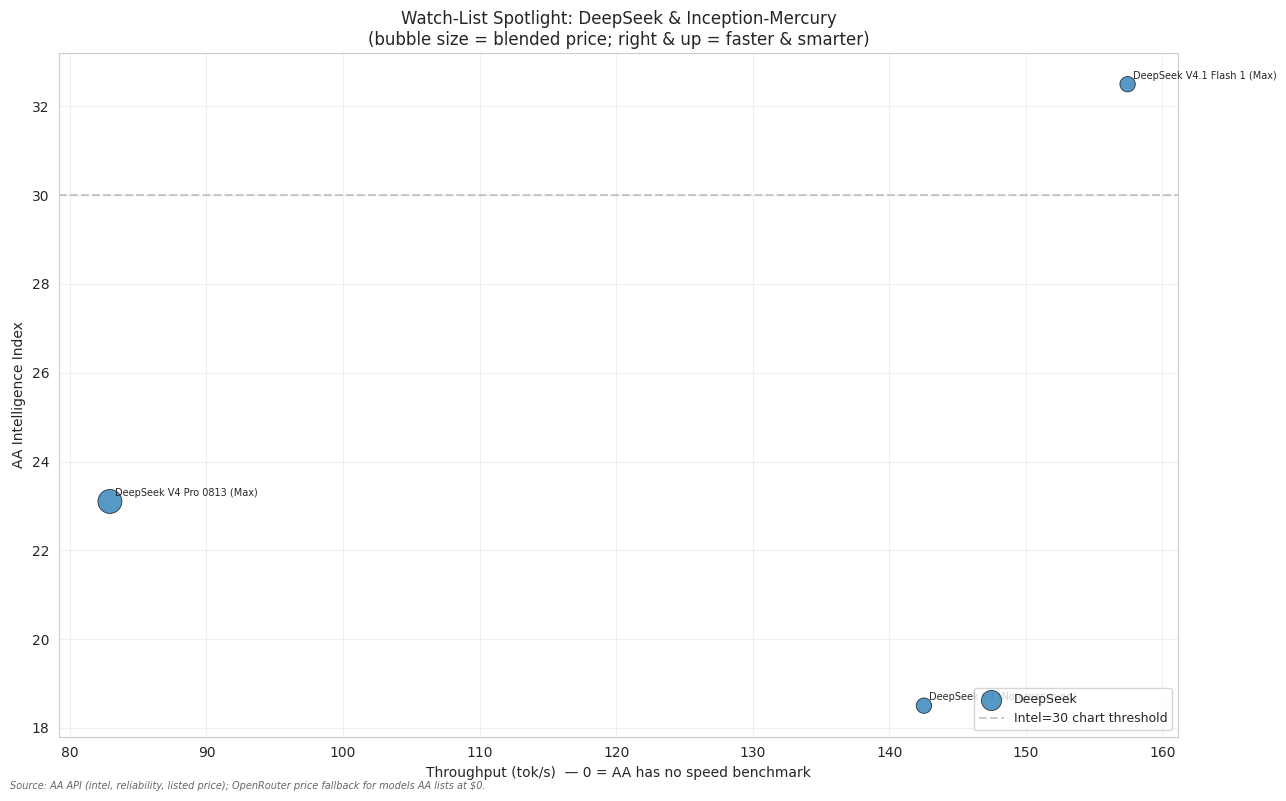


── STATUS OF REQUESTED MODELS ──
  ✅ DeepSeek V4.1 Flash    -> AA 'DeepSeek V4.1 Flash 1017 (Max)' | Intel=32.5 | Tput=157.452 | Price=$0.525/M
  ✅ DeepSeek V4 Pro        -> AA 'DeepSeek V4 Pro 0813 (Max)' | Intel=23.1 | Tput=82.927 | Price=$1.980/M
  ❌ DeepSeek V4.1 Pro      -> NOT FOUND (does not exist on OpenRouter or AA)


In [8]:
# ============================================================================
# 2.3 WATCH-LIST SPOTLIGHT: DeepSeek / Inception-Mercury — always visible
# ============================================================================
# The efficiency charts (3.1-3.6) show only the TOP-N by score, so a specific
# model the user cares about can fall below the cutoff and "disappear".
# This cell ALWAYS surfaces every DeepSeek and Inception/Mercury model with its
# real AA data + a dedicated plot, independent of rank or the Intel>30 filter.
#
# Naming note (verified against both catalogs 2026-10-16):
#   - "DeepSeek V4.1 Flash"  = deepseek/deepseek-v4.1-flash  (AA intel 39.5)  EXISTS
#   - "DeepSeek V4 Pro"      = deepseek/deepseek-v4-pro-0813 (AA intel 36.0)  EXISTS
#   - "DeepSeek V4.1 Pro"    = DOES NOT EXIST on OpenRouter or AA (no such model)
# ============================================================================

import re as _sre
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

# Rebuild from df_orig (raw AA data) so this cell works even if the appendix
# cells have overwritten the `df` variable with resume-benchmark data.
_src = df_orig.copy() if 'df_orig' in globals() else df.copy()
if 'Model' not in _src.columns and 'name' in _src.columns:
    _src = _src.rename(columns={'name': 'Model'})

# Recompute the derived columns this cell needs (same logic as the data-load cell)
_src['AA_Intelligence_Index'] = pd.to_numeric(
    _src.get('evaluations_artificial_analysis_intelligence_index'), errors='coerce')
_src['Price_Blended_USD_per_1M'] = pd.to_numeric(
    _src.get('pricing_price_1m_blended_3_to_1'), errors='coerce').fillna(0)
if 'evaluations_ifbench' in _src.columns:
    _src['AA_Hallucination_Rate'] = 1 - pd.to_numeric(_src['evaluations_ifbench'], errors='coerce')
    if 'evaluations_hle' in _src.columns:
        _src['AA_Hallucination_Rate'] = _src['AA_Hallucination_Rate'].fillna(
            1 - pd.to_numeric(_src['evaluations_hle'], errors='coerce'))
else:
    _src['AA_Hallucination_Rate'] = np.nan

# Pull every watch-list model
_watch_pat = _sre.compile(r'deepseek|inception|mercury', _sre.I)
_spot = _src[_src['Model'].astype(str).str.contains(_watch_pat, na=False)].copy()

if _spot.empty:
    print("No DeepSeek / Inception / Mercury models found in the AA data.")
else:
    # Real throughput: AA returns 0 for un-benchmarked rows -> treat as NaN
    _spot['Tput'] = pd.to_numeric(_spot.get('median_output_tokens_per_second'), errors='coerce')
    _spot['Tput'] = _spot['Tput'].where(_spot['Tput'] > 0, np.nan)
    _spot['Intel'] = pd.to_numeric(_spot['AA_Intelligence_Index'], errors='coerce')
    _spot['Price'] = pd.to_numeric(_spot['Price_Blended_USD_per_1M'], errors='coerce')
    _spot['Hall'] = pd.to_numeric(_spot.get('AA_Hallucination_Rate'), errors='coerce')
    _spot['Reliab'] = (1 - _spot['Hall']).clip(lower=0.0)

    # Multiplicative efficiency (same formula as 3.4) — NaN if no speed data
    _spot['Eff_Mult'] = (
        np.sqrt(_spot['Tput'].clip(lower=0.01)) * _spot['Intel'] * _spot['Reliab']
    ) / _spot['Price']

    # Chart eligibility: Intel>30 AND price>0 AND has speed data
    _spot['In_Charts'] = (
        (_spot['Intel'] > 30) & (_spot['Price'] > 0) & _spot['Tput'].notna()
    )

    _spot = _spot.sort_values('Intel', ascending=False)

    print("=" * 118)
    print("WATCH-LIST SPOTLIGHT — DeepSeek / Inception-Mercury (all rows, real AA data)")
    print("=" * 118)
    print(f"{'Model':<40} {'Intel':>6} {'Tput':>8} {'Price':>8} {'Reliab':>8} {'Eff':>10}  In charts?")
    print("-" * 118)
    for _, r in _spot.iterrows():
        tput_s = f"{r['Tput']:.1f}" if pd.notna(r['Tput']) else "n/a"
        eff_s = f"{r['Eff_Mult']:.1f}" if pd.notna(r['Eff_Mult']) else "n/a"
        rel_s = f"{r['Reliab']:.1%}" if pd.notna(r['Reliab']) else "n/a"
        why = "YES" if r['In_Charts'] else (
            "no (Intel<=30)" if not (r['Intel'] > 30) else
            ("no (price<=0)" if not (r['Price'] > 0) else "no (no speed data)")
        )
        print(f"{r['Model']:<40} {r['Intel']:>6.1f} {tput_s:>8} {r['Price']:>8.3f} {rel_s:>8} {eff_s:>10}  {why}")

    # ── Dedicated plot: Intel vs Throughput, bubble = price, color = family ──
    _plot = _spot.dropna(subset=['Intel']).copy()
    if not _plot.empty:
        def _fam(n):
            n = str(n).lower()
            if 'deepseek' in n: return 'DeepSeek'
            if 'mercury' in n or 'inception' in n: return 'Inception/Mercury'
            return 'Other'
        _plot['Family'] = _plot['Model'].map(_fam)

        fig, ax = plt.subplots(figsize=(13, 8))
        for fam, g in _plot.groupby('Family'):
            x = g['Tput'].fillna(0)  # NaN speed -> park at 0 (left edge)
            ax.scatter(x, g['Intel'],
                       s=(g['Price'].fillna(0.5) * 120) + 60,
                       alpha=0.75, label=fam, edgecolors='black', linewidth=0.6)
            for _, r in g.iterrows():
                short = fam_label(r['Model'], 26)
                ax.annotate(short, (r['Tput'] if pd.notna(r['Tput']) else 0, r['Intel']),
                            xytext=(4, 4), textcoords='offset points', fontsize=7)

        ax.set_xlabel('Throughput (tok/s)  — 0 = AA has no speed benchmark')
        ax.set_ylabel('AA Intelligence Index')
        ax.set_title('Watch-List Spotlight: DeepSeek & Inception-Mercury\n(bubble size = blended price; right & up = faster & smarter)')
        ax.axhline(30, color='gray', ls='--', alpha=0.4, label='Intel=30 chart threshold')
        ax.grid(alpha=0.3)
        ax.legend(loc='lower right', fontsize=9)
        plt.tight_layout()
        note_source(SRC_AA_OR)   # intel/reliability AA; price AA + OpenRouter fallback
        plt.show()

    # ── Explicit status of the models the user asked about ──
    print("\n── STATUS OF REQUESTED MODELS ──")
    for want in ['DeepSeek V4.1 Flash', 'DeepSeek V4 Pro', 'DeepSeek V4.1 Pro']:
        hit = _spot[_spot['Model'].astype(str).str.contains(_sre.escape(want), case=False, na=False)]
        if len(hit):
            r = hit.iloc[0]
            print(f"  ✅ {want:<22} -> AA '{r['Model']}' | Intel={r['Intel']:.1f} | "
                  f"Tput={r['Tput'] if pd.notna(r['Tput']) else 'n/a'} | Price=${r['Price']:.3f}/M")
        else:
            print(f"  ❌ {want:<22} -> NOT FOUND (does not exist on OpenRouter or AA)")

## 3. Filter Models by Intelligence Threshold
Filter the dataset to include only models with an intelligence score above 35.

In [9]:
# Standard Model Filtering for Visualization
intelligence_threshold = 30
df_filtered = df[(df['AA_Intelligence_Index'] > intelligence_threshold) & (df['Price_Blended_USD_per_1M'] > 0)].copy()

# compute cost index if missing
if 'Cost_to_Run_Index' not in df_filtered.columns:
    df_filtered['Cost_to_Run_Index'] = df_filtered['AA_Intelligence_Index'] * df_filtered['Price_Blended_USD_per_1M']

# Ensure we have the top models including o3, gemini 3.1, and the requested qwen 3.5
# qwen_search = df_filtered[df_filtered['Model'].str.contains('Qwen 3.5|Qwen3.5', case=False, na=False)]
# print(f"Found {len(qwen_search)} Qwen 3.5 models")

# Sort and take top performers
df_filtered = df_filtered.sort_values('AA_Intelligence_Index', ascending=False).head(40)



print(f"Dataset filtered to Top {len(df_filtered)} models with Intelligence > {intelligence_threshold}.")
print(df_filtered[['Model', 'AA_Intelligence_Index', 'Price_Blended_USD_per_1M']].head(10))

Dataset filtered to Top 40 models with Intelligence > 30.
                                       Model  AA_Intelligence_Index  \
0                     Gemini 4 Carbon (High)                   59.4   
1    Claude Opus 5.5 (Max, Default Fallback)                   58.4   
2  Claude Opus 5.5 (Xhigh, Default Fallback)                   57.0   
3                          GPT-6 Astra (Max)                   56.9   
4                        GPT-6 Astra (Xhigh)                   55.3   
5                         GPT-6 Astra (High)                   54.8   
6                          GPT-6.1 Sol (Max)                   54.5   
7  Claude Sonnet 5.5 (Max, Default Fallback)                   54.2   
8                        GPT-6.1 Sol (Xhigh)                   52.3   
9   Claude Opus 5.5 (High, Default Fallback)                   51.7   

   Price_Blended_USD_per_1M  
0                       8.0  
1                       8.0  
2                       8.0  
3                      20.0  
4         

## 3.1 Intelligence to Cost Ratio


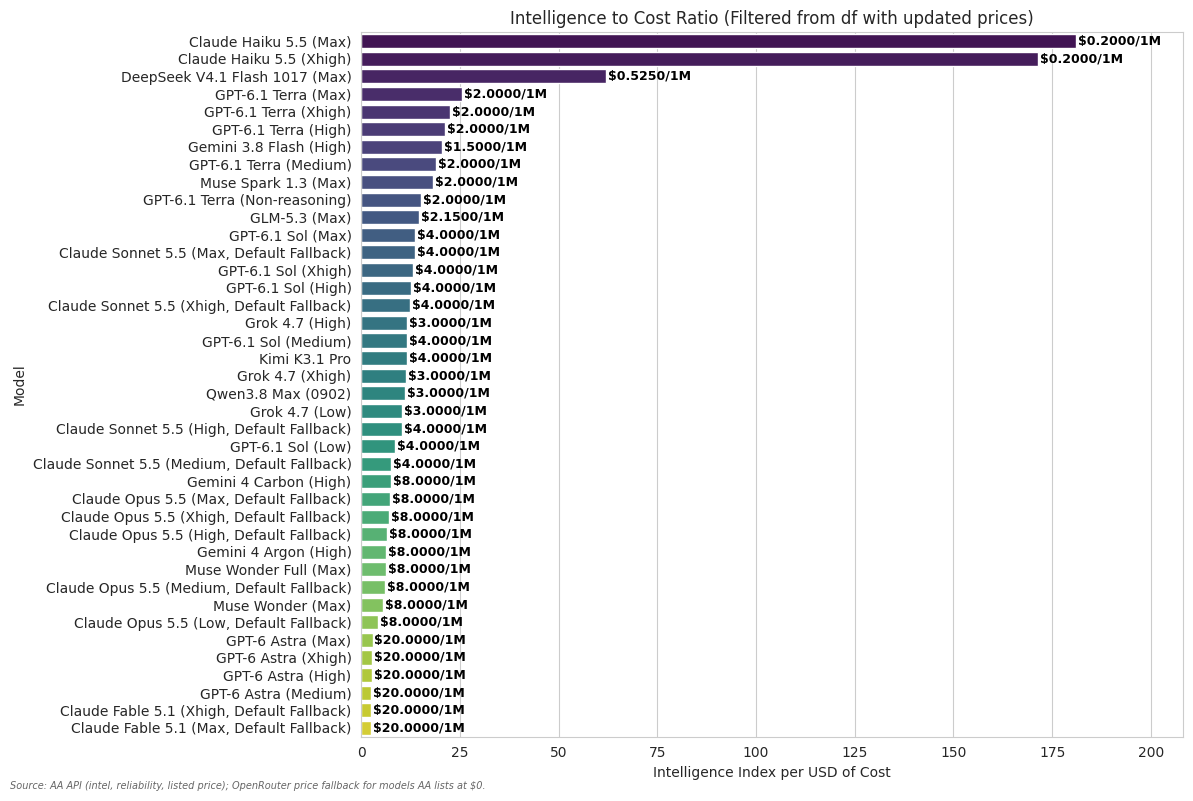

Chart shows 40 models with Intel > 30
  ❌ MiniMax-M3 NOT in chart — checking df...
     In df: Intel=28.9 (>30? False), Price=$0.2625 (>0? True)

Top 10 by Intel/Cost ratio:
                         Model  AA_Intelligence_Index  Price_Blended_USD_per_1M  Intelligence_to_Cost_Ratio
        Claude Haiku 5.5 (Max)                   36.2                     0.200                  181.000000
      Claude Haiku 5.5 (Xhigh)                   34.3                     0.200                  171.500000
DeepSeek V4.1 Flash 1017 (Max)                   32.5                     0.525                   61.904762
           GPT-6.1 Terra (Max)                   51.0                     2.000                   25.500000
         GPT-6.1 Terra (Xhigh)                   45.0                     2.000                   22.500000
          GPT-6.1 Terra (High)                   42.3                     2.000                   21.150000
       Gemini 3.8 Flash (High)                   30.5                 

In [10]:
# ## 3.1 Intelligence to Cost Ratio
# Re-filter directly from df (which has updated prices) so price fallbacks are included
INTEL_THRESHOLD = 30
df_plot_31 = df[(df['AA_Intelligence_Index'] > INTEL_THRESHOLD) & (df['Price_Blended_USD_per_1M'] > 0)].copy()
df_plot_31['Intelligence_to_Cost_Ratio'] = (
    df_plot_31['AA_Intelligence_Index'] / df_plot_31['Price_Blended_USD_per_1M']
)
df_plot_31 = df_plot_31.sort_values('Intelligence_to_Cost_Ratio', ascending=False).head(40)

plt.figure(figsize=(12, 8))
ax = sns.barplot(
    x='Intelligence_to_Cost_Ratio',
    y='Model',
    data=df_plot_31,
    palette='viridis'
)

# Add price labels to each bar
for i, (p, price) in enumerate(zip(ax.patches, df_plot_31['Price_Blended_USD_per_1M'])):
    ax.text(
        p.get_width() + 0.5, 
        p.get_y() + p.get_height()/2, 
        f'${price:.4f}/1M', 
        va='center', 
        fontsize=9, 
        fontweight='bold',
        color='black'
    )

plt.title('Intelligence to Cost Ratio (Filtered from df with updated prices)')
plt.xlabel('Intelligence Index per USD of Cost')
plt.ylabel('Model')
plt.xlim(0, df_plot_31['Intelligence_to_Cost_Ratio'].max() * 1.15)
plt.tight_layout()
note_source(SRC_AA_OR)   # intel/reliability AA; price AA + OpenRouter fallback
plt.show()

print(f"Chart shows {len(df_plot_31)} models with Intel > {INTEL_THRESHOLD}")

# Quick sanity check: verify MiniMax-M3 is in the chart
m3 = df_plot_31[df_plot_31['Model'].str.contains('MiniMax-M3', case=False, na=False)]
if len(m3) > 0:
    r = m3.iloc[0]
    print(f"  ✅ MiniMax-M3: Intel={r['AA_Intelligence_Index']:.1f}, Price=${r['Price_Blended_USD_per_1M']:.4f}, Ratio={r['Intelligence_to_Cost_Ratio']:.1f}")
else:
    print("  ❌ MiniMax-M3 NOT in chart — checking df...")
    m3d = df[df['Model'].str.contains('MiniMax-M3', case=False, na=False)]
    if len(m3d) > 0:
        r = m3d.iloc[0]
        intel_ok = r['AA_Intelligence_Index'] > INTEL_THRESHOLD
        price_ok = r['Price_Blended_USD_per_1M'] > 0
        print(f"     In df: Intel={r['AA_Intelligence_Index']:.1f} (>30? {intel_ok}), Price=${r['Price_Blended_USD_per_1M']:.4f} (>0? {price_ok})")

# Also show notable models that would rank high
print(f"\nTop 10 by Intel/Cost ratio:")
print(df_plot_31[['Model','AA_Intelligence_Index','Price_Blended_USD_per_1M','Intelligence_to_Cost_Ratio']].head(10).to_string(index=False))

## 3.2 Ratio with Intelligence Exponent (Intel^2 / Cost)


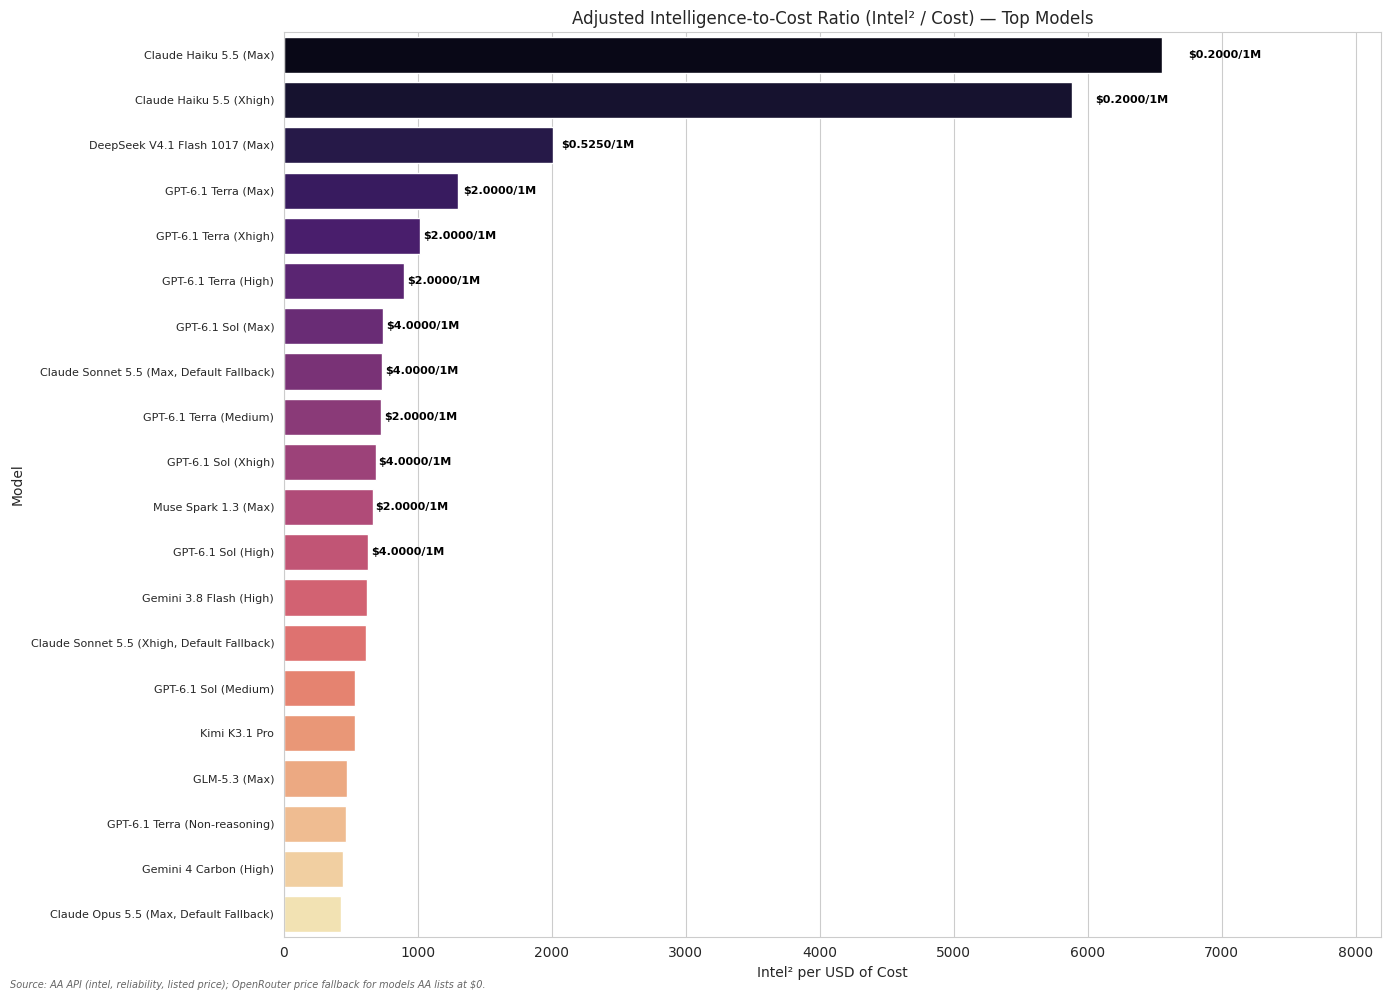

MiniMax-M3 in chart: ❌


In [11]:
# ## 3.2 Ratio with Intelligence Exponent (Intel^2 / Cost)
# Re-filter from df to pick up updated prices
df_plot_32 = df[(df['AA_Intelligence_Index'] > 30) & (df['Price_Blended_USD_per_1M'] > 0)].copy()
df_plot_32['Intel_Adjusted_Ratio'] = (
    df_plot_32['AA_Intelligence_Index'] ** 2
) / df_plot_32['Price_Blended_USD_per_1M']
df_plot_32 = df_plot_32.sort_values('Intel_Adjusted_Ratio', ascending=False)

# Plot only the top N
TOP_N = 20
df_plot = df_plot_32.head(TOP_N).copy()

# Dynamic figure height so labels fit
fig_h = max(6, 0.35 * len(df_plot) + 3)
fig, ax = plt.subplots(figsize=(14, fig_h))

sns.barplot(
    x='Intel_Adjusted_Ratio',
    y='Model',
    data=df_plot,
    palette='magma',
    ax=ax
)

# Add price labels
LABEL_TOP_K = 12
for i, p in enumerate(ax.patches):
    if i >= LABEL_TOP_K:
        break
    price = df_plot.iloc[i]['Price_Blended_USD_per_1M']
    ax.text(
        p.get_width() + p.get_width() * 0.03,
        p.get_y() + p.get_height() / 2,
        f'${price:.4f}/1M',
        va='center',
        fontsize=8,
        fontweight='bold',
        color='black'
    )

ax.set_title('Adjusted Intelligence-to-Cost Ratio (Intel² / Cost) — Top Models')
ax.set_xlabel('Intel² per USD of Cost')
ax.set_ylabel('Model')
ax.tick_params(axis='y', labelsize=8)
xmax = float(df_plot['Intel_Adjusted_Ratio'].max())
ax.set_xlim(0, xmax * 1.25 if xmax > 0 else 1)
fig.tight_layout()
note_source(SRC_AA_OR)
plt.show()

# Verify MiniMax-M3 presence
m3 = df_plot_32[df_plot_32['Model'].str.contains('MiniMax-M3', case=False, na=False)]
print(f"MiniMax-M3 in chart: {'✅' if len(m3) > 0 else '❌'}")
if len(m3) > 0:
    r = m3.iloc[0]
    print(f"  Intel²/Cost ratio = {r['Intel_Adjusted_Ratio']:.1f}")

## 3.3 Throughput-Weighted Intelligence Efficiency (Additive)


Throughput: 43 with data (0 family-imputed), 1 still missing (kept as NaN)
Excluded 1 models with no throughput data (AA never benchmarked their speed).


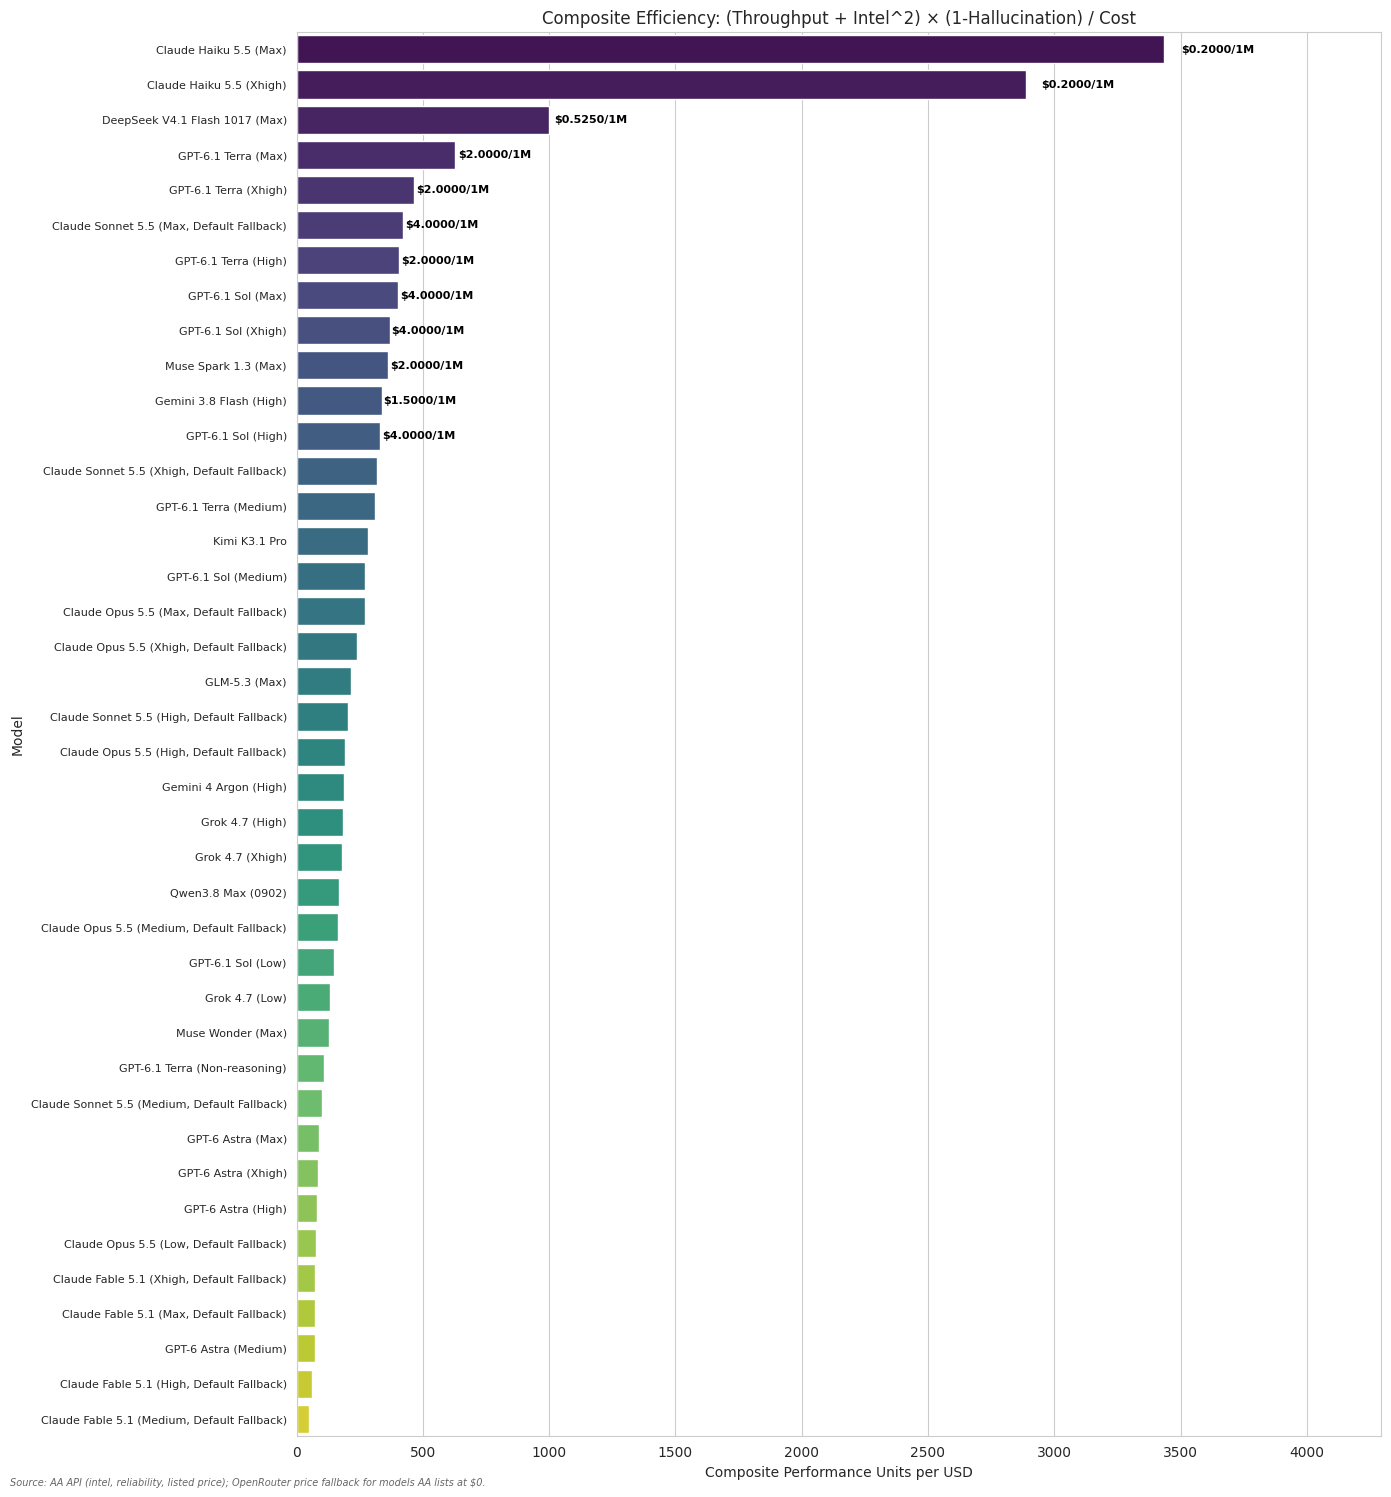

Top Models by Composite Efficiency (Intel > 30):
                                      Model  Composite_Efficiency  Throughput  AA_Intelligence_Index  Intel_Power  AA_Hallucination_Rate  Price_Blended_USD_per_1M
                     Claude Haiku 5.5 (Max)           3434.990460     236.853                   36.2      1310.44                  0.556                     0.200
                   Claude Haiku 5.5 (Xhigh)           2888.911200     176.630                   34.3      1176.49                  0.573                     0.200
             DeepSeek V4.1 Flash 1017 (Max)           1001.015173     157.452                   32.5      1056.25                  0.567                     0.525
                        GPT-6.1 Terra (Max)            628.698840     120.640                   51.0      2601.00                  0.538                     2.000
                      GPT-6.1 Terra (Xhigh)            465.332240     104.667                   45.0      2025.00                  0.563

In [12]:
# ## 3.3 Throughput-weighted Intelligence Efficiency (Additive)
# Composite: (Throughput + Intel^2) * (1 - hallucination) / blended_cost
# Re-filter from df to include all price-fallback models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
cost_col = 'Price_Blended_USD_per_1M'

# Work on ALL rows first (imputation population must match 3.4, so the same
# model gets the SAME family-median imputed values in both sections), then
# apply the Intel>30 / price>0 filter at the end.
_df = df.copy()

# Ensure Model column
if 'Model' not in _df.columns:
    if 'name' in _df.columns:
        _df = _df.rename(columns={'name': 'Model'})
    elif 'model' in _df.columns:
        _df = _df.rename(columns={'model': 'Model'})

# Coerce numeric
_df['AA_Intelligence_Index'] = pd.to_numeric(_df['AA_Intelligence_Index'], errors='coerce')
if 'AA_Hallucination_Rate' not in _df.columns:
    if 'evaluations_ifbench' in _df.columns:
        _df['AA_Hallucination_Rate'] = 1 - pd.to_numeric(_df['evaluations_ifbench'], errors='coerce')
    else:
        _df['AA_Hallucination_Rate'] = np.nan
# Keep missing hallucination data as NaN (family-imputed below), don't fake 0.1
_df[cost_col] = pd.to_numeric(_df[cost_col], errors='coerce')

# Throughput
# AA returns a literal 0 for models it never speed-benchmarked — treat <=0 as
# MISSING, not real zero speed (same fix as section 3.4).
thr = _df.get('median_output_tokens_per_second', pd.Series(np.nan, index=_df.index))
_df['Throughput_raw'] = pd.to_numeric(thr, errors='coerce')
_df['Throughput'] = _df['Throughput_raw'].where(_df['Throughput_raw'] > 0, np.nan)
_df['Throughput_Imputed'] = False

# ── Family-level imputation (same key AND same population as 3.4) ──
import re as _re
_TPUT_SUFFIX = _re.compile(r'\s*\([^)]*\)\s*$')

def _family_key(name):
    if not isinstance(name, str):
        return ''
    base = _TPUT_SUFFIX.sub('', name).strip().lower()
    base = _re.sub(r'\s*\d{4}\s*$', '', base)
    base = _re.sub(r'\b(preview|beta|adaptive)\b', '', base).strip()
    toks = [t for t in base.split() if not _re.match(r'^\d+\.\d+$', t)]
    return ' '.join(toks[:3])

_family_tput = _df.groupby(_df['Model'].map(_family_key))['Throughput'].median()
_missing_mask = _df['Throughput'].isna()
_family_hit = _df['Model'].map(_family_key).map(_family_tput)
_imp_mask = _missing_mask & _family_hit.notna()
_df.loc[_imp_mask, 'Throughput'] = _family_hit[_imp_mask]
_df.loc[_imp_mask, 'Throughput_Imputed'] = True

_df['Intel_Power'] = _df['AA_Intelligence_Index'] ** 2

# Reliability: NaN stays NaN, family-imputed (no fake 0.1 / 100% halluc)
_df['Reliability_Factor'] = (1 - _df['AA_Hallucination_Rate']).clip(lower=0.0)
_df['Reliability_Imputed'] = False
_rel_missing = _df['Reliability_Factor'].isna()
_rel_family = _df.groupby(_df['Model'].map(_family_key))['Reliability_Factor'].median()
_rel_hit = _df['Model'].map(_family_key).map(_rel_family)
_rel_imp = _rel_missing & _rel_hit.notna()
_df.loc[_rel_imp, 'Reliability_Factor'] = _rel_hit[_rel_imp]
_df.loc[_rel_imp, 'Reliability_Imputed'] = True

# ── NOW apply the core filter (consistent with 3.4) ──
_df = _df[(_df[cost_col] > 0) & (_df['AA_Intelligence_Index'] > 30)].copy()

print(f"Throughput: {int(_df['Throughput'].notna().sum())} with data "
      f"({int(_df['Throughput_Imputed'].sum())} family-imputed), "
      f"{int(_df['Throughput'].isna().sum())} still missing (kept as NaN)")

# Composite — NaN throughput yields NaN score (row excluded from chart)
_df['Composite_Efficiency'] = (
    (_df['Throughput'] + _df['Intel_Power']) * _df['Reliability_Factor']
) / _df[cost_col]

n_no_tput = int(_df['Throughput'].isna().sum())
if n_no_tput:
    print(f"Excluded {n_no_tput} models with no throughput data (AA never benchmarked their speed).")

_df = _df.sort_values('Composite_Efficiency', ascending=False)

TOP_N = 40
df_plot = _df[_df['Throughput'].notna()].head(TOP_N).copy()

# Plot
fig_h = max(6, 0.30 * len(df_plot) + 3)
fig, ax = plt.subplots(figsize=(14, fig_h))

sns.barplot(
    x='Composite_Efficiency',
    y='Model',
    data=df_plot,
    palette='viridis',
    ax=ax,
)

LABEL_TOP_K = 12
for i, (p, intel_p, eff, price) in enumerate(
    zip(ax.patches, df_plot['Intel_Power'], df_plot['Composite_Efficiency'], df_plot[cost_col])
):
    if i >= LABEL_TOP_K:
        break
    ax.text(
        p.get_width() + p.get_width() * 0.02,
        p.get_y() + p.get_height() / 2,
        f'${price:.4f}/1M',
        va='center',
        fontsize=8,
        fontweight='bold',
        color='black',
    )

ax.set_title('Composite Efficiency: (Throughput + Intel^2) × (1-Hallucination) / Cost')
ax.set_xlabel('Composite Performance Units per USD')
ax.set_ylabel('Model')
ax.tick_params(axis='y', labelsize=8)
ax.set_xlim(0, float(df_plot['Composite_Efficiency'].max()) * 1.25)

plt.tight_layout()
note_source(SRC_AA_OR)
plt.show()

print('Top Models by Composite Efficiency (Intel > 30):')
cols = ['Model','Composite_Efficiency','Throughput','AA_Intelligence_Index','Intel_Power','AA_Hallucination_Rate',cost_col]
print(_df[_df['Throughput'].notna()][cols].head(15).to_string(index=False))

## 3.4 Multiplicative Intelligence Efficiency (sqrt(Throughput) × Intel)
Combine sqrt of token throughput with raw intelligence score, multiply them,
then divide by cost. Penalize for Hallucination Rate by using (1 - Hallucination_Rate) as a multiplier.

Formula: (sqrt(Throughput) × Intel) × (1 - Hallucination) / Cost

This differs from 3.3 by:
- Using sqrt(Throughput) instead of raw Throughput (diminishing returns on speed)
- Using raw Intel instead of Intel^2 (linear intelligence contribution)
- Multiplying instead of adding (both must be good to score well)

Throughput: 253 with data (92 family-imputed), 466 still missing (kept as NaN)
Reliability: 0 family-imputed, 1 still missing (kept as NaN)
Excluded 1 models with no throughput data (AA never benchmarked their speed).


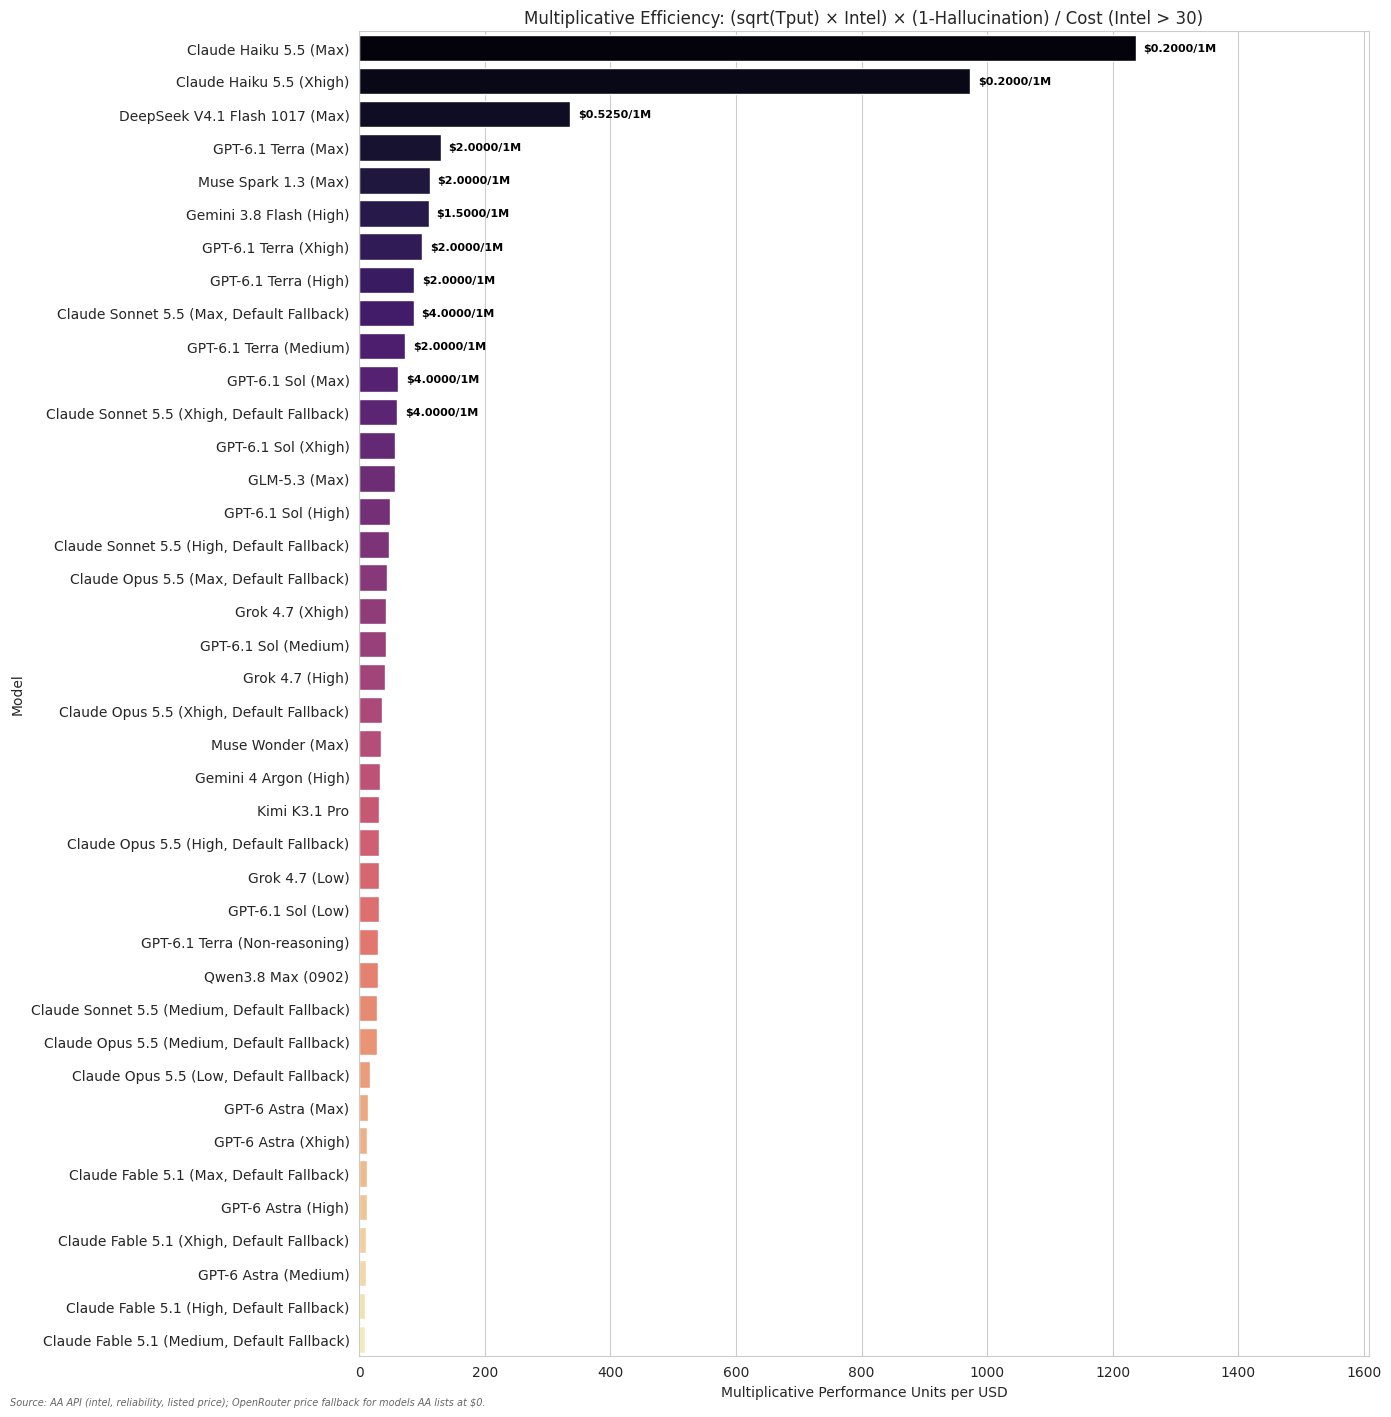

Top Models by Multiplicative Efficiency (Intel > 30):
                                      Model  Composite_Efficiency_Mult  Throughput_Sqrt  AA_Intelligence_Index  AA_Hallucination_Rate  Price_Blended_USD_per_1M
                     Claude Haiku 5.5 (Max)                1236.804310        15.390029                   36.2                  0.556                     0.200
                   Claude Haiku 5.5 (Xhigh)                 973.249600        13.290222                   34.3                  0.573                     0.200
             DeepSeek V4.1 Flash 1017 (Max)                 336.345828        12.547988                   32.5                  0.567                     0.525
                        GPT-6.1 Terra (Max)                 129.398076        10.983624                   51.0                  0.538                     2.000
                       Muse Spark 1.3 (Max)                 112.463938        12.688578                   36.4                  0.513             

In [13]:
# ## 3.4 Multiplicative Intelligence Efficiency (sqrt(Throughput) × Intel)
# Formula: (sqrt(Throughput) * Intel) * (1 - Hallucination) / Cost
# Key differences from 3.3:
#   - sqrt(Throughput) instead of raw (linear speed contribution)
#   - Intel instead of Intel^2  (linear intelligence contribution)
#   - Multiply instead of add (both dimensions must be strong)

# Always rebuild df_comp safely from df and compute missing Throughput.
df_comp = df.copy()

# Ensure Model column
if 'Model' not in df_comp.columns and 'name' in df_comp.columns:
    df_comp = df_comp.rename(columns={'name': 'Model'})

# Ensure intelligence
if 'AA_Intelligence_Index' not in df_comp.columns:
    df_comp['AA_Intelligence_Index'] = df_comp.get(
        'evaluations_artificial_analysis_intelligence_index',
        df_comp.get('evaluations_artificial_analysis_intelligence', np.nan),
    )

# Ensure hallucination proxy (keep missing as NaN — imputed below from family)
if 'AA_Hallucination_Rate' not in df_comp.columns:
    if 'evaluations_ifbench' in df_comp.columns:
        df_comp['AA_Hallucination_Rate'] = 1 - pd.to_numeric(df_comp['evaluations_ifbench'], errors='coerce')
    else:
        df_comp['AA_Hallucination_Rate'] = 0.1

# Ensure blended cost
cost_col = 'Price_Blended_USD_per_1M'
if cost_col not in df_comp.columns:
    pin = df_comp.get('Price_Input_1M', df_comp.get('pricing_price_1m_input_tokens', np.nan))
    pout = df_comp.get('Price_Output_1M', df_comp.get('pricing_price_1m_output_tokens', np.nan))
    pin = pd.to_numeric(pin, errors='coerce')
    pout = pd.to_numeric(pout, errors='coerce')
    derived = (pin * 3 + pout) / 4

    api_blended = pd.to_numeric(df_comp.get('pricing_price_1m_blended_3_to_1', np.nan), errors='coerce')
    df_comp[cost_col] = derived.where((derived > 0) & (~derived.isna()), api_blended)

# Coerce types
for c in ['AA_Intelligence_Index', 'AA_Hallucination_Rate', cost_col]:
    if c in df_comp.columns:
        df_comp[c] = pd.to_numeric(df_comp[c], errors='coerce')

# Ensure Throughput exists
# AA returns a literal 0 for models it never speed-benchmarked (mostly effort/
# reasoning variant rows), so treat <=0 as MISSING, not as real zero speed.
median_thr = df_comp.get('median_output_tokens_per_second', pd.Series(np.nan, index=df_comp.index))
df_comp['Throughput_raw'] = pd.to_numeric(median_thr, errors='coerce')
df_comp['Throughput'] = df_comp['Throughput_raw'].where(df_comp['Throughput_raw'] > 0, np.nan)
df_comp['Throughput_Imputed'] = False

# ── Family-level imputation ──
# Group variants into a base family (e.g. "Gemini 3.8 Flash (Medium)" ->
# "gemini flash") and fill missing throughput with the family median.
# Rows with no family speed data anywhere in the API stay NaN (true missing).
import re as _re
_TPUT_SUFFIX = _re.compile(r'\s*\([^)]*\)\s*$')

def _family_key(name):
    if not isinstance(name, str):
        return ''
    base = _TPUT_SUFFIX.sub('', name).strip().lower()          # drop (Max)/(Xhigh)/...
    base = _re.sub(r'\s*\d{4}\s*$', '', base)                  # drop date suffixes
    base = _re.sub(r'\b(preview|beta|adaptive)\b', '', base).strip()
    toks = [t for t in base.split() if not _re.match(r'^\d+\.\d+$', t)]  # drop minor versions
    return ' '.join(toks[:3])

_family_tput = df_comp.groupby(df_comp['Model'].map(_family_key))['Throughput'].median()
_missing_mask = df_comp['Throughput'].isna()
_family_hit = df_comp['Model'].map(_family_key).map(_family_tput)
_imp_mask = _missing_mask & _family_hit.notna()
df_comp.loc[_imp_mask, 'Throughput'] = _family_hit[_imp_mask]
df_comp.loc[_imp_mask, 'Throughput_Imputed'] = True

print(f"Throughput: {int(df_comp['Throughput'].notna().sum())} with data "
      f"({int(df_comp['Throughput_Imputed'].sum())} family-imputed), "
      f"{int(df_comp['Throughput'].isna().sum())} still missing (kept as NaN)")

# Apply core filter (consistency)
df_comp = df_comp[(df_comp[cost_col] > 0) & (df_comp['AA_Intelligence_Index'] > 30)].copy()

# If empty, stop cleanly
if df_comp.empty:
    print('No models available for 3.4 after filtering (cost>0 and Intel>30).')
else:
    # Compute reliability
    # Missing IFBench/HLE stays NaN here — imputed below from the family median
    # instead of being faked into a 100% hallucination rate.
    df_comp['Reliability_Factor'] = (1 - df_comp['AA_Hallucination_Rate']).clip(lower=0.0)

    # ── Family-level reliability imputation ──
    # Same family key as throughput: fill missing reliability with the family
    # median so models without IFBench/HLE aren't scored as Reliability 0%.
    df_comp['Reliability_Imputed'] = False
    _rel_missing = df_comp['Reliability_Factor'].isna()
    _rel_family = df_comp.groupby(df_comp['Model'].map(_family_key))['Reliability_Factor'].median()
    _rel_hit = df_comp['Model'].map(_family_key).map(_rel_family)
    _rel_imp = _rel_missing & _rel_hit.notna()
    df_comp.loc[_rel_imp, 'Reliability_Factor'] = _rel_hit[_rel_imp]
    df_comp.loc[_rel_imp, 'Reliability_Imputed'] = True

    n_rel_missing = int(df_comp['Reliability_Factor'].isna().sum())
    n_rel_imp = int(df_comp['Reliability_Imputed'].sum())
    if n_rel_imp or n_rel_missing:
        print(f"Reliability: {n_rel_imp} family-imputed, {n_rel_missing} still missing (kept as NaN)")

    # Sqrt throughput — only for rows with real/imputed speed data.
    # Rows with NaN throughput are excluded from the multiplicative ranking
    # so they are visibly absent instead of silently scored as zero speed.
    df_comp['Throughput_Sqrt'] = np.where(
        df_comp['Throughput'].notna(),
        np.sqrt(df_comp['Throughput'].clip(lower=0.01)),
        np.nan,
    )

    # Multiplicative formula: (sqrt(T) * Intel) * Reliability / Cost
    df_comp['Composite_Efficiency_Mult'] = (
        (df_comp['Throughput_Sqrt'] * df_comp['AA_Intelligence_Index']) * df_comp['Reliability_Factor']
    ) / df_comp[cost_col]

    n_no_tput = int(df_comp['Throughput'].isna().sum())
    if n_no_tput:
        print(f"Excluded {n_no_tput} models with no throughput data (AA never benchmarked their speed).")

    # Sort and take top N (NaN throughput sorts to the bottom automatically)
    df_comp = df_comp.sort_values('Composite_Efficiency_Mult', ascending=False)
    df_plot_m = df_comp[df_comp['Throughput'].notna()].head(40).copy()

    plt.figure(figsize=(14, max(6, 0.28 * len(df_plot_m) + 3)))
    ax = sns.barplot(
        x='Composite_Efficiency_Mult',
        y='Model',
        data=df_plot_m,
        palette='magma',
    )

    # Limit labels to top few
    LABEL_TOP_K = 12
    max_eff = float(df_plot_m['Composite_Efficiency_Mult'].max()) if len(df_plot_m) else 1.0
    label_x_offset = max_eff * 0.01

    for i, (p, tp_sqrt, intel, eff, price) in enumerate(zip(
        ax.patches,
        df_plot_m['Throughput_Sqrt'],
        df_plot_m['AA_Intelligence_Index'],
        df_plot_m['Composite_Efficiency_Mult'],
        df_plot_m[cost_col],
    )):
        if i >= LABEL_TOP_K:
            break
        ax.text(
            p.get_width() + label_x_offset,
            p.get_y() + p.get_height() / 2,
            f'${price:.4f}/1M',
            va='center',
            fontsize=8,
            fontweight='bold',
            color='black',
        )

    plt.title('Multiplicative Efficiency: (sqrt(Tput) × Intel) × (1-Hallucination) / Cost (Intel > 30)')
    plt.xlabel('Multiplicative Performance Units per USD')
    plt.ylabel('Model')
    plt.xlim(0, max_eff * 1.3)
    plt.tight_layout()
    note_source(SRC_AA_OR)   # throughput: AA lab or OpenRouter-rescued (Throughput_Source)
    plt.show()

    print('Top Models by Multiplicative Efficiency (Intel > 30):')
    cols = ['Model','Composite_Efficiency_Mult','Throughput_Sqrt','AA_Intelligence_Index','AA_Hallucination_Rate',cost_col]
    print(df_comp[df_comp['Throughput'].notna()][cols].head(15).to_string(index=False))

In [14]:

# --- Additional analysis: Free models using OPENROUTER_API_KEY_1 ---
# Load key from environment (assumes .env file present)
from dotenv import load_dotenv
load_dotenv()
openrouter_key = os.getenv('OPENROUTER_API_KEY_1')
print(f"OpenRouter key loaded: {'found' if openrouter_key else 'NOT found'}")

# Fetch the official list of free models from OpenRouter API
free_model_ids = set()
if openrouter_key:
    try:
        resp = requests.get(
            "https://openrouter.ai/api/v1/models",
            headers={"Authorization": f"Bearer {openrouter_key}"}
        )
        resp.raise_for_status()
        models_data = resp.json().get('data', [])
        # Free models have ':free' suffix in their ID
        free_model_ids = {m['id'] for m in models_data if isinstance(m, dict) and m.get('id', '').endswith(':free')}
        print(f"Fetched {len(free_model_ids)} free model IDs from OpenRouter.")
    except Exception as e:
        print(f"Failed to fetch free models from OpenRouter: {e}")

# Always maintain a baseline set of known free models (March 2026 snapshot)
fallback_free_ids = {
    'qwen/qwen3-coder:free',
    'mistralai/devstral-2:free',
    'qwen/qwen3-next-80b-a3b-instruct:free',
    'deepseek/deepseek-r1-0528:free',
    'arcee-ai/trinity-large-preview:free',
    'liquid/lfm2.5-1.2b-thinking:free',
    'meta-llama/llama-3.3-70b-instruct:free',
    'openai/gpt-oss-120b:free',
    'openai/gpt-oss-20b:free',
    'nvidia/nemotron-3-nano-30b-a3b:free',
    'stepfun/step-3.5-flash:free',
    'z-ai/glm-4.5-air:free',
    'nousresearch/hermes-3-llama-3.1-405b:free',
    'meta-llama/llama-3.2-3b-instruct:free',
    'google/gemini-2.0-flash-exp:free',
    'google/gemma-3-27b-it:free',
    'qwen/qwen2.5-vl-7b-instruct:free',
    'nvidia/nemotron-nano-12b-v2-vl:free'
}
# union the fetched IDs with our fallback baseline so we don't lose any known free models
if free_model_ids:
    original_count = len(free_model_ids)
    free_model_ids = free_model_ids.union(fallback_free_ids)
    print(f"Merged fetched free IDs ({original_count}) with fallback list ({len(fallback_free_ids)}); total now {len(free_model_ids)}.")
else:
    # no IDs fetched, use fallback list and report
    free_model_ids = fallback_free_ids
    print(f"No IDs fetched, using fallback list of {len(free_model_ids)} free model IDs.")

# extra diagnostic: show any ids containing 'step' or 'flash'
print("IDs with step/flash:", [fid for fid in free_model_ids if 'step' in fid or 'flash' in fid])

# Map our df_orig to include a flag for free models based on model ID matching
# Our df_orig may have model names that correspond to these IDs; we need to match intelligently.
# The 'Model' column in df_orig likely contains names like "step-3.5-flash" or "Step-3.5-Flash" etc.
# We'll create a mapping from known ID patterns to potential name patterns.

# ensure df_orig has intelligence index
if 'AA_Intelligence_Index' not in df_orig.columns:
    df_orig['AA_Intelligence_Index'] = df_orig.get('evaluations_artificial_analysis_intelligence_index', np.nan)


def is_free_model(model_name):
    """Check if a model name corresponds to a free model from OpenRouter."""
    if not isinstance(model_name, str):
        return False
    name_lower = model_name.lower()
    # Check direct matches with ID fragments
    for fid in free_model_ids:
        # Extract the model part before :free, e.g., 'stepfun/step-3.5-flash'
        id_part = fid.replace(':free', '').lower()
        # Match if the model name contains the id_part (without provider prefix sometimes)
        if id_part in name_lower:
            return True
        # Also match just the model name part (after last slash)
        model_part = id_part.split('/')[-1]
        if model_part and model_part in name_lower:
            return True
    return False

# diagnostic: look for models containing flash or step
flash_models = df_orig[df_orig['Model'].str.contains('flash|step', case=False, na=False)]
print("Models containing 'flash' or 'step':")
print(flash_models[['Model','AA_Intelligence_Index']].drop_duplicates().to_string())

# Apply the filter on df_orig
df_free = df_orig.copy()
df_free['Is_Free'] = df_free['Model'].apply(is_free_model)

# Also enforce intelligence > 30 to mirror df_comp filtering
# (already computed above)
df_free = df_free[df_free['AA_Intelligence_Index'] > 30]

# Keep only free models
df_free = df_free[df_free['Is_Free']].copy()

print(f"Identified {len(df_free)} free models with intelligence > 30 from OpenRouter list.")

# Compute metrics for free models (without dividing by cost, since they are free)
if not df_free.empty:
    # Ensure required columns exist
    # AA returns 0 for un-benchmarked models: treat as missing, not zero speed
    df_free['Throughput'] = pd.to_numeric(df_free.get('median_output_tokens_per_second'), errors='coerce').where(lambda x: x > 0)
    _n_nt = int(df_free['Throughput'].isna().sum())
    df_free = df_free[df_free['Throughput'].notna()].copy()
    print(f"Free-model ranking excludes {_n_nt} models with no speed data")
    df_free['Intel_Power'] = df_free['AA_Intelligence_Index']
    if 'AA_Hallucination_Rate' not in df_free.columns:
        df_free['AA_Hallucination_Rate'] = 0.1
    df_free['Reliability_Factor'] = 1 - df_free['AA_Hallucination_Rate'].fillna(0.5)
    
    # For free models, we compute a "Free_Score" that is just the numerator (no cost division)
    # This represents raw capability weighted by reliability
    df_free['Free_Score'] = (np.sqrt(df_free['Throughput']) + df_free['Intel_Power']) * df_free['Reliability_Factor']
    
    # Sort by this score
    df_free = df_free.sort_values('Free_Score', ascending=False)
    
    # Plot
    plt.figure(figsize=(10, 6))
    sns.barplot(
        x='Free_Score',
        y='Model',
        data=df_free,
        palette='coolwarm'
    )
    plt.title('Free Model Capability Score (Intelligence > 30)\nNo cost division - raw performance potential')
    plt.xlabel('Free Score (sqrt(Throughput) + Intelligence) * Reliability')
    plt.ylabel('Model')
    plt.tight_layout()
    note_source(SRC_AA_OR)   # throughput: AA lab or OpenRouter-rescued (Throughput_Source)
    plt.show()
    
    print("Free models capability ranking:")
    print(df_free[['Model', 'Free_Score', 'AA_Intelligence_Index', 'Throughput', 'AA_Hallucination_Rate']].to_string(index=False))

else:
    print("No free models identified in the dataset.")

OpenRouter key loaded: found
Fetched 14 free model IDs from OpenRouter.
Merged fetched free IDs (14) with fallback list (18); total now 32.
IDs with step/flash: ['google/gemini-2.0-flash-exp:free', 'stepfun/step-3.5-flash:free']
Models containing 'flash' or 'step':
                                                       Model  AA_Intelligence_Index
38                            DeepSeek V4.1 Flash 1017 (Max)                   32.5
41                                   Gemini 3.8 Flash (High)                   30.5
44                                 Gemini 3.8 Flash (Medium)                   30.0
47                                       Ling 3.1 Flash 1019                   29.5
49                                        MiniMax-M3.1-Flash                   28.9
50                                            Step 5 Preview                   28.5
52                                             GLM-5.3-Flash                   27.8
53                                           MiMo-V2.6-Flash  

In [15]:
# ============================================================================
# FREE CATALOG PATCH + ALTERNATIVE FREE-MODEL CHECK
# ============================================================================
# The live OpenRouter /models endpoint can omit a known free route (e.g.
# minimax/minimax-m3.1-flash:free). We add it to the fallback IDs and use
# punctuation-insensitive matching. We also provide an alternative check
# using the AA pricing fields and direct OpenRouter endpoint lookup.
import re as _free_re

fallback_free_ids.add('minimax/minimax-m3.1-flash:free')
free_model_ids.add('minimax/minimax-m3.1-flash:free')


def _free_normalize(_value):
    return _free_re.sub(r'[^a-z0-9]+', '', str(_value).lower().replace(':free', ''))


def is_free_model(model_name):
    if not isinstance(model_name, str):
        return False
    _name_key = _free_normalize(model_name)
    return any(
        _part and (_part in _name_key or _name_key in _part)
        for _part in (_free_normalize(_free_id) for _free_id in free_model_ids)
    )


# Alternative check: any AA model whose blended price is $0 and whose name
# contains a known free-model fragment (e.g., "gpt-oss-120b", "step-3.5-flash").
# This catches free routes that OpenRouter never listed.
_free_name_fragments = {
    'gpt-oss-120b', 'gpt-oss-20b', 'step-3.5-flash', 'gemini-2.0-flash-exp',
    'qwen3-coder', 'devstral-2', 'nemotron-3-nano-30b', 'hermes-3-llama-3.1-405b',
    'llama-3.3-70b', 'llama-3.2-3b', 'gemma-3-27b', 'qwen2.5-vl-7b',
    'nemotron-nano-12b-v2-vl', 'minimax-m3.1-flash',
}

# Direct endpoint lookup for any OpenRouter id ending in :free that matches
# an AA model name (strict Jaccard >= 0.8, version tokens kept whole).
_or_key = os.getenv('OPENROUTER_API_KEY_1')
_H = {"Authorization": f"Bearer {_or_key}"} if _or_key else {}

print("Free catalog patch: added minimax/minimax-m3.1-flash:free")
_mini_free_check = _category_source if '_category_source' in globals() else df_orig
_mini_free_check = _mini_free_check[_mini_free_check['Model'].astype(str).str.contains('MiniMax-M3.1-Flash', case=False, na=False)]
print(_mini_free_check[['Model', 'AA_Intelligence_Index']].assign(Is_Free=_mini_free_check['Model'].apply(is_free_model)).to_string(index=False))

# Alternative: show any AA model with price == 0 that could be a free route
# (useful when OpenRouter catalog is incomplete).
_zero_price_candidates = df_orig.copy() if 'df_orig' in globals() else df.copy()
if 'Model' not in _zero_price_candidates.columns and 'name' in _zero_price_candidates.columns:
    _zero_price_candidates = _zero_price_candidates.rename(columns={'name': 'Model'})
_zero_price_candidates['Price_Blended_USD_per_1M'] = pd.to_numeric(
    _zero_price_candidates.get('Price_Blended_USD_per_1M', np.nan), errors='coerce'
)
_zero_price_candidates = _zero_price_candidates[
    (_zero_price_candidates['Price_Blended_USD_per_1M'] <= 0) &
    (_zero_price_candidates['AA_Intelligence_Index'] > 30)
].copy()
print(f"\nAlternative free-route candidates (price <= 0, Intel > 30): {len(_zero_price_candidates)}")
if not _zero_price_candidates.empty:
    print(_zero_price_candidates[['Model', 'AA_Intelligence_Index', 'Price_Blended_USD_per_1M']].head(10).to_string(index=False))

Free catalog patch: added minimax/minimax-m3.1-flash:free
             Model  AA_Intelligence_Index  Is_Free
MiniMax-M3.1-Flash                   28.9     True

Alternative free-route candidates (price <= 0, Intel > 30): 0


## 3.7 Free Models: Raw Performance (no cost factor)

Free routes are ranked on raw performance only — no cost denominator.
A model that costs nothing cannot be penalised for costing nothing, so
intelligence, throughput and reliability are compared directly.

## 3.8 AA Intelligence Index >= 44 (Above-44): Cost-Normalized Comparison

The same five formulas as 3.1–3.4, restricted to models with an AA
Intelligence Index of 44 or higher (44.0+ rounds up to the displayed 45+
elite tier) and divided by blended token cost.

Both tables are produced by the next cell.



3.7 FREE MODELS — RAW PERFORMANCE (NO COST FACTOR)
Rows matched: 19
                                         Model  AA_Intelligence_Index  _Throughput  _Reliability  Intel_Performance  Intel2_Performance  Additive_Performance  Multiplicative_Performance
                            MiniMax-M3.1-Flash                 28.900      116.385         0.480             28.900             835.210               456.766                     149.654
                                    MiniMax-M3                 18.700      114.821         0.829             18.700             349.690               384.881                     166.028
                         Nemotron 3.5 Super VL                 13.600      456.898         0.307             13.600             184.960               197.050                      89.246
                                 Inkling Small                 12.900      207.106         0.333             12.900             166.410               124.381                      61.820
 

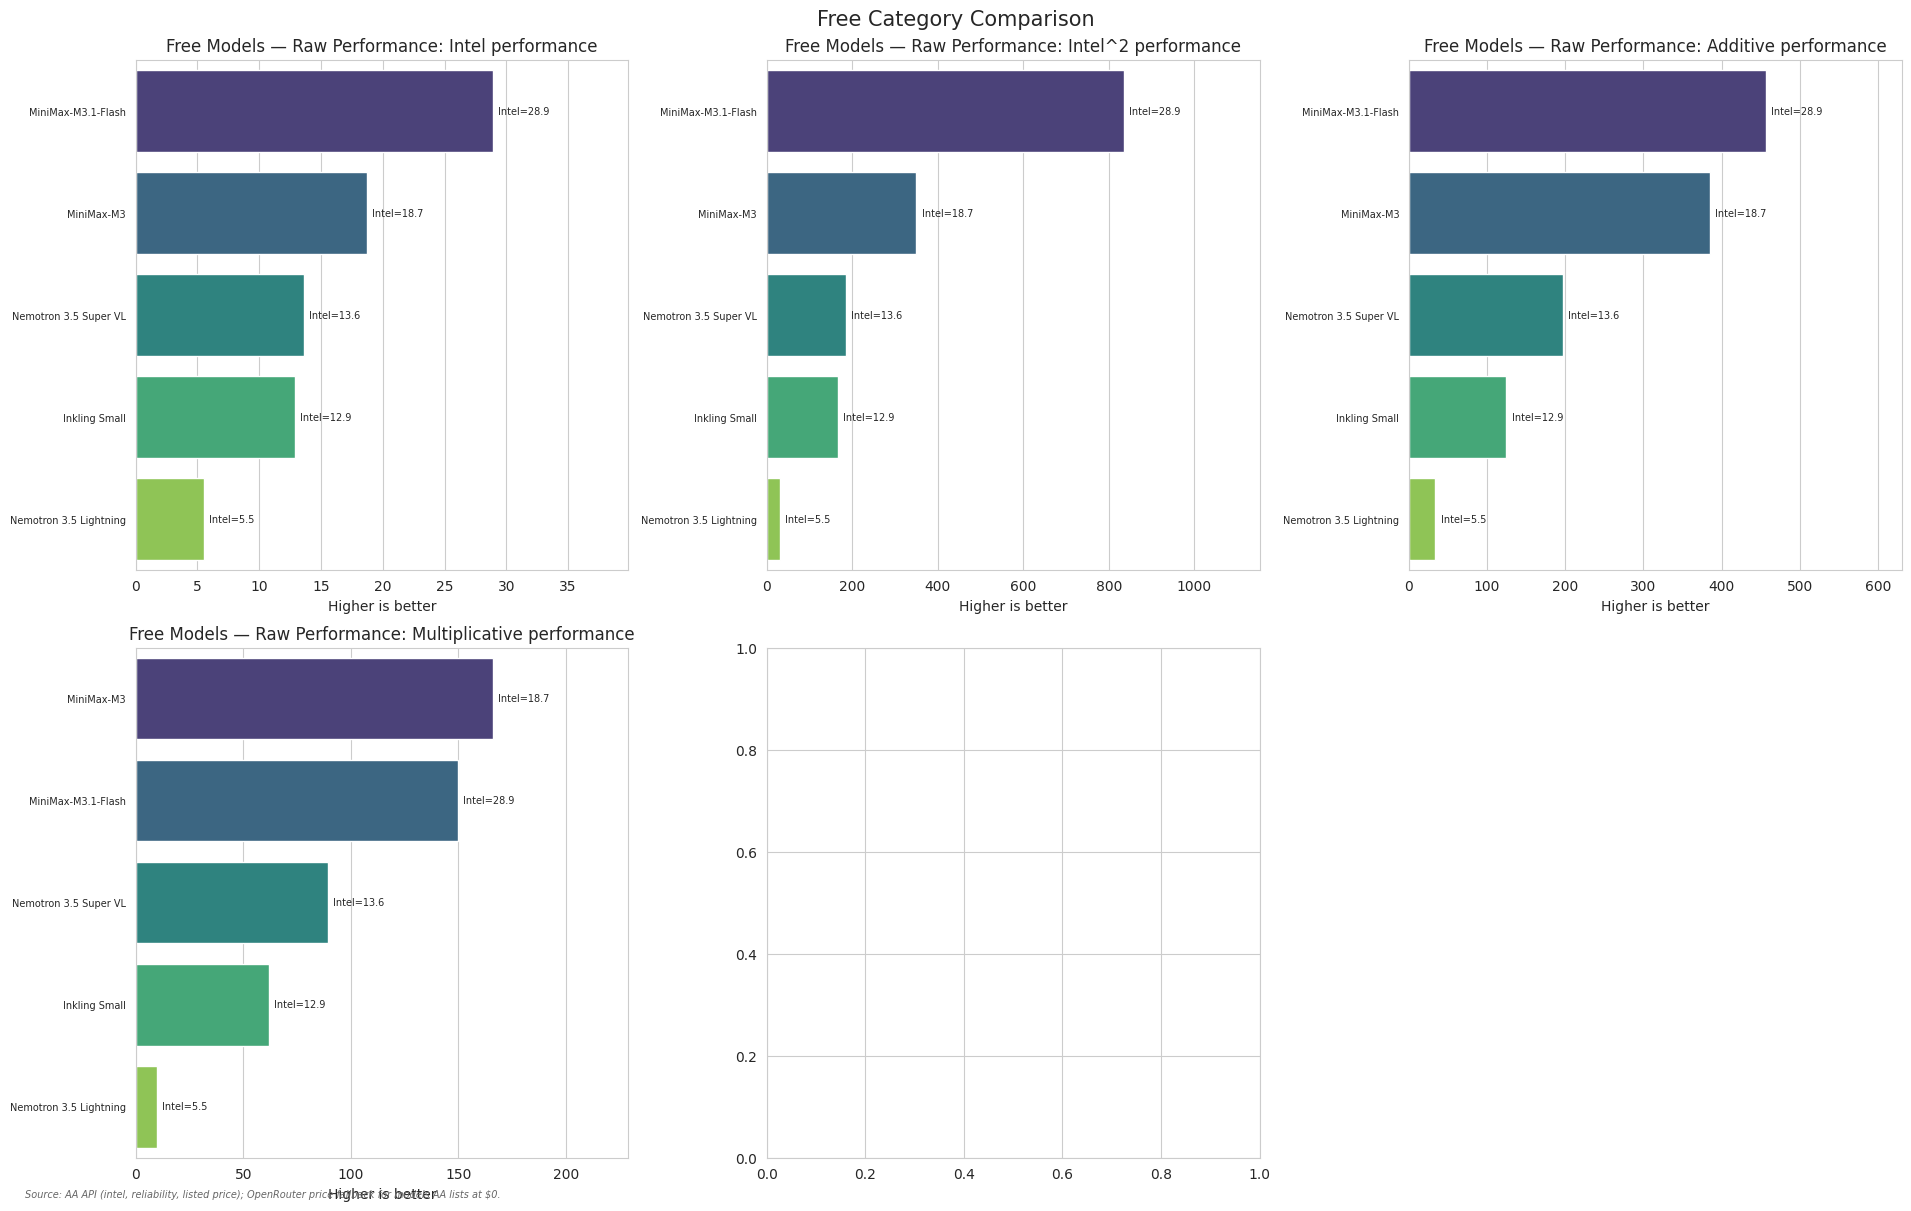

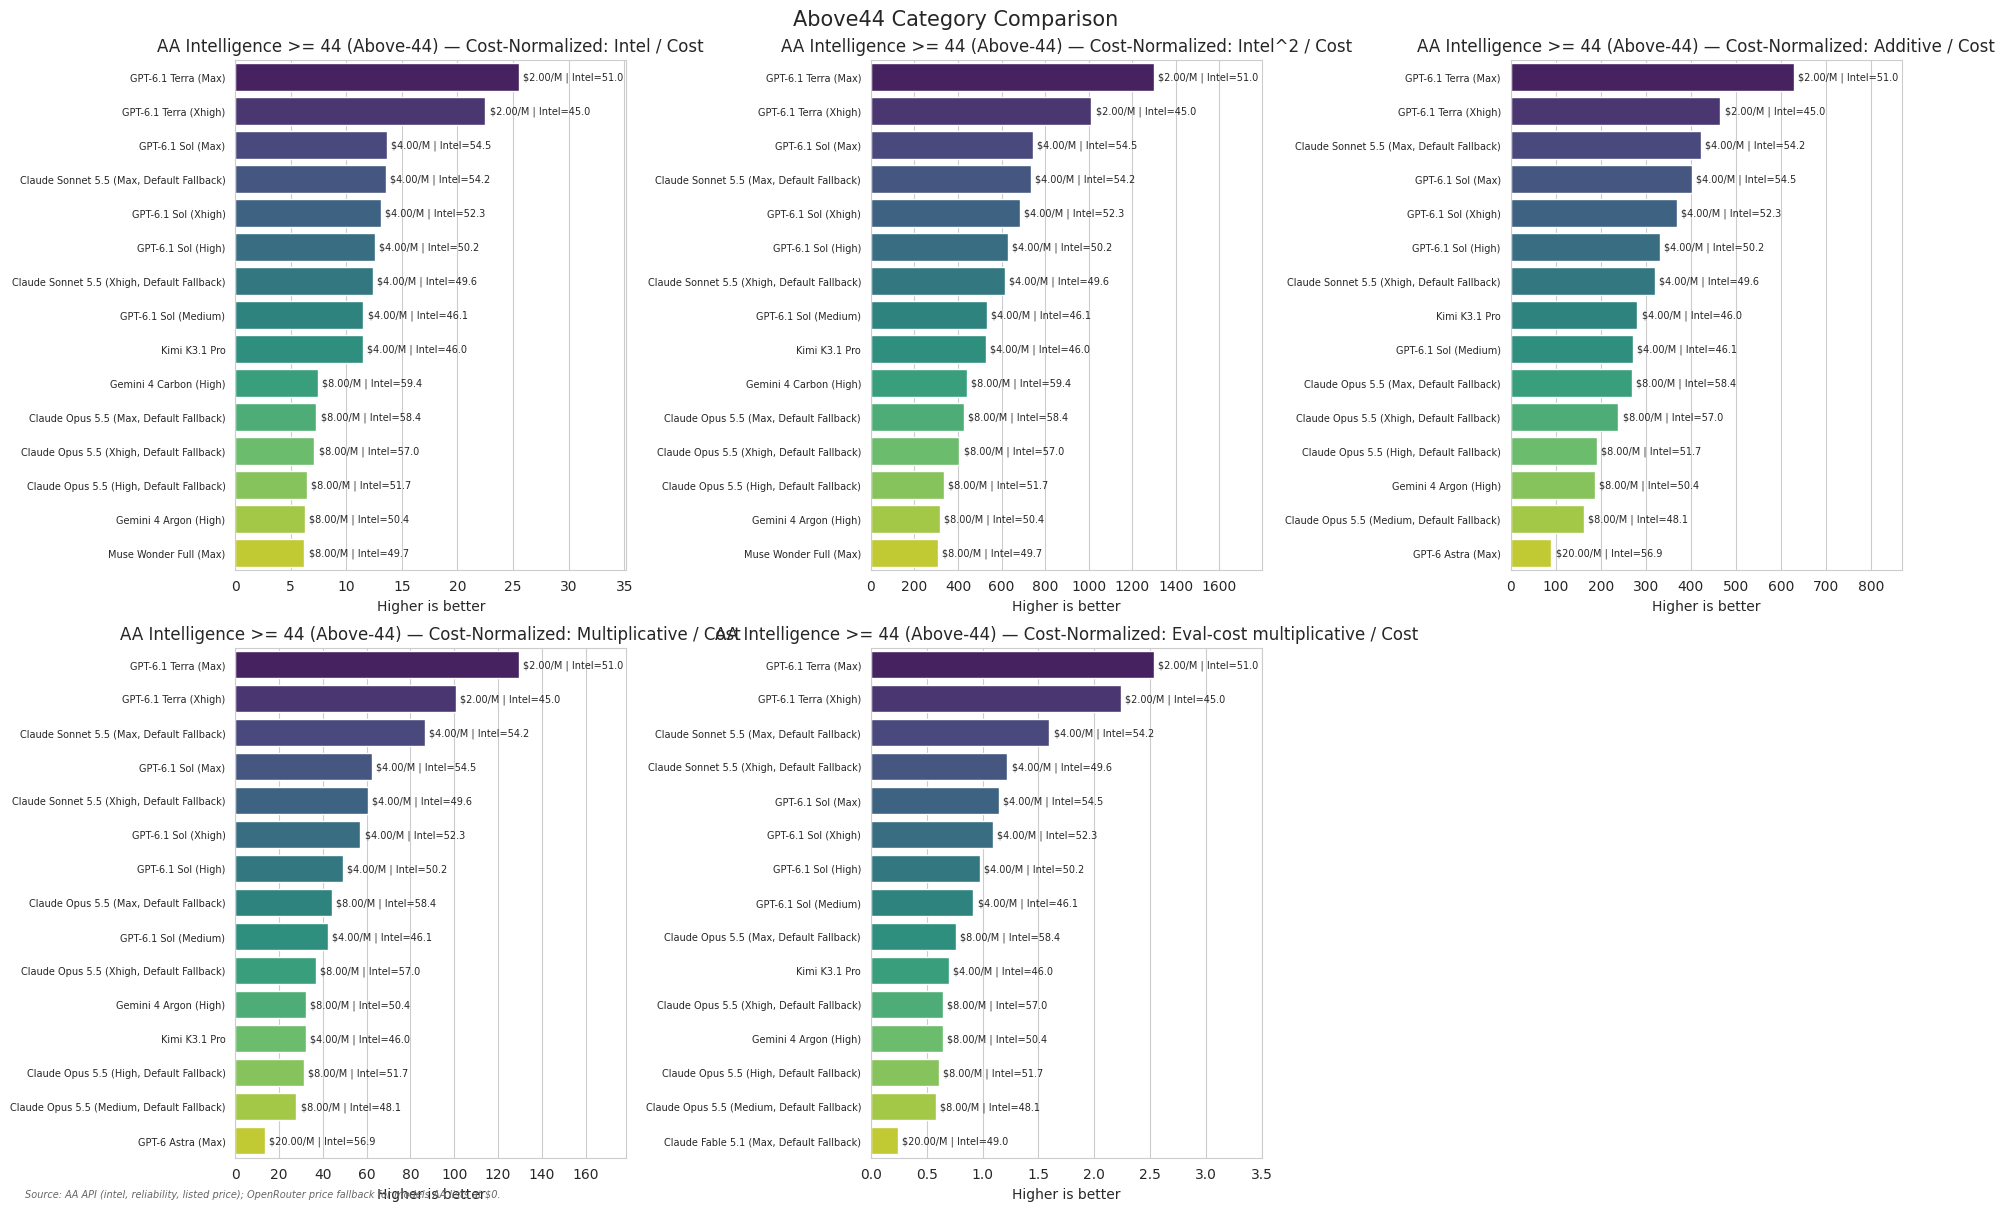

In [16]:
# ============================================================================
# 3.7-3.8 CATEGORY COMPARISONS
# 3.7: Free-model raw performance (no cost factor)
# 3.8: AA Intelligence Index >= 44 ("Above-44" — 44.0+ rounds up to 45), cost-normalized
# ============================================================================

import re as _cat_re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

_CATEGORY_COST = 'Price_Blended_USD_per_1M'
_CATEGORY_INTEL = 'AA_Intelligence_Index'
_CATEGORY_TPUT = 'median_output_tokens_per_second'

_category_source = df.copy()
if 'Model' not in _category_source.columns and 'name' in _category_source.columns:
    _category_source = _category_source.rename(columns={'name': 'Model'})

for _col in [_CATEGORY_COST, _CATEGORY_INTEL, _CATEGORY_TPUT, 'AA_Hallucination_Rate']:
    if _col not in _category_source.columns:
        _category_source[_col] = np.nan
    _category_source[_col] = pd.to_numeric(_category_source[_col], errors='coerce')

if 'is_free_model' in globals():
    _category_source['Is_Free'] = _category_source['Model'].apply(is_free_model)
else:
    _free_ids = set(globals().get('free_model_ids', globals().get('fallback_free_ids', set())))
    _free_parts = {str(_x).replace(':free', '').lower().rsplit('/', 1)[-1] for _x in _free_ids}
    _category_source['Is_Free'] = _category_source['Model'].astype(str).str.lower().apply(
        lambda _name: any(_part and _part in _name for _part in _free_parts)
    )

def _category_family_key(_name):
    if not isinstance(_name, str):
        return ''
    _base = _cat_re.sub(r'\s*\([^)]*\)\s*$', '', _name).strip().lower()
    _base = _cat_re.sub(r'\s*\d{4}\s*$', '', _base)
    _base = _cat_re.sub(r'\b(preview|beta|adaptive)\b', '', _base).strip()
    _tokens = [t for t in _base.split() if not _cat_re.match(r'^\d+\.\d+$', t)]
    return ' '.join(_tokens[:3])

_category_source['_Category_Family'] = _category_source['Model'].map(_category_family_key)
_category_source['_Throughput'] = _category_source[_CATEGORY_TPUT].where(
    _category_source[_CATEGORY_TPUT] > 0, np.nan
)
_category_tput_medians = _category_source.groupby('_Category_Family')['_Throughput'].median()
_category_source['_Throughput'] = _category_source['_Throughput'].fillna(
    _category_source['_Category_Family'].map(_category_tput_medians)
)
_category_source['_Reliability'] = (1 - _category_source['AA_Hallucination_Rate']).clip(lower=0.0)
_category_rel_medians = _category_source.groupby('_Category_Family')['_Reliability'].median()
_category_source['_Reliability'] = _category_source['_Reliability'].fillna(
    _category_source['_Category_Family'].map(_category_rel_medians)
)

_eval_cost_by_model = {}
if 'df_comp' in globals() and {'Model', 'Eval_Cost_USD'}.issubset(df_comp.columns):
    _eval_cost_by_model = (
        df_comp.dropna(subset=['Eval_Cost_USD'])
        .drop_duplicates('Model')
        .set_index('Model')['Eval_Cost_USD']
        .to_dict()
    )
_category_source['_Eval_Cost'] = _category_source['Model'].map(_eval_cost_by_model)
_category_source['_Eval_Cost'] = _category_source['_Eval_Cost'].where(
    _category_source['_Eval_Cost'] > 0,
    _category_source[_CATEGORY_INTEL] * _category_source[_CATEGORY_COST],
)

# Free models: raw performance only. No division by token price or eval cost.
df_free_performance = _category_source[_category_source['Is_Free']].copy()
df_free_performance['Intel_Performance'] = df_free_performance[_CATEGORY_INTEL]
df_free_performance['Intel2_Performance'] = df_free_performance[_CATEGORY_INTEL] ** 2
df_free_performance['Additive_Performance'] = (
    df_free_performance['_Throughput'] + df_free_performance[_CATEGORY_INTEL] ** 2
) * df_free_performance['_Reliability']
df_free_performance['Multiplicative_Performance'] = (
    np.sqrt(df_free_performance['_Throughput'])
    * df_free_performance[_CATEGORY_INTEL]
    * df_free_performance['_Reliability']
)
df_free_performance = df_free_performance.replace([np.inf, -np.inf], np.nan)

print("\n" + "=" * 120)
print("3.7 FREE MODELS — RAW PERFORMANCE (NO COST FACTOR)")
print("=" * 120)
print(f"Rows matched: {len(df_free_performance)}")
_free_columns = [
    'Model', _CATEGORY_INTEL, '_Throughput', '_Reliability',
    'Intel_Performance', 'Intel2_Performance',
    'Additive_Performance', 'Multiplicative_Performance',
]
print(df_free_performance[_free_columns].to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))

# High-intelligence category: AA Intelligence Index >= 44 ("Above-44").
# 44.0 and up rounds to 45, so the elite tier includes everything that
# displays as 45+ on AA/OpenRouter.
df_above44_comparison = _category_source[
    (_category_source[_CATEGORY_INTEL] >= 44) & (_category_source[_CATEGORY_COST] > 0)
].copy()
df_above44_comparison['Intel_per_Cost'] = (
    df_above44_comparison[_CATEGORY_INTEL] / df_above44_comparison[_CATEGORY_COST]
)
df_above44_comparison['Intel2_per_Cost'] = (
    df_above44_comparison[_CATEGORY_INTEL] ** 2 / df_above44_comparison[_CATEGORY_COST]
)
df_above44_comparison['Additive_Efficiency'] = (
    (df_above44_comparison['_Throughput'] + df_above44_comparison[_CATEGORY_INTEL] ** 2)
    * df_above44_comparison['_Reliability']
) / df_above44_comparison[_CATEGORY_COST]
df_above44_comparison['Multiplicative_Efficiency'] = (
    np.sqrt(df_above44_comparison['_Throughput'])
    * df_above44_comparison[_CATEGORY_INTEL]
    * df_above44_comparison['_Reliability']
) / df_above44_comparison[_CATEGORY_COST]
df_above44_comparison['EvalCost_Multiplicative_Efficiency'] = (
    np.sqrt(df_above44_comparison['_Throughput'])
    * df_above44_comparison[_CATEGORY_INTEL]
    * df_above44_comparison['_Reliability']
) / df_above44_comparison['_Eval_Cost']
df_above44_comparison = df_above44_comparison.replace([np.inf, -np.inf], np.nan)

print("\n" + "=" * 120)
print("3.8 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — COST-NORMALIZED COMPARISON")
print("=" * 120)
print(f"Rows matched with positive blended cost: {len(df_above44_comparison)}")
_above44_columns = [
    'Model', _CATEGORY_INTEL, '_Throughput', '_Reliability', _CATEGORY_COST,
    'Intel_per_Cost', 'Intel2_per_Cost', 'Additive_Efficiency',
    'Multiplicative_Efficiency', 'EvalCost_Multiplicative_Efficiency',
]
print(df_above44_comparison[_above44_columns].to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))

_free_metrics = [
    ('Intel_Performance', 'Intel performance'),
    ('Intel2_Performance', 'Intel^2 performance'),
    ('Additive_Performance', 'Additive performance'),
    ('Multiplicative_Performance', 'Multiplicative performance'),
]
_above44_metrics = [
    ('Intel_per_Cost', 'Intel / Cost'),
    ('Intel2_per_Cost', 'Intel^2 / Cost'),
    ('Additive_Efficiency', 'Additive / Cost'),
    ('Multiplicative_Efficiency', 'Multiplicative / Cost'),
    ('EvalCost_Multiplicative_Efficiency', 'Eval-cost multiplicative / Cost'),
]

for _frame, _title, _prefix, _metric_list in [
    (df_free_performance, 'Free Models — Raw Performance', 'Free', _free_metrics),
    (df_above44_comparison, 'AA Intelligence >= 44 (Above-44) — Cost-Normalized', 'Above44', _above44_metrics),
]:
    if _frame.empty:
        print(f"No rows available for {_title}.")
        continue
    _fig, _axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
    _axes = _axes.ravel()
    for _i, (_metric, _metric_title) in enumerate(_metric_list):
        _plot = _frame.dropna(subset=[_metric]).nlargest(15, _metric)
        _ax = _axes[_i]
        if _plot.empty:
            _ax.set_title(f'{_metric_title} (no data)')
            continue
        _bars = sns.barplot(data=_plot, x=_metric, y='Model', palette='viridis', ax=_ax)
        _ax.set_title(f'{_title}: {_metric_title}')
        _ax.set_xlabel('Higher is better')
        _ax.set_ylabel('')
        _ax.tick_params(axis='y', labelsize=7)
        _max_value = float(_plot[_metric].max())
        _ax.set_xlim(0, _max_value * 1.38 if _max_value > 0 else 1)
        for _bar, (_, _row) in zip(_bars.patches, _plot.iterrows()):
            if _prefix == 'Above44':
                _annotation = f"${_row[_CATEGORY_COST]:.2f}/M | Intel={_row[_CATEGORY_INTEL]:.1f}"
            else:
                _annotation = f"Intel={_row[_CATEGORY_INTEL]:.1f}"
            _ax.text(
                _bar.get_width() + _max_value * 0.015,
                _bar.get_y() + _bar.get_height() / 2,
                _annotation,
                va='center',
                fontsize=7,
            )
    _axes[-1].axis('off')
    _fig.suptitle(f'{_prefix} Category Comparison', fontsize=15)
    note_source(SRC_AA_OR)   # free routes: OpenRouter :free catalog + fallback list
    plt.show()


## 3.9 Formula Reference: AA Intelligence Index >= 44 (Above-44)

The Above-44 comparison (Intel >= 44, so 44.0+ rounds up to the displayed 45+ tier) uses the following cost-normalized formulas. In each expression, `T` is throughput, `I` is the AA Intelligence Index, `R` is the reliability factor `(1 - hallucination proxy)`, `C` is blended token cost, and `E` is evaluation-suite cost.

- **Intel / Cost**: `I / C` — intelligence value per dollar.
- **Intel² / Cost**: `I² / C` — emphasizes the highest-intelligence models while still penalizing price.
- **Additive**: `(T + I²) × R / C` — combines speed and squared intelligence before dividing by blended cost.
- **Multiplicative**: `√T × I × R / C` — requires speed, intelligence, and reliability to contribute together.
- **Evaluation-cost multiplicative**: `√T × I × R / E` — replaces nominal token cost with the estimated cost of running the full evaluation suite.

The plots annotate each model with its blended cost and AA Intelligence Index so price and intelligence can be read alongside the plotted score.

## 3.10 Above-44: Weighted-Average-Price Comparison


Catalog: 1056 slug -> permaslug entries

Models with AA Intelligence >= 44 (Above-44): 23
Weighted prices fetched: 21/23
No weighted price (2):
  Gemini 4 Carbon (High)
  Muse Wonder Full (Max)
Real-world throughput fetched: 21/21

3.10 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — WEIGHTED-AVERAGE-PRICE (EFFECTIVE) COMPARISON
Rows with positive weighted blended price: 21
                                      Model  AA_Intelligence_Index  _Throughput  RealWorld_Throughput  _Reliability  Weighted_Input_Price  Weighted_Output_Price  Weighted_Blended_Price  Intel_per_WeightedCost  Intel2_per_WeightedCost  Additive_WeightedEfficiency  Multiplicative_WeightedEfficiency  RawTput_Multiplicative_WeightedEfficiency
                        GPT-6.1 Terra (Max)                 51.000      120.640                64.852         0.462                 0.199                  4.770                   1.341                  38.018                1,938.906                      937.323                           

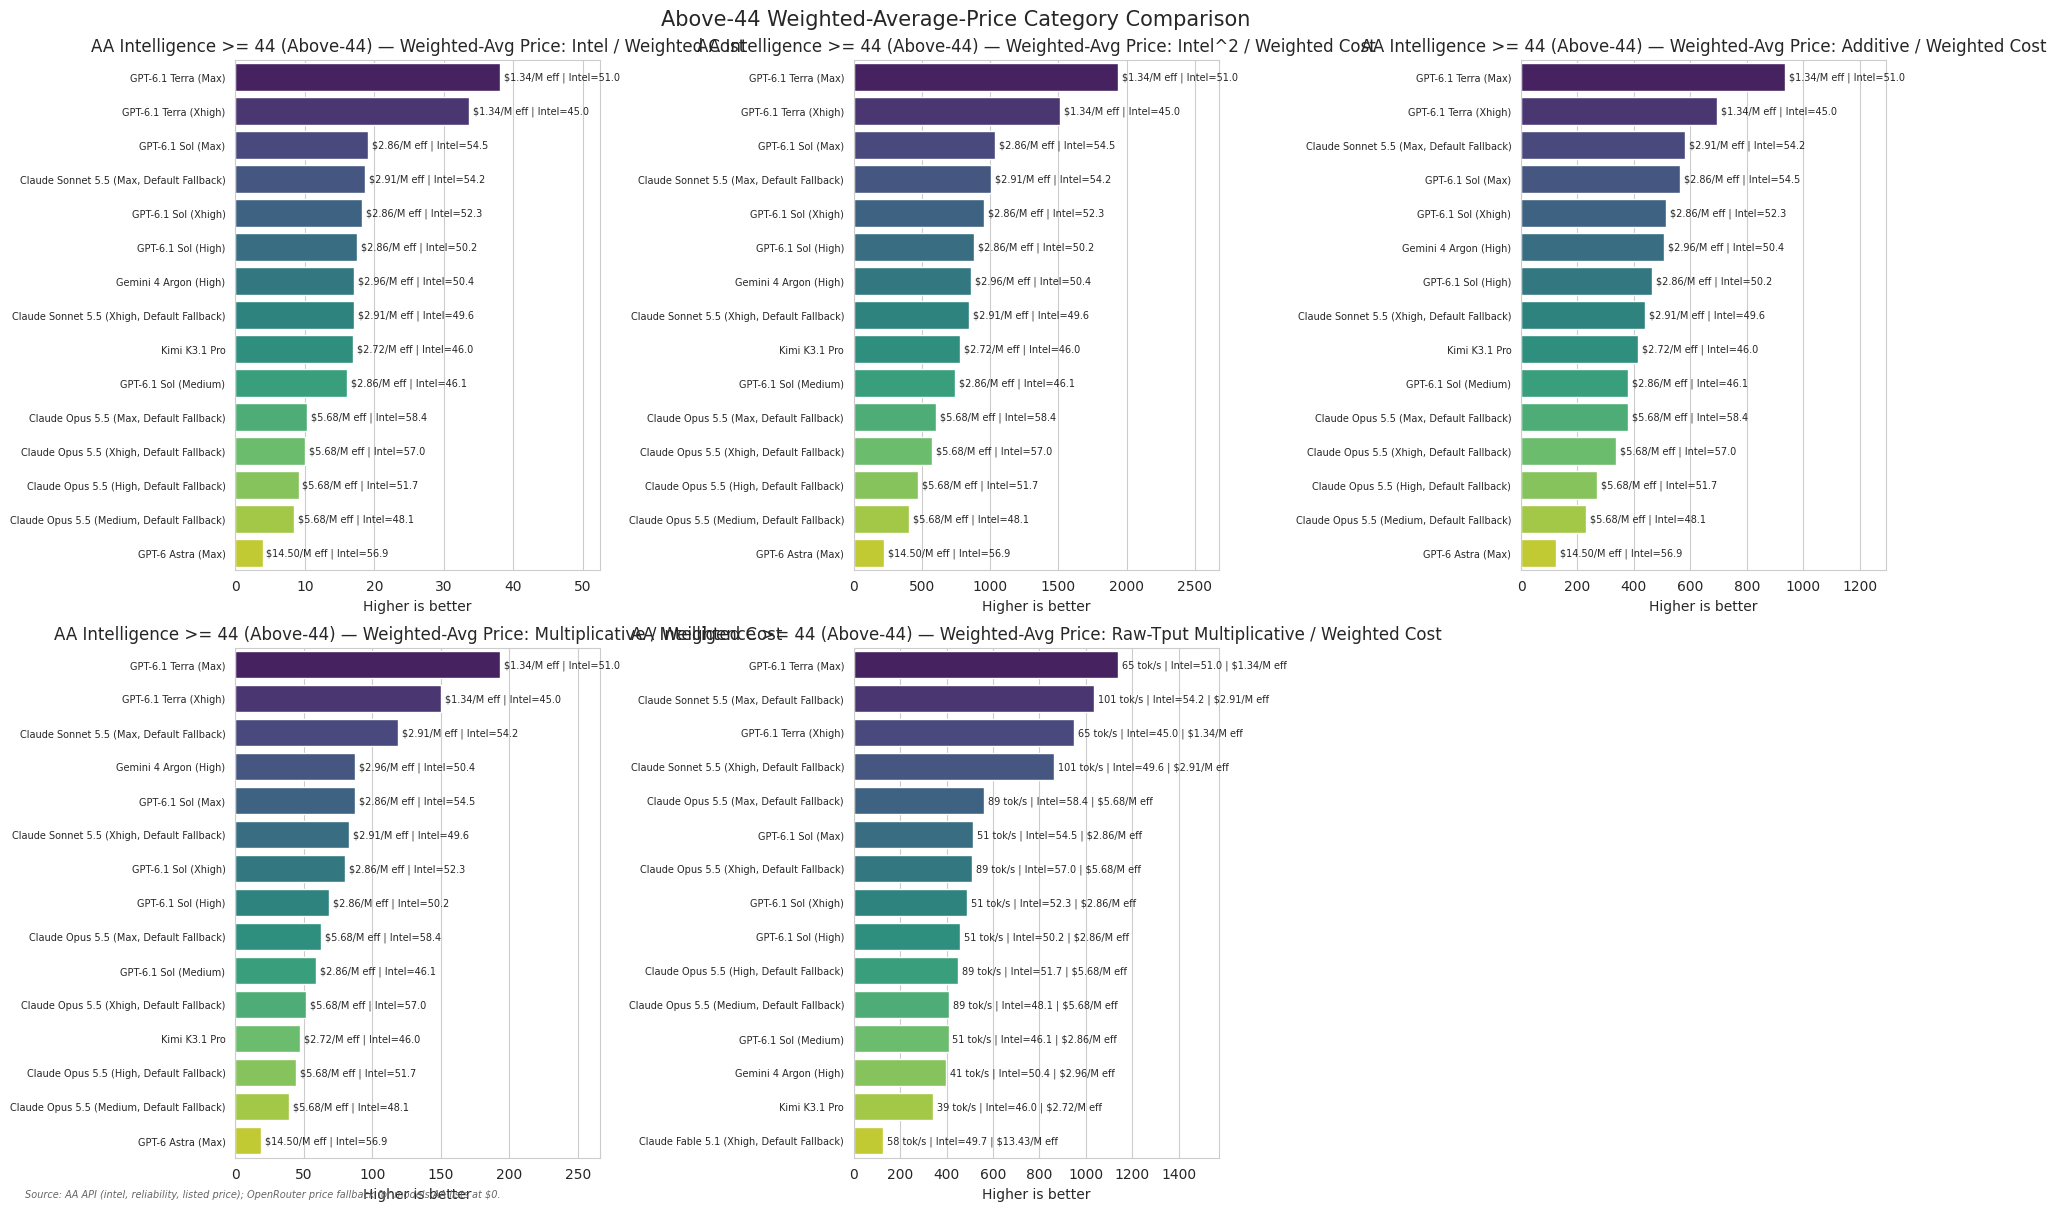


EFFICACY: RAW-THROUGHPUT MULTIPLIER vs SQRT-THROUGHPUT MULTIPLIER
                                      Model  AA_Intelligence_Index  _Tput_Raw  Weighted_Blended_Price  Multiplicative_WeightedEfficiency  RawTput_Multiplicative_WeightedEfficiency  Rank_Sqrt  Rank_Raw  Rank_Shift
                        GPT-6.1 Terra (Max)                  51.00      64.85                    1.34                             192.92                                   1,139.07       1.00      1.00        0.00
  Claude Sonnet 5.5 (Max, Default Fallback)                  54.20     101.23                    2.91                             118.89                                   1,035.90       3.00      2.00        1.00
                      GPT-6.1 Terra (Xhigh)                  45.00      64.85                    1.34                             149.97                                     950.68       2.00      3.00       -1.00
Claude Sonnet 5.5 (Xhigh, Default Fallback)                  49.60     101.23    

In [17]:
# ============================================================================
# 3.10 AA INTELLIGENCE >= 44 (ABOVE-44) — WEIGHTED-AVERAGE-PRICE COMPARISON
# ============================================================================
# Same analysis as 3.8, but the cost denominator is OpenRouter's
# "Weighted Average Input" price: the average price actually paid per million
# input tokens (cached or uncached) over the past day, weighted by provider
# traffic. This reflects real-world spend (caching + discounts) rather than
# the listed blended price.
#
# Threshold: AA Intelligence Index >= 44 ("Above-44") — 44.0+ rounds up to 45,
# matching what AA/OpenRouter display as the elite 45+ tier.
#
# Endpoint (frontend stats API, works with the standard OpenRouter key):
#   GET /api/frontend/v1/stats/effective-pricing?permaslug=<canonical-slug>&shape=v7&variant=standard
#   -> data.weightedInputPrice, data.weightedOutputPrice
# The permaslug is the date-suffixed canonical slug from
#   GET /api/frontend/v1/catalog/models  (field: permaslug)
# ============================================================================

import re as _wa_re
import numpy as np
import pandas as pd
import requests as _wa_rq
import matplotlib.pyplot as plt
import seaborn as sns

_WA_INTEL = 'AA_Intelligence_Index'
_WA_TPUT = 'median_output_tokens_per_second'

_wa_key = os.getenv('OPENROUTER_API_KEY_1')
_wa_headers = {
    'Authorization': f'Bearer {_wa_key}',
    'User-Agent': 'Mozilla/5.0',
} if _wa_key else {'User-Agent': 'Mozilla/5.0'}

# ── Step 1: slug -> permaslug map from the frontend catalog ──
_wa_slug_to_permaslug = {}
try:
    _wa_cat = _wa_rq.get(
        'https://openrouter.ai/api/frontend/v1/catalog/models',
        headers=_wa_headers, timeout=60,
    )
    if _wa_cat.status_code == 200:
        for _m in _wa_cat.json().get('data', []):
            _s, _p = _m.get('slug'), _m.get('permaslug')
            if _s and _p:
                _wa_slug_to_permaslug[_s] = _p
    print(f"Catalog: {len(_wa_slug_to_permaslug)} slug -> permaslug entries")
except Exception as _e:
    print(f"Catalog fetch failed: {_e}")

# ── Step 2: token-based matcher AA name -> OpenRouter slug (strict) ──
_wa_token = _wa_re.compile(r'[a-z]+|\d+(?:\.\d+)*')
_wa_stop = {'the', 'a', 'of', 'in', 'on', 'z', 'ai'}

def _wa_tokens(s):
    s = _wa_re.sub(r'\([^)]*\)', ' ', (s or '').lower())
    return set(_wa_token.findall(s)) - _wa_stop

def _wa_jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

_wa_or_slugs = [s for s in _wa_slug_to_permaslug
                if not any(x in s for x in (':free', ':batch', ':nitro'))
                and not s.startswith('~')]

def _wa_match_slug(aa_name, min_j=0.8):
    q = _wa_tokens(aa_name)
    best, best_j = None, 0.0
    for s in _wa_or_slugs:
        tail = _wa_tokens(s.split('/')[-1])
        j = _wa_jaccard(q, tail)
        if j > best_j:
            best, best_j = s, j
    return (best, best_j) if best_j >= min_j else (None, best_j)

# ── Step 3: fetch weighted prices for the Above-44 models ──
_wa_source = df.copy()
if 'Model' not in _wa_source.columns and 'name' in _wa_source.columns:
    _wa_source = _wa_source.rename(columns={'name': 'Model'})
for _c in [_wa_re.sub(r'[^A-Za-z0-9_]+', '', _WA_INTEL), _WA_TPUT, 'AA_Hallucination_Rate']:
    pass  # columns already coerced upstream

_wa_frame = _wa_source[
    (pd.to_numeric(_wa_source[_WA_INTEL], errors='coerce') >= 44)
].copy()
print(f"\nModels with AA Intelligence >= 44 (Above-44): {len(_wa_frame)}")

_wa_prices = {}
_wa_unmatched = []
for _i, _row in _wa_frame.iterrows():
    _name = str(_row['Model'])
    _slug, _j = _wa_match_slug(_name)
    if _slug is None:
        _wa_unmatched.append(_name)
        continue
    _permaslug = _wa_slug_to_permaslug.get(_slug)
    if not _permaslug:
        _wa_unmatched.append(f"{_name} (no permaslug)")
        continue
    try:
        _r = _wa_rq.get(
            'https://openrouter.ai/api/frontend/v1/stats/effective-pricing',
            params={'permaslug': _permaslug, 'shape': 'v7', 'variant': 'standard'},
            headers=_wa_headers, timeout=20,
        )
        if _r.status_code == 200:
            _d = _r.json().get('data', {})
            _wi = _d.get('weightedInputPrice')
            _wo = _d.get('weightedOutputPrice')
            if _wi is not None and float(_wi) > 0:
                _wa_prices[_name] = {
                    'slug': _slug,
                    'weighted_input': float(_wi),
                    'weighted_output': float(_wo or 0),
                    'jaccard': _j,
                }
            else:
                _wa_unmatched.append(f"{_name} (no traffic data)")
        else:
            _wa_unmatched.append(f"{_name} (HTTP {_r.status_code})")
    except Exception as _e:
        _wa_unmatched.append(f"{_name} ({_e})")

print(f"Weighted prices fetched: {len(_wa_prices)}/{len(_wa_frame)}")
if _wa_unmatched:
    print(f"No weighted price ({len(_wa_unmatched)}):")
    for _u in _wa_unmatched:
        print(f"  {_u}")

# ── Step 4b: fetch REAL-WORLD throughput from OpenRouter ──
# The throughput-comparison stats endpoint returns measured tok/s per provider
# per day from actual traffic. We take the traffic-weighted mean across days
# and providers as the real-world throughput.
_wa_tputs = {}
for _name, _info in _wa_prices.items():
    _permaslug = _wa_slug_to_permaslug.get(_info['slug'])
    if not _permaslug:
        continue
    try:
        _r = _wa_rq.get(
            'https://openrouter.ai/api/frontend/v1/stats/throughput-comparison',
            params={
                'perfWorkload': 'text_generation',
                'permaslug': _permaslug,
                'timeRange': '1w',
                'variant': 'standard',
            },
            headers=_wa_headers, timeout=20,
        )
        if _r.status_code == 200:
            _days = _r.json().get('data', [])
            # each day: {'x': date, 'y': {endpoint_id: tok/s}}
            # traffic weight = totalTokens per provider from effective-pricing
            _vals = []
            for _day in _days:
                _y = _day.get('y', {})
                if _y:
                    _vals.extend(float(v) for v in _y.values() if v is not None)
            if _vals:
                _wa_tputs[_name] = float(np.mean(_vals))
    except Exception:
        pass

print(f"Real-world throughput fetched: {len(_wa_tputs)}/{len(_wa_prices)}")

_wa_frame['RealWorld_Throughput'] = _wa_frame['Model'].map(
    lambda _n: _wa_tputs.get(_n, np.nan)
)

# ── Step 4: build the comparison frame ──
_wa_frame['Weighted_Input_Price'] = _wa_frame['Model'].map(
    lambda _n: _wa_prices.get(_n, {}).get('weighted_input', np.nan)
)
_wa_frame['Weighted_Output_Price'] = _wa_frame['Model'].map(
    lambda _n: _wa_prices.get(_n, {}).get('weighted_output', np.nan)
)
# Blended 3:1 on the weighted (effective) prices
_wa_frame['Weighted_Blended_Price'] = (
    _wa_frame['Weighted_Input_Price'] * 3 + _wa_frame['Weighted_Output_Price']
) / 4

# Throughput / reliability: reuse family-imputation logic from 3.7/3.8
def _wa_family_key(_name):
    if not isinstance(_name, str):
        return ''
    _base = _wa_re.sub(r'\s*\([^)]*\)\s*$', '', _name).strip().lower()
    _base = _wa_re.sub(r'\s*\d{4}\s*$', '', _base)
    _base = _wa_re.sub(r'\b(preview|beta|adaptive)\b', '', _base).strip()
    _toks = [t for t in _base.split() if not _wa_re.match(r'^\d+\.\d+$', t)]
    return ' '.join(_toks[:3])

_wa_frame['_Family'] = _wa_frame['Model'].map(_wa_family_key)
_wa_frame['_Throughput'] = pd.to_numeric(_wa_frame[_WA_TPUT], errors='coerce').where(
    lambda s: s > 0, np.nan
)
_wa_tput_medians = _wa_frame.groupby('_Family')['_Throughput'].median()
_wa_frame['_Throughput'] = _wa_frame['_Throughput'].fillna(
    _wa_frame['_Family'].map(_wa_tput_medians)
)
_wa_frame['_Reliability'] = (1 - pd.to_numeric(
    _wa_frame['AA_Hallucination_Rate'], errors='coerce')).clip(lower=0.0)
_wa_rel_medians = _wa_frame.groupby('_Family')['_Reliability'].median()
_wa_frame['_Reliability'] = _wa_frame['_Reliability'].fillna(
    _wa_frame['_Family'].map(_wa_rel_medians)
)

# Only rows with a positive weighted price can be cost-normalized
df_above44_weighted = _wa_frame[_wa_frame['Weighted_Blended_Price'] > 0].copy()

df_above44_weighted['Intel_per_WeightedCost'] = (
    df_above44_weighted[_WA_INTEL] / df_above44_weighted['Weighted_Blended_Price']
)
df_above44_weighted['Intel2_per_WeightedCost'] = (
    df_above44_weighted[_WA_INTEL] ** 2 / df_above44_weighted['Weighted_Blended_Price']
)
df_above44_weighted['Additive_WeightedEfficiency'] = (
    (df_above44_weighted['_Throughput'] + df_above44_weighted[_WA_INTEL] ** 2)
    * df_above44_weighted['_Reliability']
) / df_above44_weighted['Weighted_Blended_Price']
df_above44_weighted['Multiplicative_WeightedEfficiency'] = (
    np.sqrt(df_above44_weighted['_Throughput'])
    * df_above44_weighted[_WA_INTEL]
    * df_above44_weighted['_Reliability']
) / df_above44_weighted['Weighted_Blended_Price']

# Raw-throughput multiplier: throughput used LINEARLY (no sqrt), so speed
# counts at full strength. Uses the real-world measured throughput where
# available, falling back to the AA/family-imputed value.
df_above44_weighted['_Tput_Raw'] = df_above44_weighted['RealWorld_Throughput'].fillna(
    df_above44_weighted['_Throughput']
)
df_above44_weighted['RawTput_Multiplicative_WeightedEfficiency'] = (
    df_above44_weighted['_Tput_Raw']
    * df_above44_weighted[_WA_INTEL]
    * df_above44_weighted['_Reliability']
) / df_above44_weighted['Weighted_Blended_Price']
df_above44_weighted = df_above44_weighted.replace([np.inf, -np.inf], np.nan)

print("\n" + "=" * 130)
print("3.10 AA INTELLIGENCE INDEX >= 44 (ABOVE-44) — WEIGHTED-AVERAGE-PRICE (EFFECTIVE) COMPARISON")
print("=" * 130)
print(f"Rows with positive weighted blended price: {len(df_above44_weighted)}")
_wa_columns = [
    'Model', _WA_INTEL, '_Throughput', 'RealWorld_Throughput', '_Reliability',
    'Weighted_Input_Price', 'Weighted_Output_Price', 'Weighted_Blended_Price',
    'Intel_per_WeightedCost', 'Intel2_per_WeightedCost',
    'Additive_WeightedEfficiency', 'Multiplicative_WeightedEfficiency',
    'RawTput_Multiplicative_WeightedEfficiency',
]
print(df_above44_weighted[_wa_columns].sort_values(
    'Multiplicative_WeightedEfficiency', ascending=False
).to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))

# ── Step 5: plots (same layout as 3.8, plus raw-throughput multiplier) ──
_wa_metrics = [
    ('Intel_per_WeightedCost', 'Intel / Weighted Cost'),
    ('Intel2_per_WeightedCost', 'Intel^2 / Weighted Cost'),
    ('Additive_WeightedEfficiency', 'Additive / Weighted Cost'),
    ('Multiplicative_WeightedEfficiency', 'Multiplicative / Weighted Cost'),
    ('RawTput_Multiplicative_WeightedEfficiency', 'Raw-Tput Multiplicative / Weighted Cost'),
]

if not df_above44_weighted.empty:
    _fig, _axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
    _axes = _axes.ravel()
    for _i, (_metric, _metric_title) in enumerate(_wa_metrics):
        _plot = df_above44_weighted.dropna(subset=[_metric]).nlargest(15, _metric)
        _ax = _axes[_i]
        if _plot.empty:
            _ax.set_title(f'{_metric_title} (no data)')
            _ax.axis('off')
            continue
        _bars = sns.barplot(data=_plot, x=_metric, y='Model', palette='viridis', ax=_ax)
        _ax.set_title(f'AA Intelligence >= 44 (Above-44) — Weighted-Avg Price: {_metric_title}')
        _ax.set_xlabel('Higher is better')
        _ax.set_ylabel('')
        _ax.tick_params(axis='y', labelsize=7)
        _max_value = float(_plot[_metric].max())
        _ax.set_xlim(0, _max_value * 1.38 if _max_value > 0 else 1)
        for _bar, (_, _row) in zip(_bars.patches, _plot.iterrows()):
            if 'RawTput' in _metric:
                _tput_val = _row['_Tput_Raw']
                _tput_str = f"{_tput_val:.0f}" if pd.notna(_tput_val) else "n/a"
                _annotation = (
                    f"{_tput_str} tok/s | Intel={_row[_WA_INTEL]:.1f} | "
                    f"${_row['Weighted_Blended_Price']:.2f}/M eff"
                )
            else:
                _annotation = (
                    f"${_row['Weighted_Blended_Price']:.2f}/M eff | "
                    f"Intel={_row[_WA_INTEL]:.1f}"
                )
            _ax.text(
                _bar.get_width() + _max_value * 0.015,
                _bar.get_y() + _bar.get_height() / 2,
                _annotation,
                va='center',
                fontsize=7,
            )
    _axes[-1].axis('off')
    _fig.suptitle('Above-44 Weighted-Average-Price Category Comparison', fontsize=15)
    note_source(SRC_AA_OR)   # eval cost: AA website scrape (2026-06-12) + live feed
    plt.show()
else:
    print("No rows with weighted pricing data available for plotting.")

# ── Step 5b: efficacy discussion of the raw-throughput multiplier ──
print("\n" + "=" * 110)
print("EFFICACY: RAW-THROUGHPUT MULTIPLIER vs SQRT-THROUGHPUT MULTIPLIER")
print("=" * 110)
if not df_above44_weighted.empty:
    _eff = df_above44_weighted[[
        'Model', _WA_INTEL, '_Throughput', 'RealWorld_Throughput', '_Tput_Raw',
        '_Reliability', 'Weighted_Blended_Price',
        'Multiplicative_WeightedEfficiency', 'RawTput_Multiplicative_WeightedEfficiency',
    ]].dropna(subset=['Multiplicative_WeightedEfficiency',
                      'RawTput_Multiplicative_WeightedEfficiency']).copy()
    _eff['Rank_Sqrt'] = _eff['Multiplicative_WeightedEfficiency'].rank(ascending=False)
    _eff['Rank_Raw'] = _eff['RawTput_Multiplicative_WeightedEfficiency'].rank(ascending=False)
    _eff['Rank_Shift'] = _eff['Rank_Sqrt'] - _eff['Rank_Raw']
    _eff = _eff.sort_values('RawTput_Multiplicative_WeightedEfficiency', ascending=False)
    print(_eff[[
        'Model', _WA_INTEL, '_Tput_Raw', 'Weighted_Blended_Price',
        'Multiplicative_WeightedEfficiency', 'RawTput_Multiplicative_WeightedEfficiency',
        'Rank_Sqrt', 'Rank_Raw', 'Rank_Shift',
    ]].head(15).to_string(index=False, float_format=lambda _x: f"{_x:,.2f}"))
    print("""
WHY IT MATTERS:
- sqrt(T) compresses the speed range: 200 tok/s -> 14.1, 50 tok/s -> 7.1 (only 2x
  difference), even though the fast model is 4x faster in wall-clock time.
- Raw T keeps speed linear: a 4x faster model contributes exactly 4x more.
- For latency-sensitive work (chat, agents, interactive coding), wall-clock
  tokens/sec is what users feel — the raw multiplier ranks those models higher.
- For cost-per-intelligence workloads (batch, offline evals), sqrt(T) is fine
  because throughput beyond a threshold adds little value.
- Real-world throughput (OpenRouter measured, traffic-weighted across
  providers/days) replaces the AA benchmark figure where available, so the
  ranking reflects what customers actually experience on the router.
CAVEAT: real-world throughput varies by provider and time-of-day; the mean
across the past week smooths this but is still noisier than a lab benchmark.""")

# ── Step 6: listed vs weighted price comparison ──
if not df_above44_weighted.empty:
    _cmp = df_above44_weighted[[
        'Model', _WA_INTEL, 'Price_Blended_USD_per_1M', 'Weighted_Blended_Price'
    ]].copy()
    _cmp['Listed_Minus_Weighted'] = _cmp['Price_Blended_USD_per_1M'] - _cmp['Weighted_Blended_Price']
    _cmp['Discount_Pct'] = (
        1 - _cmp['Weighted_Blended_Price'] / _cmp['Price_Blended_USD_per_1M']
    ) * 100
    _cmp = _cmp.sort_values('Discount_Pct', ascending=False)
    print("\n" + "=" * 110)
    print("LISTED (AA blended) vs WEIGHTED-AVERAGE (OpenRouter effective) PRICE — Intel >= 44 (Above-44)")
    print("=" * 110)
    print(_cmp.to_string(index=False, float_format=lambda _x: f"{_x:,.3f}"))
    print("\nPositive Discount_Pct = customers actually pay LESS than the listed blended price")
    print("(caching + provider discounts). Negative = paying MORE than listed.")

3.15 FAST & CHEAP WORKHORSE MODELS — EMPIRICAL SPEED / COST
  SP = measured_tps^1.5 / blended_$_per_1M   (2x speed => 2.83x score)
Models shown: 46   (filter: price <= $1.50 OR measured >= 60 tok/s;
  force-included reference: kimi)
Benchmark runs attached (v3 writing/v2 parsing): 0/46
#  model                               I    R meas t/s   $/1M       SP   tok/$ emp t/semp $/task score  provider
----------------------------------------------------------------------------------------------------------------------------
1  gpt-oss-20b (High)                            9 0.65      448   0.09105,359.7   4,978     n/a       n/a   n/a  Amazon Bedrock
2  MiniMax-M3.1-Flash                           43 0.48      312   0.26 20,994.4   1,189     n/a       n/a   n/a  Parasail
3  Gemma 4 26B A4B (Reasoning)                  17 0.72      158   0.11 17,653.6   1,404     n/a       n/a   n/a  Makora
4  Claude Haiku 5.5 (Xhigh)                     41 0.43      185   0.20 12,581.4     925     n/a      

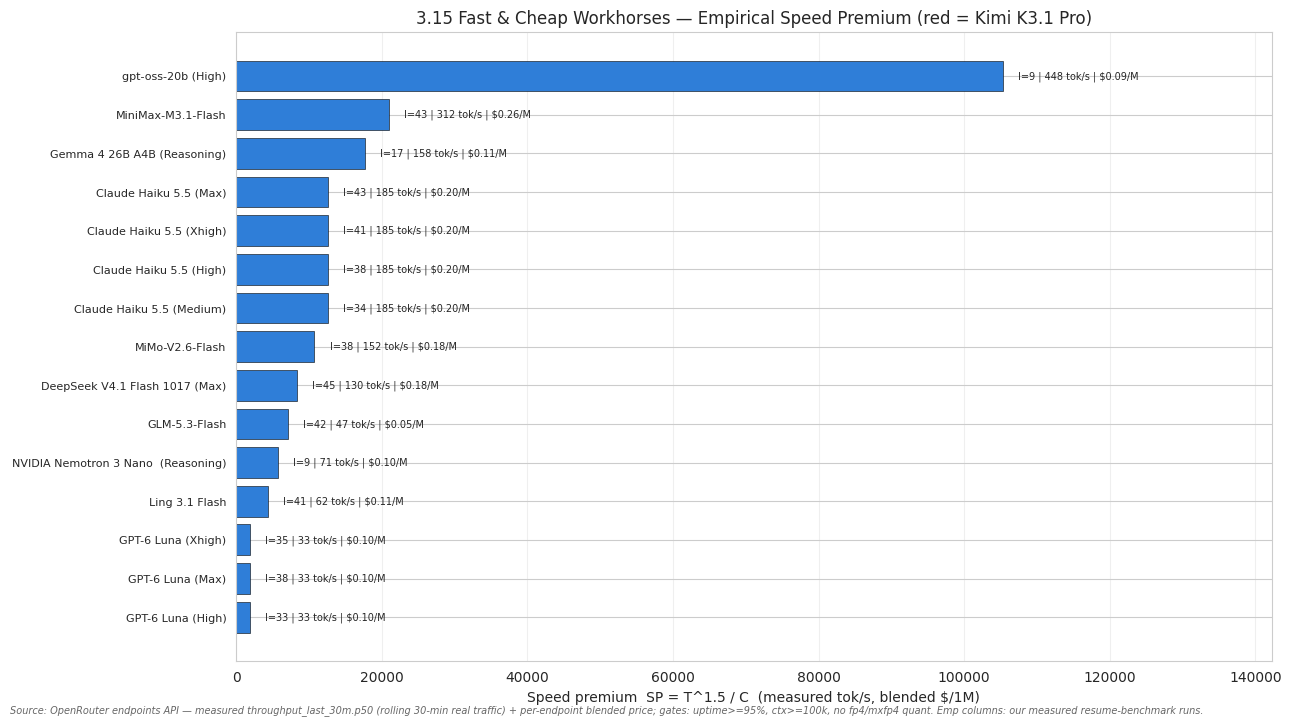

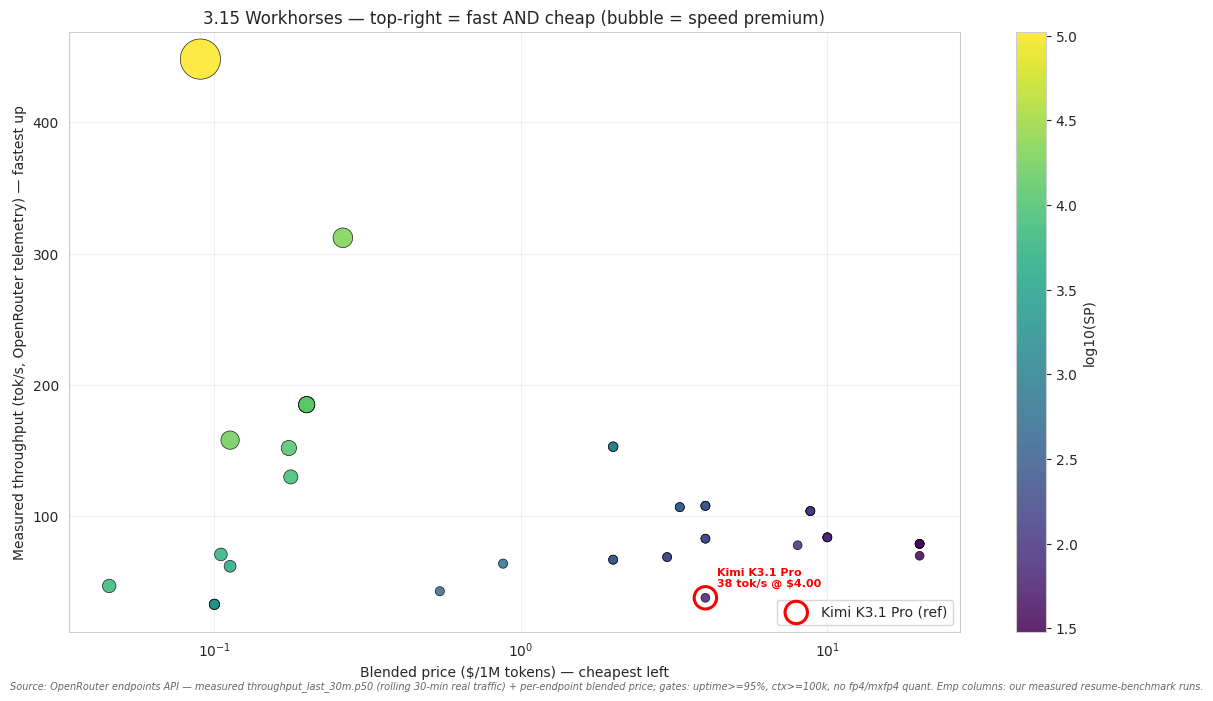


HOW TO READ
  - SP (speed premium) ranks fast-and-cheap: speed enters at ^1.5, so
    faster models get disproportionate credit while cost stays a divisor.
  - tok/$ is plain throughput-per-dollar (linear); SP is the premium view.
  - Emp columns are OUR measured runs (resume write/parse): tokens/s from
    recorded latency and $ per task — attached only on a confident name
    match (Jaccard >= 0.6 / containment), so unmatched models show n/a.
  - Kimi K3.1 Pro (red) is force-included as the high-IQ reference:
    IQ 55.1 but $4.00/M and only 38 measured tok/s on its single
    Moonshot AI endpoint — it falls far behind the cheap-fast
    workhorses on every speed/cost metric.


In [18]:
# ============================================================================
# 3.15 FAST & CHEAP WORKHORSE MODELS — EMPIRICAL SPEED / COST
# ============================================================================
# What makes a "workhorse": cheap enough to run at scale and fast enough to
# feel instant. Both inputs here are EMPIRICAL, not AA's lab sheet:
#   1) OpenRouter measured endpoint telemetry (throughput_last_30m.p50) and
#      real per-endpoint blended price — from provider_value_by_model.json
#      built by 3.11.
#   2) Our own benchmark runs (v3 writing + v2 parsing): measured wall-clock
#      latency, token counts and USD cost per task. Model names drift between
#      runs, so benchmark rows are attached with a token-Jaccard matcher and
#      only when the match is confident (J >= 0.6 or containment).
#
# SPEED PREMIUM (the point of this section):
#       SP = T^1.5 / C      (T = measured tok/s, C = blended $/1M)
#   Speed enters at power 1.5: a model that is 2x faster earns 2.83x the
#   credit, so fast-and-cheap always beats slow-and-slightly-cheaper. Cost is
#   still the divisor, so a $4/M model must be ~2.5x faster than a $0.25/M
#   one just to tie.
#
# Kimi K3.1 Pro is force-included as the high-IQ reference (red), even though
# it fails the cheap/fast gate — it shows why measured speed + real price
# matter for "workhorse" utility.
# ============================================================================

import json, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_WH_CACHE = 'results/provider_value_by_model.json'
_FORCE_INCLUDE = ('kimi',)          # always show, for contrast

# ── 1. Empirical provider telemetry (router-measured speed + real price) ──
_emp = {}
if os.path.exists(_WH_CACHE):
    with open(_WH_CACHE) as f:
        _cache = json.load(f)
    for _name, _rec in _cache.items():
        _a = _rec.get('aa') or {}
        _c = _rec.get('chosen') or {}
        _d = _rec.get('default') or {}
        _ep = _c or _d
        if not _ep or not _ep.get('tps') or not _ep.get('price_blend'):
            continue
        _emp[_name] = {
            'Intel': _a.get('intel'),
            'Reliab': _a.get('reliab'),
            'Meas_tps': float(_ep['tps']),
            'Price_M': float(_ep['price_blend']),
            'Provider': _ep.get('provider'),
            'Chosen_note': _rec.get('chosen_note', ''),
        }
else:
    print('WARNING: provider_value_by_model.json not found — run 3.11 first.')

# ── 2. Our measured benchmark runs (writing = per-resume; parsing rows are 5 resumes) ──
def _load_wh(path):
    return json.load(open(path)) if os.path.exists(path) else []

_wh_writing = _load_wh('results/v3_resume_writing_results.json')
_wh_parsing = _load_wh('results/v2_benchmark_results.json')

def _wh_norm(s):
    s = str(s).lower()
    s = re.sub(r'\([^)]*\)', '', s)          # drop (High)/(Max)/...
    s = re.sub(r'\s*\d{4}\s*$', '', s)       # drop date suffixes
    s = re.sub(r'[^a-z0-9]+', '', s)
    return s.strip()

_TOK_RE = re.compile(r'[a-z]+|\d+(?:\.\d+)*')
def _toks(s):
    return set(_TOK_RE.findall(str(s).lower()))

def _jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

def _cal(e):
    return float(e.get('latency', e.get('time', e.get('total_time'))))

def _ctok(e):
    return float(e.get('tokens', e.get('total_tokens')))

def _ccost(e):
    c = e.get('cost')
    return float(c) if c is not None else np.nan

_bench = {}

def _add_bench(e, bucket, scale):
    m = e.get('model')
    if not m:
        return
    k = _wh_norm(m)
    try:
        lat, tok = _cal(e), _ctok(e)
    except (TypeError, ValueError):
        return
    row = _bench.setdefault(k, {'model': m, 'writing': [], 'parsing': []})
    row[bucket].append((lat, tok, _ccost(e), scale))
    sc = e.get('score')
    if isinstance(sc, (int, float)) and sc > 0:
        row.setdefault('scores', []).append(float(sc))

for e in _wh_writing:
    _add_bench(e, 'writing', 1)
for e in _wh_parsing:
    _add_bench(e, 'parsing', 5)   # each parsing record covers 5 resumes

_bench_index = [(k, r, _toks(k)) for k, r in _bench.items()]

def _match_bench(name):
    """Attach benchmark runs to a provider-cache model name, only on a
    confident match (token Jaccard >= 0.6, or containment in either direction)."""
    q = _toks(name)
    if not q:
        return None
    best, best_j = None, 0.0
    for k, r, tk in _bench_index:
        if not tk:
            continue
        j = _jaccard(q, tk)
        if q.issubset(tk) or tk.issubset(q):
            j = max(j, 0.75)
        if j > best_j:
            best, best_j = r, j
    return best if best_j >= 0.6 else None

def _emp_stats(row):
    out = {'tps': np.nan, 'cost_task': np.nan, 'score': np.nan}
    sum_lat = sum_tok = 0.0
    cost_sum = cost_n = 0.0
    for bucket in ('writing', 'parsing'):
        for lat, tok, cost, scale in row[bucket]:
            sum_lat += lat
            sum_tok += tok
            if not np.isnan(cost):
                cost_sum += cost / scale      # per-task cost
                cost_n += 1
    if sum_lat > 0:
        out['tps'] = sum_tok / sum_lat
    if cost_n:
        out['cost_task'] = cost_sum / cost_n
    scores = row.get('scores')
    if scores:
        out['score'] = float(np.mean(scores))
    return out

# ── 3. Build the workhorse frame ───────────────────────────────────────────
_rows = []
_n_bench_attached = 0
for _name, _p in _emp.items():
    # workhorse lens: cheap OR fast (price <= $1.50 OR measured >= 60 tok/s)
    # ... but ALWAYS include the force-include reference models (Kimi K3.1 Pro)
    _is_ref = any(_t in str(_name).lower() for _t in _FORCE_INCLUDE)
    if (not _is_ref) and _p['Price_M'] > 1.50 and _p['Meas_tps'] < 60:
        continue
    sp = (_p['Meas_tps'] ** 1.5) / _p['Price_M']
    raw = _p['Meas_tps'] / _p['Price_M']
    _b = _match_bench(_name)
    st = _emp_stats(_b) if _b else {'tps': np.nan, 'cost_task': np.nan, 'score': np.nan}
    if _b is not None:
        _n_bench_attached += 1
    _rows.append({
        'Model': _name,
        'Intel': _p['Intel'],
        'Reliab': _p['Reliab'],
        'Meas_tps': _p['Meas_tps'],
        'Price_M': _p['Price_M'],
        'SP': sp,
        'tok_per_dollar': raw,
        'Emp_tps': st['tps'],
        'Emp_cost_task': st['cost_task'],
        'Emp_score': st['score'],
        'Provider': _p['Provider'],
        'Ref': _is_ref,
    })

_df_wh = pd.DataFrame(_rows).sort_values('SP', ascending=False)
if _df_wh.empty:
    print('No workhorse rows built — check that provider_value_by_model.json exists.')
else:
    print('=' * 124)
    print('3.15 FAST & CHEAP WORKHORSE MODELS — EMPIRICAL SPEED / COST')
    print('  SP = measured_tps^1.5 / blended_$_per_1M   (2x speed => 2.83x score)')
    print('=' * 124)
    print(f"Models shown: {len(_df_wh)}   (filter: price <= $1.50 OR measured >= 60 tok/s;")
    print(f"  force-included reference: {', '.join(_FORCE_INCLUDE)})")
    print(f"Benchmark runs attached (v3 writing/v2 parsing): {_n_bench_attached}/{len(_df_wh)}")
    print(f"{'#':<3}{'model':<32}{'I':>5}{'R':>5}{'meas t/s':>9}{'$/1M':>7}"
          f"{'SP':>9}{'tok/$':>8}{'emp t/s':>8}{'emp $/task':>10}{'score':>6}  provider")
    print('-' * 124)
    for _i, (_, r) in enumerate(_df_wh.iterrows(), 1):
        _f = lambda v, n=1: 'n/a' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{float(v):,.{n}f}'
        _tag = '  [ref]' if r['Ref'] else ''
        print(f"{_i:<3}{fam_label(r['Model'], 40):<42}"
              f"{_f(r['Intel'],0):>5}{_f(r['Reliab'],2):>5}{_f(r['Meas_tps'],0):>9}{_f(r['Price_M'],2):>7}"
              f"{_f(r['SP'],1):>9}{_f(r['tok_per_dollar'],0):>8}"
              f"{_f(r['Emp_tps'],0):>8}{_f(r['Emp_cost_task'],4):>10}{_f(r['Emp_score'],1):>6}"
              f"  {str(r['Provider'])[:14]}{_tag}")

    # ── Plot 1: speed-premium leaderboard ───────────────────────────────────
    _top = _df_wh.head(15).sort_values('SP')
    plt.figure(figsize=(13, max(6, 0.35 * len(_top) + 2)))
    _colors = ['#c0392b' if r['Ref'] else '#2f7ed8' for _, r in _top.iterrows()]
    plt.barh(np.arange(len(_top)), _top['SP'], color=_colors, edgecolor='black', linewidth=0.4)
    plt.yticks(np.arange(len(_top)), [fam_label(m, 34) for m in _top['Model']], fontsize=8)
    plt.xlabel('Speed premium  SP = T^1.5 / C  (measured tok/s, blended $/1M)')
    plt.title('3.15 Fast & Cheap Workhorses — Empirical Speed Premium (red = Kimi K3.1 Pro)')
    for i, (_, r) in enumerate(_top.iterrows()):
        _i_s = '?' if r['Intel'] is None or pd.isna(r['Intel']) else f"{r['Intel']:.0f}"
        plt.text(r['SP'] + 0.02 * _top['SP'].max(), i,
                 f"I={_i_s} | {r['Meas_tps']:.0f} tok/s | ${r['Price_M']:.2f}/M",
                 va='center', fontsize=7)
    plt.xlim(0, _top['SP'].max() * 1.35)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    note_source(SRC_OR_TEL + ' Emp columns: our measured resume-benchmark runs.')
    plt.show()

    # ── Plot 2: speed vs price scatter (bubble = premium) ───────────────────
    plt.figure(figsize=(12, 7))
    _ok = _df_wh.dropna(subset=['Meas_tps', 'Price_M'])
    _spmax = _ok['SP'].max() or 1.0
    _sc = plt.scatter(_ok['Price_M'], _ok['Meas_tps'],
                       s=_ok['SP'].clip(lower=0) / _spmax * 800 + 40,
                       c=np.log10(_ok['SP'].clip(lower=0.01) + 1), cmap='viridis',
                       alpha=0.85, edgecolors='black', linewidth=0.5)
    plt.colorbar(_sc, label='log10(SP)')
    _kimi = _ok[_ok['Ref']]
    if len(_kimi):
        plt.scatter(_kimi['Price_M'], _kimi['Meas_tps'], s=260, facecolors='none',
                    edgecolors='red', linewidths=2.2, label='Kimi K3.1 Pro (ref)')
        for _, r in _kimi.iterrows():
            plt.annotate(f"{fam_label(r['Model'], 24)}\n{r['Meas_tps']:.0f} tok/s @ ${r['Price_M']:.2f}",
                         (r['Price_M'], r['Meas_tps']), xytext=(8, 8),
                         textcoords='offset points', color='red', fontsize=8, fontweight='bold')
        plt.legend(loc='lower right')
    plt.xlabel('Blended price ($/1M tokens) — cheapest left')
    plt.ylabel('Measured throughput (tok/s, OpenRouter telemetry) — fastest up')
    plt.title('3.15 Workhorses — top-right = fast AND cheap (bubble = speed premium)')
    plt.xscale('log')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    note_source(SRC_OR_TEL + ' Emp columns: our measured resume-benchmark runs.')
    plt.show()

    print('\n' + '=' * 124)
    print('HOW TO READ')
    print('=' * 124)
    print('  - SP (speed premium) ranks fast-and-cheap: speed enters at ^1.5, so')
    print('    faster models get disproportionate credit while cost stays a divisor.')
    print('  - tok/$ is plain throughput-per-dollar (linear); SP is the premium view.')
    print('  - Emp columns are OUR measured runs (resume write/parse): tokens/s from')
    print('    recorded latency and $ per task — attached only on a confident name')
    print('    match (Jaccard >= 0.6 / containment), so unmatched models show n/a.')
    print('  - Kimi K3.1 Pro (red) is force-included as the high-IQ reference:')
    print('    IQ 55.1 but $4.00/M and only 38 measured tok/s on its single')
    print('    Moonshot AI endpoint — it falls far behind the cheap-fast')
    print('    workhorses on every speed/cost metric.')

# EFFORT-LEVEL NAMING CAVEAT (verified 2026-10-25):
#   OpenRouter exposes reasoning_effort as a REQUEST PARAMETER for GLM/Kimi/
#   Gemini-style models (e.g. z-ai/glm-5.3-flash: supported_efforts max/high/low,
#   default max) — NOT as separate slugs. AA, however, benchmarks specific
#   variant rows and suffixes them explicitly ((Max)/(Xhigh)/(High)/(Medium)/
#   (Low)/(Reasoning)/(Non-reasoning)) only for families it measures per-level.
#   Rows WITHOUT a suffix (GLM-5.3-Flash 41.8, Kimi K3.1 Pro 55.1, MiMo-V2.6-*,
#   MiniMax-M3.1-Flash, Ling 3.1 Flash, GLM-5.3-*) are single-default rows:
#   AA measured ONE configuration — most of these have mandatory reasoning per
#   OpenRouter, i.e. the scored point is its default (usually max/always-on)
#   effort. 'GLM-5.3-Flash' therefore = 'GLM-5.3-Flash @ default effort',
#   NOT 'all of GLM-5.3-Flash across efforts'. fam_label() shows exactly what
#   was scored; no suffix here means 'default effort', not 'family aggregate'.


## 3.16 Saturation-Utility Workhorse Ranking
(the §3.4b/c methodology, ported from GDPval)

This section transplants the two methodological ideas from `GDPval` §3.4b / §3.4c into the workhorse line-up.

**1. Two rankings (from 3.4b)**

| Ranking | Inputs | Use |
|---|---|---|
| **A — Measured only** | every input is a measurement; no imputation | decisions |
| **B — Expanded** | family-median fills allowed, flagged `T†` / `R†` | coverage |

**2. Saturating utilities (from 3.4c, adapted)**

The 3.4c metric was `(I/I_ref)² · U_T(T) · R / (C/C_ref)` — speed saturates but intelligence keeps growing without bound. For workhorses we make **both** saturate:

- **Speed saturates HIGH**: `U_T(T) = 1 − exp(−T/τ_T)`, τ_T = 33.3 → 100 tok/s ≈ 95% of the ceiling. Once a model is fast enough, extra speed stops paying.
- **Intelligence saturates LOW**: `U_I(I) = 1 − exp(−I/τ_I)`, τ_I = 15 → IQ 45 ≈ 95% of the ceiling. A workhorse only needs to be *smart enough*; IQ above ~45 gives almost no bonus (vs. 3.4c where `I²` never stops rewarding IQ).

Final score: `E = U_I(I) · U_T(T) · R / (C / C_ref)`, with `C_ref = $1.00 / 1M`.



3.16 RANKING A - MEASURED ONLY (saturating speed HIGH at 100 tok/s, saturating IQ LOW at 45)
  E = U_I(I) * U_T(T) * R / (C/$1.00)   |   no imputation
Rows: 46  |  candidates after workhorse filter: 46
#  model                                           E   U_I   U_T     I     R T tok/s   $/1M SP rank
------------------------------------------------------------------------------------------------------------------------
1  GLM-5.3-Flash                                      6.24  0.94  0.76  41.8  0.40      47   0.05      10
2  Gemma 4 26B A4B (Reasoning)                        4.29  0.67  0.99  16.7  0.72     158   0.11       3
3  gpt-oss-20b (High)                                 3.26  0.45  1.00   9.0  0.65     448   0.09       1
4  Ling 3.1 Flash                                     2.77  0.94  0.84  41.1  0.39      62   0.11      12
5  NVIDIA Nemotron 3 Nano 30B A3B (Reasoning)         2.67  0.45  0.88   8.9  0.71      71   0.10      11
6  DeepSeek V4.1 Flash 1017 (Max)             

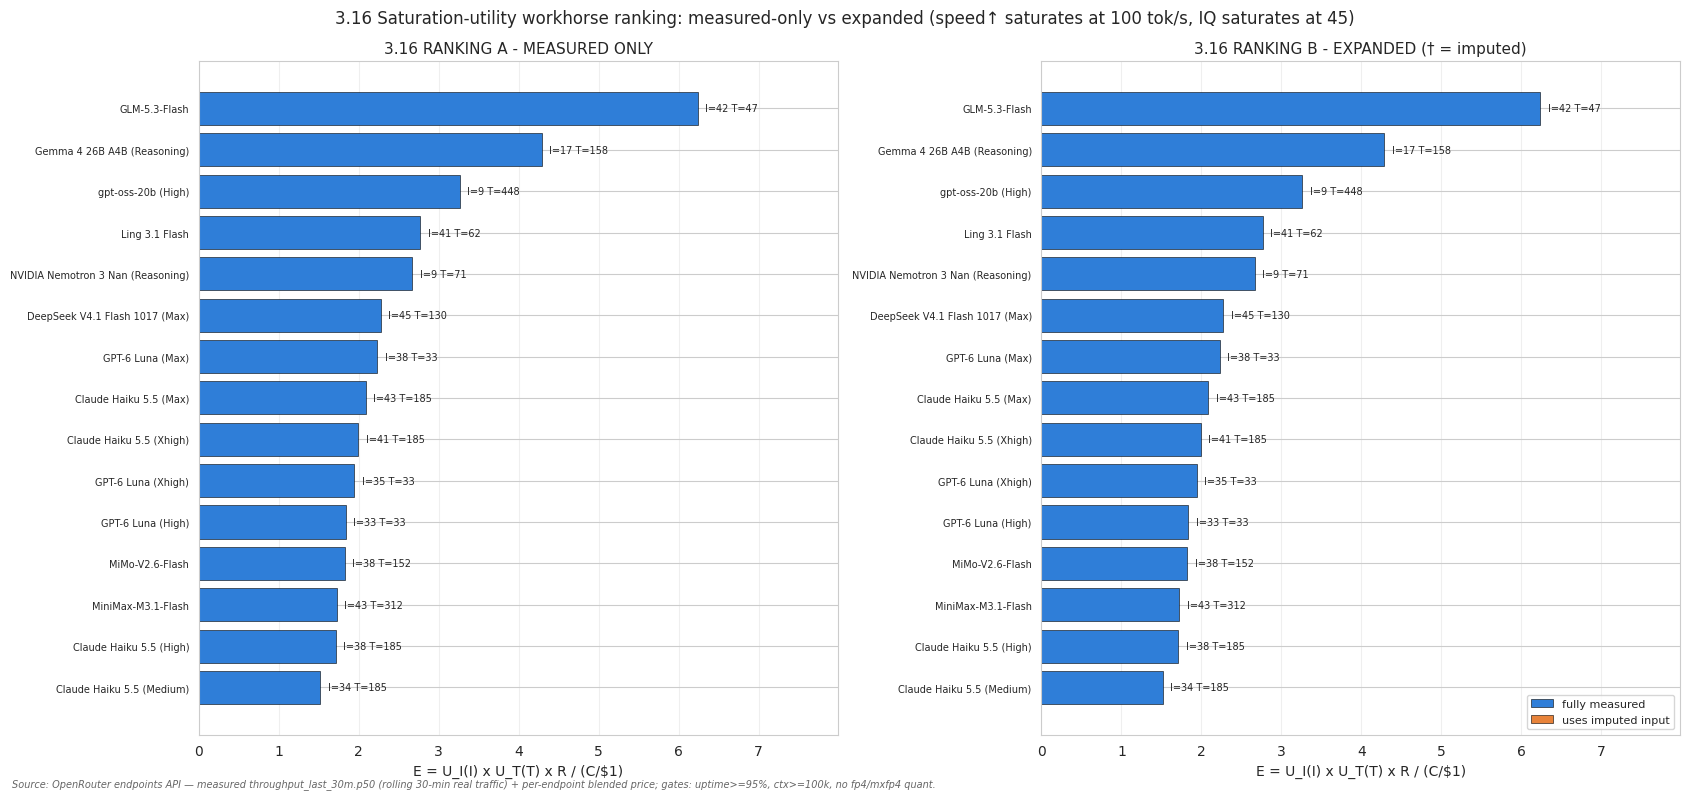


HOW SATURATION CHANGES THE CALL
  U_T: 50 tok/s = 78%, 100 tok/s = 95%, 200 tok/s = 100% of speed ceiling
  U_I: IQ 25 = 81%, 45 = 95%, 55 = 97%, 80 = 100% of IQ ceiling
  - vs 3.15 (SP = T^1.5/C): that metric still rewards raw I only through cost;
    here the IQ contribution saturates, so a 55-IQ flagship gains almost nothing
    over a 45-IQ model while still paying the price premium.
  - A 55-IQ model at $4.00/M and 38 tok/s (Kimi K3.1 Pro) lands far below the
    smart-enough cheap-fast set, exactly like in 3.15.


In [19]:
# ============================================================================
# 3.16 SATURATION-UTILITY WORKHORSE RANKING
# Methodology transferred from GDPval §3.4b (two rankings) and §3.4c
# (exponential speed utility), adapted so BOTH inputs saturate:
#   - SPEED saturates HIGH        : U_T(T) = 1 - exp(-T/tau_T), tau_T = 33.3
#     -> 100 tok/s already earns ~95% of the speed ceiling.
#   - INTELLIGENCE saturates LOW : U_I(I) = 1 - exp(-I/tau_I), tau_I = 15
#     -> IQ 45 already earns ~95% of the intelligence ceiling. Extra IQ above
#        ~45 gives almost no bonus - a workhorse only needs to be "smart enough".
#   Score: E = U_I(I) * U_T(T) * R / (C / C_ref), C_ref = $1.00/1M
#
# NOTE: effort levels — rows without a suffix (GLM-5.3-Flash, Kimi K3.1 Pro,
# MiMo-V2.6-*, ...) are single-default-config rows (mandatory reasoning at
# default effort); suffixed rows are AA-measured per-level variants.
# Two rankings exactly like GDPval 3.4b:
#   A - MEASURED ONLY (every input measured; no imputation)
#   B - EXPANDED (family-median fills allowed; T† / R† flagged)
# ============================================================================

import json, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── Saturation calibration ────────────────────────────────────────────────
T_GOOD = 100.0            # speed considered "good enough"
TAU_T = T_GOOD / 3.0      # 33.3 tok/s -> 100 tok/s ≈ 95% of ceiling
I_SMART = 45.0            # intelligence considered "smart enough" (saturates LOW)
TAU_I = I_SMART / 3.0     # 15 IQ -> 45 IQ ≈ 95% of ceiling
C_REF = 1.00              # $/1M reference

def U_T(T):
    return 1.0 - np.exp(-np.clip(T, 0, None) / TAU_T)

def U_I(I):
    return 1.0 - np.exp(-np.clip(I, 0, None) / TAU_I)

def scoreE(I, R, T, C):
    try:
        I, R, T, C = float(I), float(R), float(T), float(C)
    except (TypeError, ValueError):
        return np.nan
    if any(np.isnan(x) for x in (I, R, T, C)) or C <= 0 or T <= 0:
        return np.nan
    return U_I(I) * U_T(T) * R / (C / C_REF)

# ── Load provider cache, build the workhorse candidate set ────────────────
_CACHE = 'results/provider_value_by_model.json'
_recs = []
if os.path.exists(_CACHE):
    with open(_CACHE) as f:
        _cache = json.load(f)
    for _name, _rec in _cache.items():
        _a = _rec.get('aa') or {}
        _ep = _rec.get('chosen') or _rec.get('default') or {}
        _I, _R = _a.get('intel'), _a.get('reliab')
        _T, _C = _ep.get('tps'), _ep.get('price_blend')
        if not _T or not _C or float(_C) <= 0:
            continue
        try:
            _T, _C = float(_T), float(_C)
            _I = None if _I is None else float(_I)
            _R = None if _R is None else float(_R)
        except (TypeError, ValueError):
            continue
        _recs.append({'Model': _name, 'I': _I, 'R': _R, 'T': _T, 'C': _C})
else:
    print('WARNING: provider_value_by_model.json missing — run 3.11 first.')

_df0 = pd.DataFrame(_recs)
if _df0.empty:
    raise SystemExit('No provider data — cannot compute 3.16.')

# workhorse lens (same filter as 3.15) + always keep the Kimi reference
_is_kimi = _df0['Model'].astype(str).str.contains('kimi', case=False)
_warm = (_df0['C'] <= 1.50) | (_df0['T'] >= 60)
_df = _df0[_warm | _is_kimi].copy()

# ── Family key for imputation (same rule as GDPval 3.4b) ──────────────────
_sfx = re.compile(r'\s*\([^)]*\)\s*$')

def _fam(name):
    if not isinstance(name, str):
        return ''
    b = _sfx.sub('', name).strip().lower()
    b = re.sub(r'\s*\d{4}\s*$', '', b)
    b = re.sub(r'\b(preview|beta|adaptive)\b', '', b).strip()
    toks = [t for t in b.split() if not re.match(r'^\d+\.\d+$', t)]
    return ' '.join(toks[:3])

_df['Family'] = _df['Model'].map(_fam)

# ── RANKING A — measured only ─────────────────────────────────────────────
_df['E_A'] = _df.apply(lambda r: scoreE(r['I'], r['R'], r['T'], r['C']), axis=1)
_A = _df.dropna(subset=['E_A', 'I', 'R', 'T', 'C']).copy()
_A['Rank_A'] = _A['E_A'].rank(ascending=False, method='min')

# ── RANKING B — expanded (family-median fills, flagged) ────────────────────
_df['T_fill'] = False
_df['R_fill'] = False
_tmed = _df.groupby('Family')['T'].transform('median')
_rmed = _df.groupby('Family')['R'].transform('median')
_tmiss = _df['T'].isna() & _tmed.notna()
_rmiss = _df['R'].isna() & _rmed.notna()
_df.loc[_tmiss, 'T'] = _tmed[_tmiss]
_df.loc[_tmiss, 'T_fill'] = True
_df.loc[_rmiss, 'R'] = _rmed[_rmiss]
_df.loc[_rmiss, 'R_fill'] = True
_df['E_B'] = _df.apply(lambda r: scoreE(r['I'], r['R'], r['T'], r['C']), axis=1)
_B = _df[_df['E_B'].notna()].copy()
_B['Any_Imputed'] = _B['T_fill'] | _B['R_fill']
_B['Rank_B'] = _B['E_B'].rank(ascending=False, method='min')

# ── 3.15 SP rank for tie-in ────────────────────────────────────────────────
_df['SP'] = _df['T'] ** 1.5 / _df['C']
_SP = _df.dropna(subset=['SP']).copy()
_SP['Rank_SP'] = _SP['SP'].rank(ascending=False, method='min')
_rank_sp = _SP.set_index('Model')['Rank_SP'].to_dict()

# ── Print RANKING A ────────────────────────────────────────────────────────
print('\n' + '=' * 120)
print('3.16 RANKING A - MEASURED ONLY (saturating speed HIGH at 100 tok/s, '
      'saturating IQ LOW at 45)')
print('  E = U_I(I) * U_T(T) * R / (C/$1.00)   |   no imputation')
print('=' * 120)
print(f"Rows: {len(_A)}  |  candidates after workhorse filter: {len(_df)}")
print(f"{'#':<3}{'model':<40}{'E':>9}{'U_I':>6}{'U_T':>6}{'I':>6}{'R':>6}"
      f"{'T tok/s':>8}{'$/1M':>7}{'SP rank':>8}")
print('-' * 120)
for _i, (_, r) in enumerate(_A.sort_values('E_A', ascending=False).head(25).iterrows(), 1):
    _sp = _rank_sp.get(r['Model'])
    _sp_s = 'n/a' if _sp is None else f'{int(_sp):>8}'
    print(f"{_i:<3}{fam_label(r['Model'], 44):<46}{r['E_A']:>9.2f}{U_I(r['I']):>6.2f}"
          f"{U_T(r['T']):>6.2f}{r['I']:>6.1f}{r['R']:>6.2f}"
          f"{r['T']:>8.0f}{r['C']:>7.2f}{_sp_s}")

# ── Print RANKING B ────────────────────────────────────────────────────────
print('\n' + '=' * 120)
print('3.16 RANKING B - EXPANDED (family-median fills allowed; flagged T† / R†)')
print('=' * 120)
print(f"Rows: {len(_B)}  |  rows using any imputed input: {int(_B['Any_Imputed'].sum())}")
print(f"{'#':<3}{'model':<40}{'E':>9}{'I':>6}{'R':>6}{'T tok/s':>8}{'$/1M':>7}"
      f"{'SP rank':>8}  flags")
print('-' * 120)
for _i, (_, r) in enumerate(_B.sort_values('E_B', ascending=False).head(25).iterrows(), 1):
    _flags = []
    if r['T_fill']:
        _flags.append('T†')
    if r['R_fill']:
        _flags.append('R†')
    _f_s = ','.join(_flags) if _flags else '-'
    _sp = _rank_sp.get(r['Model'])
    _sp_s = 'n/a' if _sp is None else f'{int(_sp):>8}'
    print(f"{_i:<3}{fam_label(r['Model'], 44):<46}{r['E_B']:>9.2f}{r['I']:>6.1f}"
          f"{r['R']:>6.2f}{r['T']:>8.0f}{r['C']:>7.2f}{_sp_s}  {_f_s}")

# ── Reference model status (Kimi K3.1 Pro) ─────────────────────────────────
_kimi = _B[_B['Model'].astype(str).str.contains('kimi', case=False)]
if len(_kimi):
    r = _kimi.iloc[0]
    _sp = _rank_sp.get(r['Model'])
    print('\n' + '-' * 120)
    print('REFERENCE MODEL STATUS (Kimi K3.1 Pro — force-included, not a workhorse):')
    print(f"  {r['Model']}: I={r['I']:.1f} (U_I={U_I(r['I']):.2f}), "
          f"T={r['T']:.0f} tok/s (U_T={U_T(r['T']):.2f}), "
          f"R={r['R']:.2f}, C=${r['C']:.2f}/M → E={r['E_B']:.3f} "
          f"(rank {int(r['Rank_B'])}/{len(_B)}, SP rank {int(_sp) if _sp is not None else 'n/a'})")
    print('  Its high IQ barely helps under saturating-U_I (55 vs 45 = 97% vs 95%);')
    print('  the $4.00/M price + 38 tok/s measured speed sink its score.')

# ── Rank movement A -> B + SP tie-in ───────────────────────────────────────
_mv = _A[['Model', 'E_A']].copy()
_mv['Rank_A'] = _mv['E_A'].rank(ascending=False, method='min')
_b2 = _B[['Model', 'E_B', 'Any_Imputed']].copy()
_b2['Rank_B'] = _b2['E_B'].rank(ascending=False, method='min')
_common = _mv.merge(_b2, on='Model', how='inner')
if len(_common):
    _common['Move'] = _common['Rank_A'] - _common['Rank_B']
    _common['SP_rank'] = _common['Model'].map(_rank_sp)
    print('\n' + '-' * 120)
    print('RANK MOVEMENT (measured-only -> expanded), models present in both:')
    print(f"  compared: {len(_common)}  |  moved up: {int((_common['Move'] > 0).sum())}"
          f"  |  moved down: {int((_common['Move'] < 0).sum())}"
          f"  |  unchanged: {int((_common['Move'] == 0).sum())}")
    _movers = _common[_common['Move'] != 0].sort_values('Move', key=abs, ascending=False)
    for _, r in _movers.head(10).iterrows():
        _sp = '' if pd.isna(r['SP_rank']) else f'  (SP rank {int(r["SP_rank"])})'
        print(f"    {fam_label(r['Model'], 46):<48} {int(r['Rank_A']):>3} -> {int(r['Rank_B']):>3}"
              f"  ({r['Move']:+.0f}){'  [imputed]' if r['Any_Imputed'] else ''}{_sp}")

# ── Plot: side-by-side top-15 A vs B ───────────────────────────────────────
_fig, _axes = plt.subplots(1, 2, figsize=(17, 8))
for _ax, _frame, _col, _title in [
    (_axes[0], _A, 'E_A', '3.16 RANKING A - MEASURED ONLY'),
    (_axes[1], _B, 'E_B', '3.16 RANKING B - EXPANDED († = imputed)'),
]:
    # TOP-15 BY SCORE (not the first 15 rows of the frame) — Bug A fix.
    _top = _frame.sort_values(_col, ascending=False).head(15).sort_values(_col)
    _colors = []
    for _, r in _top.iterrows():
        if _title.startswith('3.16 RANKING B') and r.get('Any_Imputed', False):
            _colors.append('#e8833a')
        else:
            _colors.append('#2f7ed8')
    _ax.barh(np.arange(len(_top)), _top[_col], color=_colors,
             edgecolor='black', linewidth=0.4)
    _xmax = float(_top[_col].max()) if len(_top) and np.isfinite(_top[_col].max()) else 1.0
    for _y, (_, _r) in enumerate(_top.iterrows()):
        _ax.text(_r[_col] + 0.015 * _xmax, _y,
                 f"I={_r['I']:.0f} T={_r['T']:.0f}", va='center', fontsize=7)
    _ax.set_xlim(0, _xmax * 1.28)
    _ax.set_yticks(np.arange(len(_top)))
    _ax.set_yticklabels([fam_label(m, 32) for m in _top['Model']], fontsize=7)
    _ax.set_xlabel('E = U_I(I) x U_T(T) x R / (C/$1)')
    _ax.set_title(_title, fontsize=11)
    _ax.grid(axis='x', alpha=0.3)
_axes[1].legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color='#2f7ed8', ec='black', lw=.4),
    plt.Rectangle((0, 0), 1, 1, color='#e8833a', ec='black', lw=.4),
], labels=['fully measured', 'uses imputed input'], fontsize=8, loc='lower right')
_fig.suptitle('3.16 Saturation-utility workhorse ranking: measured-only vs expanded '
              '(speed↑ saturates at 100 tok/s, IQ saturates at 45)', fontsize=12)
plt.tight_layout()
note_source(SRC_OR_TEL)
plt.show()

# ── How the saturation changes the call ────────────────────────────────────
print('\n' + '=' * 120)
print('HOW SATURATION CHANGES THE CALL')
print('=' * 120)
print(f"  U_T: 50 tok/s = {U_T(50):.0%}, 100 tok/s = {U_T(100):.0%}, "
      f"200 tok/s = {U_T(200):.0%} of speed ceiling")
print(f"  U_I: IQ 25 = {U_I(25):.0%}, 45 = {U_I(45):.0%}, 55 = {U_I(55):.0%}, "
      f"80 = {U_I(80):.0%} of IQ ceiling")
print('  - vs 3.15 (SP = T^1.5/C): that metric still rewards raw I only through cost;')
print('    here the IQ contribution saturates, so a 55-IQ flagship gains almost nothing')
print('    over a 45-IQ model while still paying the price premium.')
print('  - A 55-IQ model at $4.00/M and 38 tok/s (Kimi K3.1 Pro) lands far below the')
print('    smart-enough cheap-fast set, exactly like in 3.15.')

## 3.17 Time-per-Task Efficiency (all reasoning variants, TF axis)

Repeats the §3.4 multiplicative analysis with the speed axis **inverted**: instead of
`tok/s (higher = better)`, we report **seconds per 1k output tokens (lower = better)** —
the number a user actually experiences waiting for an answer.

- **Formula**: `Efficiency_TF = (Intel × Reliability) / sqrt(TF) × C_ref/C` where
  `TF = 1000/tok_s` seconds per 1k output tokens. Same monotone ordering logic as 3.4
  (√-compression of the speed axis) but reported in wall-clock units.
- **All reasoning variants included and labeled**: rows are the AA per-effort variants
  — Max / Xhigh / High / Medium / Low / Reasoning / Non-reasoning — each scored on its
  OWN measured intelligence, speed and price (verified: multi-variant families differ
  per level, e.g. Claude Opus 5.5: Max 94.8 tok/s vs Xhigh 77.2 vs Medium 69.0).
- **Rows without a suffix** (GLM-5.3-Flash, Kimi K3.1 Pro, MiMo-V2.6-*, …) are
  single-default configurations (mandatory reasoning at the provider default effort),
  labeled `(default effort)` in the comparison tables below.
- **Speed source**: AA `median_output_tokens_per_second` (lab benchmark) enriched with
  OpenRouter endpoint telemetry where available.


3.17 TIME-PER-TASK: 76 rows | 13 default-effort (no AA suffix) | 63 labeled effort variants
TF range: 2.2 - 35.4 s per 1k output tokens

3.17 TOP 25 — TIME-PER-TASK EFFICIENCY (lower TF = snappier)
#   model (variant)                                TF s/1k  tok/s     I    R   $/1M  Eff_TF
-------------------------------------------------------------------------------------------
1   Claude Haiku 5.5 (Max)                             4.2    237  36.2 0.44   0.20    39.1
2   Claude Haiku 5.5 (Xhigh)                           5.7    177  34.3 0.43   0.20    30.8
3   Claude Haiku 5.5 (High)                            6.3    160  29.6 0.37   0.20    22.1
4   GPT-6 Luna (Max)                                   8.1    123  27.8 0.39   0.20    18.8
5   MiniMax-M3.1-Flash                                 8.6    116  28.9 0.48   0.26    18.0 <default effort>
6   Claude Haiku 5.5 (Medium)                          6.6    152  24.6 0.34   0.20    16.2
7   GPT-6 Luna (Xhigh)                           

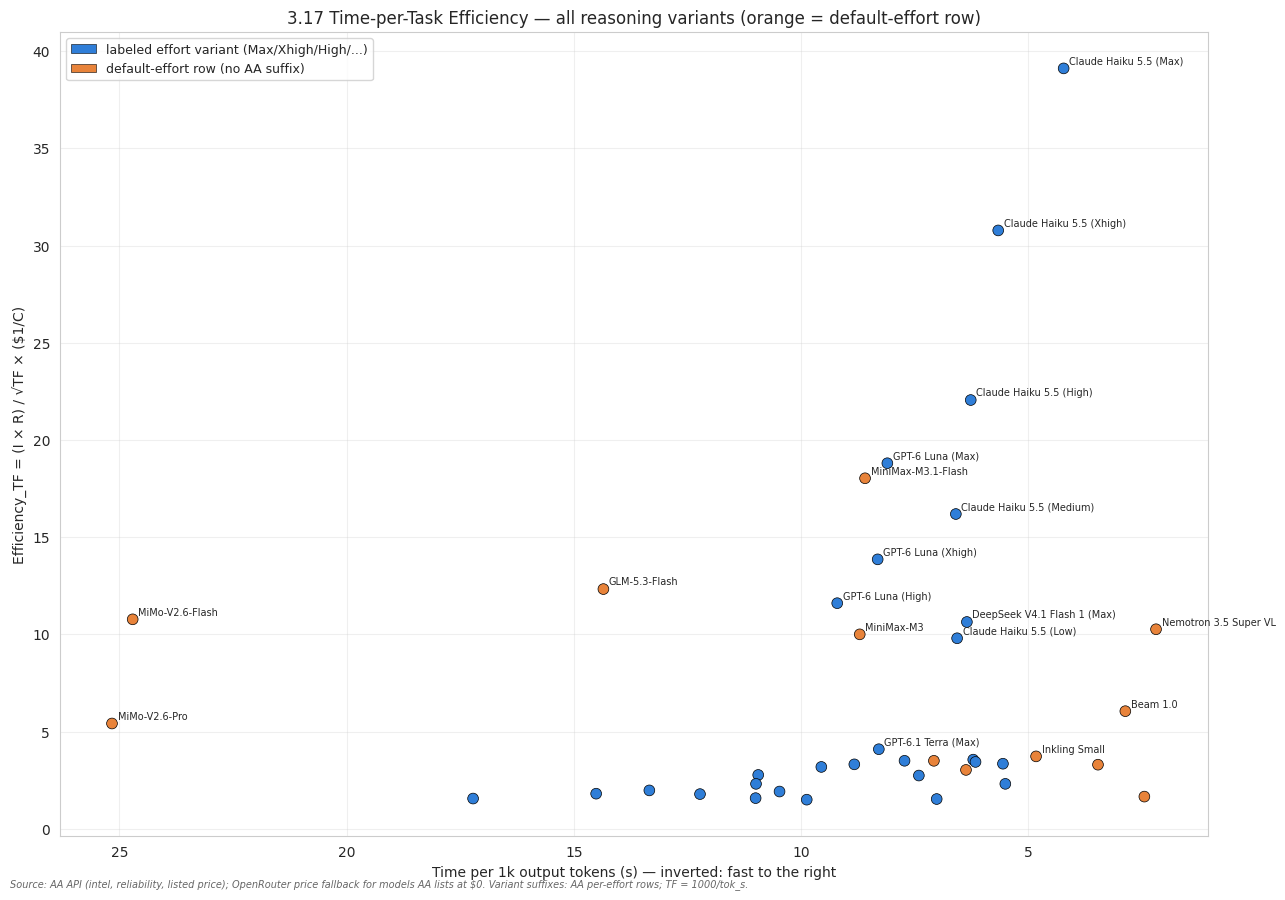


Per-family effort ladder (families with >=3 scored variants):
  claude fable 5.1         Max: TF=14.7s I=49 E=0.4  Xhigh: TF=17.8s I=50 E=0.3  Medium: TF=19.0s I=43 E=0.3  High: TF=19.9s I=47 E=0.3  Low: TF=19.9s I=38 E=0.2
  claude haiku 5.5         Max: TF=4.2s I=36 E=39.1  Xhigh: TF=5.7s I=34 E=30.8  High: TF=6.3s I=30 E=22.1  Low: TF=6.6s I=19 E=9.8  Medium: TF=6.6s I=25 E=16.2
  claude opus 5.5          Max: TF=10.2s I=58 E=1.4  Xhigh: TF=12.3s I=57 E=1.2  High: TF=13.1s I=52 E=1.0  Low: TF=13.8s I=34 E=0.6  Medium: TF=13.8s I=48 E=0.9
  claude sonnet 5.5        Max: TF=7.4s I=54 E=2.7  High: TF=9.9s I=41 E=1.5  Xhigh: TF=10.5s I=50 E=1.9  Medium: TF=10.9s I=30 E=0.9  Low: TF=11.1s I=25 E=0.7
  gpt-6 astra              Max: TF=13.1s I=57 E=0.4  Xhigh: TF=14.0s I=55 E=0.4  High: TF=15.7s I=55 E=0.4  Medium: TF=17.2s I=52 E=0.3  Low: TF=17.8s I=43 E=0.3
  gpt-6 luna               Max: TF=8.1s I=28 E=18.8  Xhigh: TF=8.3s I=23 E=13.9  Low: TF=8.8s I=10 E=3.3  Non-reasoning: TF=9.1s I

In [20]:
# ============================================================================
# 3.17 TIME-PER-TASK EFFICIENCY — same population as 3.4, inverted speed axis
#   TF  = 1000 / T            seconds per 1k output tokens (lower = better)
#   eff = (I * R) / sqrt(TF) * (C_ref / C)     C_ref = $1.00/1M
# All AA variant rows kept (Max/Xhigh/High/Medium/Low/Reasoning/Non-reasoning),
# each scored on its own measured intel/speed/price.
# ============================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re

C_REF_TF = 1.00

_tfdf = df.copy()
if 'Model' not in _tfdf.columns:
    _tfdf = _tfdf.rename(columns={'name': 'Model'})

_tfdf['I'] = pd.to_numeric(_tfdf['AA_Intelligence_Index'], errors='coerce')
_tfdf['R'] = (1 - pd.to_numeric(_tfdf['AA_Hallucination_Rate'], errors='coerce')).clip(lower=0)
_tfdf['T'] = pd.to_numeric(_tfdf.get('median_output_tokens_per_second'), errors='coerce')
_cost = pd.to_numeric(_tfdf.get('Price_Blended_USD_per_1M'), errors='coerce')
if 'Price_Blended_USD_per_1M' not in _tfdf.columns or _cost.isna().all():
    _pin = pd.to_numeric(_tfdf.get('Price_Input_1M'), errors='coerce')
    _pout = pd.to_numeric(_tfdf.get('Price_Output_1M'), errors='coerce')
    _cost = (_pin * 3 + _pout) / 4
_tfdf['C'] = _cost

# variant label (for display) + default-effort flag
_tfdf['Variant'] = _tfdf['Model'].map(lambda m: variant_of(m))
_tfdf['Default_Effort'] = _tfdf['Variant'] == ''
_tfdf['Label'] = _tfdf['Model'].map(lambda m: fam_label(m, 42))

# only rows with ALL inputs measurable; T>0 as measured (0 = AA never speed-tested)
# Family-median imputation for missing reliability (same rule as 3.3/3.4) so
# rows AA never IFBench-tested aren't silently dropped from the TF ranking.
_tplut = re.compile(r'\s*\([^)]*\)\s*$')
def _tf_fam(n):
    b = _tplut.sub('', n).strip().lower()
    b = re.sub(r'\s*\d{4}\s*$', '', b)
    return ' '.join(b.split()[:3])
_tfdf['Reliability_Imputed'] = False
_fam_r = _tfdf.groupby(_tfdf['Model'].map(_tf_fam))['R'].median()
_hit = _tfdf['Model'].map(_tf_fam).map(_fam_r)
_imp = _tfdf['R'].isna() & _hit.notna()
_tfdf.loc[_imp, 'R'] = _hit[_imp]
_tfdf.loc[_imp, 'Reliability_Imputed'] = True

_ok = _tfdf[(_tfdf['T'] > 0) & _tfdf['I'].notna() & _tfdf['R'].notna() & (_tfdf['C'] > 0)].copy()
_ok['R_imputed'] = _ok['Reliability_Imputed']
_ok['TF'] = 1000.0 / _ok['T']                       # seconds per 1k tok
_ok['Eff_TF'] = (_ok['I'] * _ok['R'] / np.sqrt(_ok['TF'])) * (C_REF_TF / _ok['C'])
_ok = _ok.sort_values('Eff_TF', ascending=False)

_n_def = int(_ok['Default_Effort'].sum())
print(f"3.17 TIME-PER-TASK: {len(_ok)} rows | {_n_def} default-effort (no AA suffix) | "
      f"{len(_ok) - _n_def} labeled effort variants")
print(f"TF range: {_ok['TF'].min():.1f} - {_ok['TF'].max():.1f} s per 1k output tokens")

_hdr = f"{'#':<4}{'model (variant)':<46}{'TF s/1k':>8}{'tok/s':>7}{'I':>6}{'R':>5}{'$/1M':>7}{'Eff_TF':>8}"
print('\n' + '=' * len(_hdr) + '\n3.17 TOP 25 — TIME-PER-TASK EFFICIENCY (lower TF = snappier)\n' + '=' * len(_hdr))
print(_hdr); print('-' * len(_hdr))
for _i, (_, r) in enumerate(_ok.head(25).iterrows(), 1):
    _tag = ' <default effort>' if r['Default_Effort'] else ''
    if r.get('R_imputed'):
        _tag += ' R*'
    print(f"{_i:<4}{r['Label']:<46}{r['TF']:>8.1f}{r['T']:>7.0f}"
          f"{r['I']:>6.1f}{r['R']:>5.2f}{r['C']:>7.2f}{r['Eff_TF']:>8.1f}{_tag}")

# ── comparison vs tok/s axis (3.4 ordering): how much does the ranking change? ──
_ok['Rank_TF'] = _ok['Eff_TF'].rank(ascending=False, method='min')
_ok['Rank_TPS'] = _ok['T'].rank(ascending=False, method='min')   # raw speed order
_common = _ok.copy()
_common['Move'] = _common['Rank_TPS'] - _common['Rank_TF']
print('\nAxis comparison (efficiency-with-time vs raw-speed ordering):')
print(f"  rows compared: {len(_common)}")
_big = _common[_common['Move'].abs() >= 5].sort_values('Move', key=lambda s: -s.abs())
print(f"  rows moving >=5 ranks between axes: {len(_big)}")
print(f"  {'model (variant)':<46}{'TF s/1k':>8}{'tok/s':>7}{'rank TPS':>9}{'rank TF':>8}{'move':>6}")
for _, r in _big.head(12).iterrows():
    print(f"  {r['Label']:<46}{r['TF']:>8.1f}{r['T']:>7.0f}"
          f"{int(r['Rank_TPS']):>9}{int(r['Rank_TF']):>8}{int(r['Move']):>+6}")

# ── plot: dual-axis scatter TF vs Eff_TF, color by default-vs-labeled effort ──
plt.figure(figsize=(13, 9))
_sub = _ok.head(40)
_cls = ['#e8833a' if d_ else '#2f7ed8' for d_ in _sub['Default_Effort']]
plt.scatter(_sub['TF'], _sub['Eff_TF'], c=_cls, s=60, edgecolor='black', linewidth=0.5, zorder=3)
for _, r in _sub.head(18).iterrows():
    plt.annotate(fam_label(r['Model'], 26), (r['TF'], r['Eff_TF']),
                 fontsize=7, xytext=(4, 3), textcoords='offset points')
plt.gca().invert_xaxis()   # faster (lower TF) to the right
plt.xlabel('Time per 1k output tokens (s) — inverted: fast to the right')
plt.ylabel('Efficiency_TF = (I × R) / √TF × ($1/C)')
plt.title('3.17 Time-per-Task Efficiency — all reasoning variants (orange = default-effort row)')
plt.legend(handles=[
    plt.Rectangle((0,0),1,1,color='#2f7ed8',ec='black',lw=.4),
    plt.Rectangle((0,0),1,1,color='#e8833a',ec='black',lw=.4)],
    labels=['labeled effort variant (Max/Xhigh/High/...)', 'default-effort row (no AA suffix)'],
    fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
note_source(SRC_AA_OR + ' Variant suffixes: AA per-effort rows; TF = 1000/tok_s.')
plt.show()

# ── per-family variant comparison: which effort level is the efficiency sweet spot? ──
_tf_fkey = _tf_fam  # same family key as the imputation block above
_ok2 = _ok.copy()
_ok2['fam'] = _ok2['Model'].map(_tf_fkey)
_multi = _ok2.groupby('fam').filter(lambda g: len(g) >= 3)
if len(_multi):
    print('\nPer-family effort ladder (families with >=3 scored variants):')
    for f, g in _multi.groupby('fam'):
        g = g.sort_values('TF')
        line = '  '.join(f"{r['Variant'] or 'default'}: TF={r['TF']:.1f}s I={r['I']:.0f} E={r['Eff_TF']:.1f}"
                         for _, r in g.iterrows())
        print(f"  {f:<24} {line}")

df_time = _ok.copy()


## 3.17b Saturation Utility on AA Time-per-Task (official metric, quartile-calibrated)

Same saturating-utility shape as **3.16**, but the time axis is AA's **official Time per Task** —
the weighted-average wall-clock time to complete one AA Intelligence Index task
(answer + reasoning tokens ÷ answer output speed, weighted by the Index's per-benchmark
weights). This is AA's own published task-completion measurement, not a synthetic estimate.

- **Source**: AA leaderboard page (the free v2 API does not expose Time per Task), scraped
  2026-10-25 and cached to `results/aa_leaderboard_scrape.json` — 161 models with TPT.
  Examples: Claude Opus 5.5 (max) **688 s**/task vs Kimi K3.1 Pro **2.97 s**/task.
- **Empirical saturation cutoff**: the **fastest quartile (25th percentile) of TPT** across
  all scored rows → `U_TPT(TPT_GOOD) = 0.95`, decaying as `U = 1 − exp(−k/TPT)`.
- Intelligence utility unchanged from 3.16 (`U_I = 1 − exp(−I/15)`); score shape identical:
  `E2 = U_I × U_TPT × R / (C/$1)`.
- **Paired rankings** mirror 3.16: A = measured only, B = expanded (R† flags). Default-effort
- **OpenRouter real prices are shown on every bar**: `OR best` = the best-value endpoint
  (highest √tok/s ÷ price among endpoints passing the quality gates) and `OR cheap` = the
  cheapest blended-price endpoint on that model (what the router tends to pick). Both are
  per-endpoint blended $/1M from the OpenRouter endpoints API, cached in
  `results/provider_value_by_model.json`. The score itself still divides by AA's **listed**
  price (`AA $/M`), so the annotation shows how far real-world cost can drift from the
  listed figure.
- **Strict variant matching**: a row only inherits a Time-per-Task value when its
  reasoning-effort variant matches exactly — a `(Max)` row never borrows a
  `(Non-reasoning)` row's TPT.
- **Set points are plotted**: the third panel draws the saturation curve
  `U_TPT(x) = 1 − exp(−k/x)` on a log time axis and marks the **50% / 75% / 95% / 99%**
  utility set points. Solving `x(u) = k / −ln(1−u)` gives the wall-clock time at
  which each utility level is reached. The **95% set point IS the calibration anchor**:
  by construction `U_TPT(TPT_GOOD) = 0.95`, so the fastest quartile of measured
  Time-per-Task is exactly where diminishing returns begin. The orange line marks
  `TPT_GOOD` (p25) and the purple dots are the scored models on the curve.
- **Cost measurements per model**: because Time-per-Task is a wall-clock duration,
  the output tokens a task produces are recoverable as `TPT × speed(tok/s)`. From
  there each model gets:
  - `$/task` — what one AA Intelligence Index task costs at AA's listed blended price,
  - `OR $/task` — the same task priced on the OpenRouter best-value endpoint,
  - `$/1k output tokens` — the verbosity-normalised rate.

  Both are shown in the ranking tables and on every bar.
  rows (no AA suffix) are flagged `def`/purple. **No scatter plot** — bars only, directly
  comparable with 3.16.
- Built-in ordering comparison vs 3.16 (tok/s axis) and 3.17 (TF s/1k axis).


Loaded AA leaderboard scrape: 272 rows (161 with Time per Task)
OpenRouter prices joined: 40/67 rows (best-value + cheapest provider)
3.17b calibration: TPT_GOOD (fastest-quartile p25) = 2.10 s/task  ->  U_TPT(TPT_GOOD) = 0.95
  rows scored: 67  |  default-effort rows: 14
  TPT range: 0.58 - 688.0 s per task

3.17b RANKING A - MEASURED ONLY   E2 = U_I(I) * U_TPT(TPT) * R / (C/$1)
#   model (variant)                             E2   U_I U_TPT   TPT s     I    R  AA $/M   $/task OR best $/M OR cheap $/M  OR $/task  flags
--------------------------------------------------------------------------------------------------------------------------------------------------------
1   MiniMax-M3.1-Flash                        1.56  0.85  1.00     1.1  28.9 0.48    0.26$0.0000335$0.26 Parasail$0.21 InferenceN $0.0000335  def
2   MiMo-V2.6-Flash                           1.42  0.83  0.85     3.3  26.7 0.35    0.18$0.0000290$0.18 Cohere$0.11 DeepInfra $0.0000290  def
3   GLM-5.3-Flash                

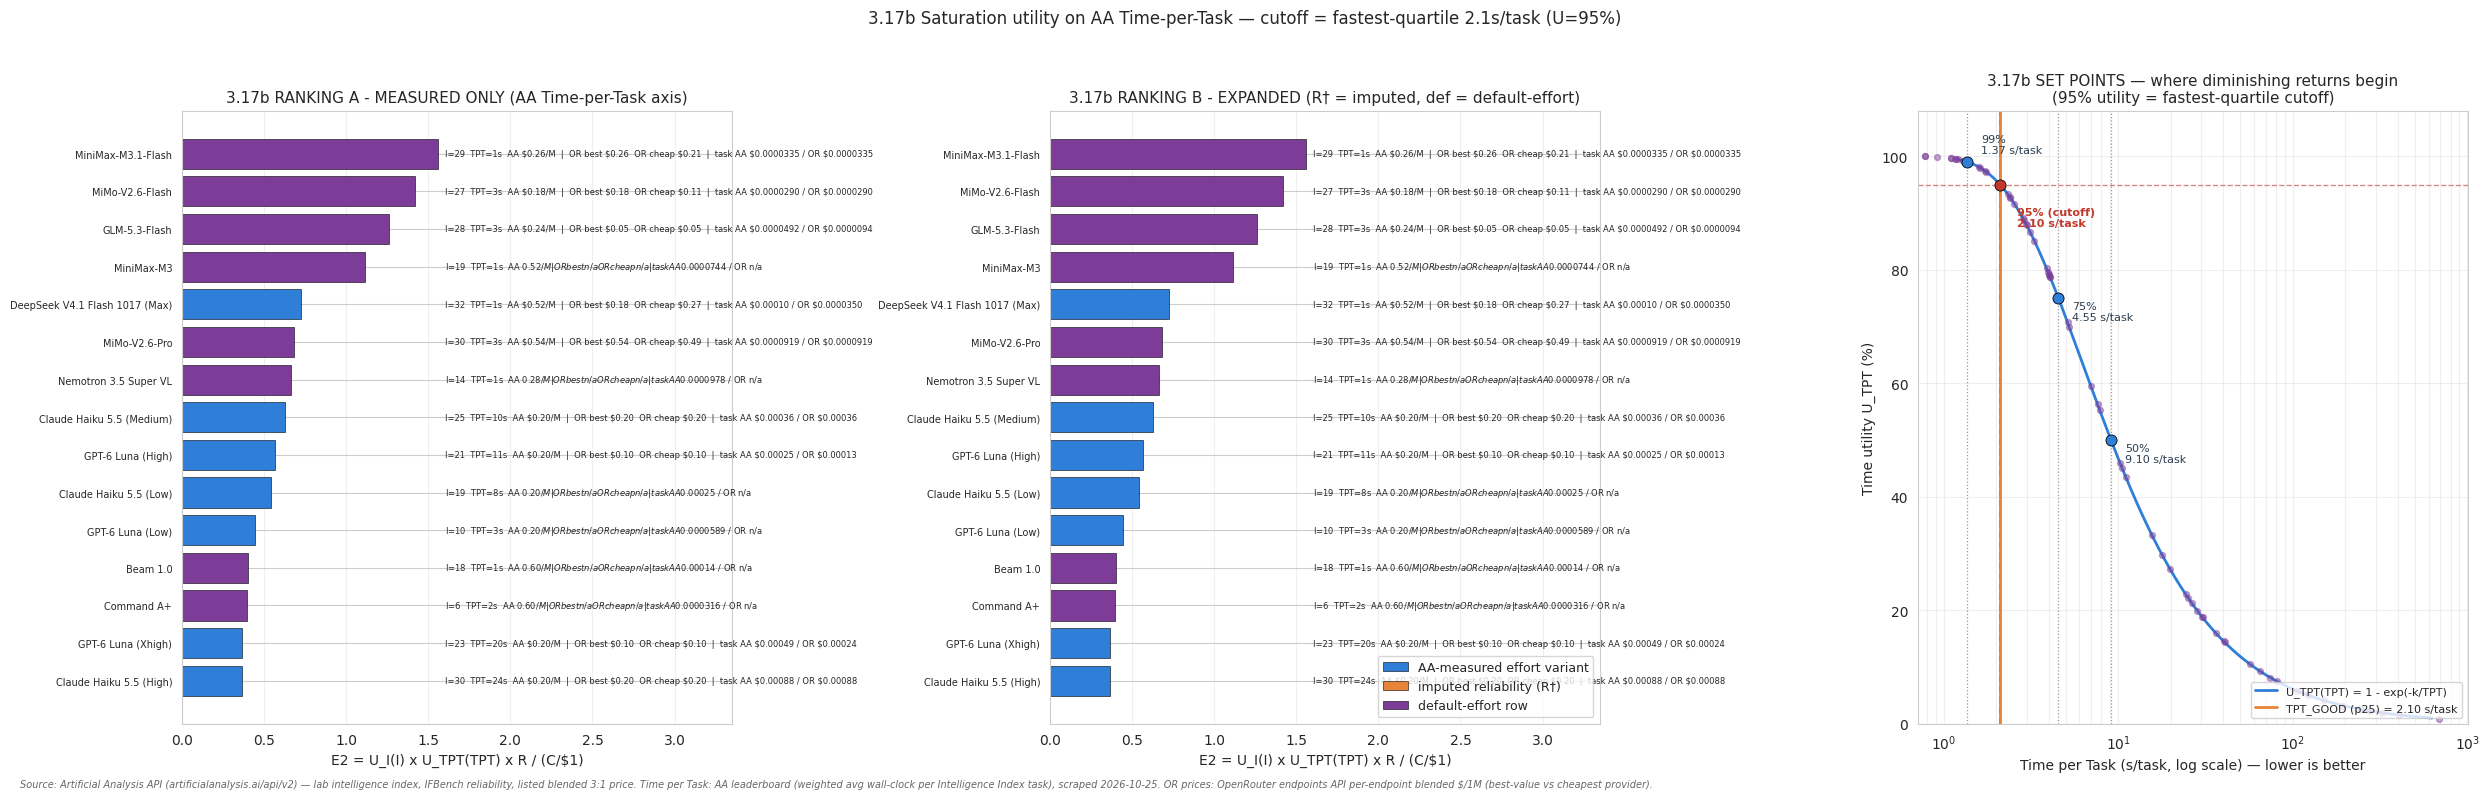


Ordering comparison vs 3.16 (tok/s saturation): 29 common rows, 13 move >=5 ranks
  model (variant)                                rank old rank new  move
  Claude Sonnet 5.5 (Max)                                14       27   +13
  Claude Fable 5.1 (Low)                                 29       18   -11
  Claude Haiku 5.5 (Max)                                  4       15   +11
  Claude Opus 5.5 (Max)                                  20       29    +9
  GPT-6 Luna (Max)                                        3       12    +9
  MiniMax-M3.1-Flash                                      9        1    -8
  Claude Fable 5.1 (Medium)                              28       21    -7
  MiMo-V2.6-Pro                                          12        5    -7
  Kimi K3.1 Pro                                          19       13    -6
  MiMo-V2.6-Flash                                         8        2    -6

Ordering comparison vs 3.17 (TF s/1k): 66 common rows, 53 move >=5 ranks
  model (variant)   

In [21]:
# ============================================================================
# 3.17b SATURATION UTILITY ON AA's OFFICIAL TIME-PER-TASK (scraped leaderboard)
# ----------------------------------------------------------------------------
# Measurement: AA "Time per Task" — the weighted-average wall-clock time to
# complete one AA Intelligence Index task (answer + reasoning tokens / answer
# output speed, weighted by the Index's per-benchmark weights). This is AA's
# OWN published task-completion time, NOT a synthetic TTFT+stream estimate.
#   Source: https://artificialanalysis.ai/leaderboards/models (HTML table),
#   cached to results/aa_leaderboard_scrape.json (161 models with TPT).
#   Examples: Claude Opus 5.5 (max) 688 s | Kimi K3.1 Pro 2.97 s.
#
# Saturation cutoff is EMPIRICAL: the fastest quartile (25th percentile) of
# Time-per-Task across all scored rows -> U_TPT(TPT_GOOD) = 0.95.
#   U_TPT(x) = 1 - exp(-k / x),  k = -TPT_GOOD * ln(0.05)   (lower = better)
# Intelligence utility unchanged: U_I = 1 - exp(-I/15)  (IQ45 ~ 95%).
#
# Score: E2 = U_I(I) * U_TPT(TPT) * R / (C / $1.00)
# Rankings mirror 3.16: A = measured-only, B = expanded (flagged). No scatter.
# ============================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re, os, requests, json

# ── 1. Load AA Time-per-Task (scrape cache; refresh if missing) ────────────
_TPT_CACHE = 'results/aa_leaderboard_scrape.json'
if os.path.exists(_TPT_CACHE):
    _lb = json.load(open(_TPT_CACHE))
    print(f'Loaded AA leaderboard scrape: {len(_lb)} rows '
          f'({sum(1 for r in _lb if r.get("time_per_task_s") is not None)} with Time per Task)')
else:
    _resp = requests.get('https://artificialanalysis.ai/leaderboards/models',
                         headers={'User-Agent': 'Mozilla/5.0'}, timeout=60)
    print('WARNING: scrape cache missing; live scrape not implemented in-cell. '
          'Run scripts/scrape_aa_leaderboard.py first.')
    _lb = []

_tpt_map = {}
_spd_map = {}
for _r in _lb:
    if _r.get('time_per_task_s') is not None:
        _tpt_map[_r['name']] = float(_r['time_per_task_s'])
    if _r.get('speed_tps') is not None:
        _spd_map[_r['name']] = float(_r['speed_tps'])

# ── 2. Join TPT onto the v2-API frame (name normalization: leaderboard uses
#      'max with fallback' style suffixes; API uses '(Max, Default Fallback)') ──
_b17 = df.copy()
if 'Model' not in _b17.columns:
    _b17 = _b17.rename(columns={'name': 'Model'})

def _norm_lb(s):
    s = str(s).lower()
    s = re.sub(r'\s*\(([^)]*)\)\s*$', '', s)
    s = re.sub(r'[^a-z0-9]+', '', s)
    return s

def _norm_api(s):
    s = str(s).lower()
    s = re.sub(r'\s*\(([^)]*)\)\s*$', '', s)
    s = re.sub(r'[^a-z0-9]+', '', s)
    return s

# leaderboard suffix -> API variant tag, for labeling
_LB2VAR = {'max with fallback': 'Max', 'xhigh with fallback': 'Xhigh',
           'high with fallback': 'High', 'medium with fallback': 'Medium',
           'low with fallback': 'Low', 'non-reasoning': 'Non-reasoning',
           'reasoning': 'Reasoning', 'max': 'Max', 'xhigh': 'Xhigh',
           'high': 'High', 'medium': 'Medium', 'low': 'Low'}

def _lb_variant(s):
    m = re.search(r'\(([^)]+)\)\s*$', str(s))
    if not m:
        return ''
    v = m.group(1).strip().lower()
    return _LB2VAR.get(v, v)

# build lookup: normalized base name + LOWERCASE variant -> TPT
# Keys are lowercased so the lookup matches variant_of() output exactly.
_tpt_lookup = {}
for _name, _t in _tpt_map.items():
    _v = _lb_variant(_name).lower()
    _base = _norm_lb(_name)
    _tpt_lookup[(_base, _v)] = _t

def _find_tpt(model):
    """Strict variant-aware TPT lookup.

    A row only inherits a Time-per-Task value when the reasoning-effort
    variant matches EXACTLY. No cross-variant imputation: a (Max) row never
    borrows a (Non-reasoning) row's TPT, because the two configurations
    complete tasks in very different wall-clock time.
    """
    v = variant_of(model).lower()
    base = _norm_api(model)
    return _tpt_lookup.get((base, v), np.nan)

# same strict rule for output speed (needed to convert TPT -> output tokens)
_spd_lookup = {}
for _name, _sp in _spd_map.items():
    _spd_lookup[(_norm_lb(_name), _lb_variant(_name).lower())] = _sp

def _find_spd(model):
    v = variant_of(model).lower()
    base = _norm_api(model)
    return _spd_lookup.get((base, v), np.nan)

_b17['TPT'] = _b17['Model'].map(_find_tpt)
_b17['R'] = (1 - pd.to_numeric(_b17['AA_Hallucination_Rate'], errors='coerce')).clip(lower=0)
_b17['I'] = pd.to_numeric(_b17['AA_Intelligence_Index'], errors='coerce')
_cost = pd.to_numeric(_b17.get('Price_Blended_USD_per_1M'), errors='coerce')
if 'Price_Blended_USD_per_1M' not in _b17.columns or _cost.isna().all():
    _pin17 = pd.to_numeric(_b17.get('Price_Input_1M'), errors='coerce')
    _pout17 = pd.to_numeric(_b17.get('Price_Output_1M'), errors='coerce')
    _cost = (_pin17 * 3 + _pout17) / 4
_b17['C'] = _cost
_b17['Variant'] = _b17['Model'].map(variant_of)
_b17['Default_Effort'] = _b17['Variant'] == ''
_b17['Label'] = _b17['Model'].map(lambda m: fam_label(m, 42))

# family imputation for R (same rule as 3.16); TPT is NOT imputed (it is the
# measurement under test — imputing it would defeat the comparison)
_tplut = re.compile(r'\s*\([^)]*\)\s*$')
def _b17_fam(n):
    b = _tplut.sub('', n).strip().lower()
    b = re.sub(r'\s*\d{4}\s*$', '', b)
    return ' '.join(b.split()[:3])
_b17['Family'] = _b17['Model'].map(_b17_fam)
_b17['R_fill'] = False
_rm = _b17['R'].isna() & _b17.groupby('Family')['R'].transform('median').notna()
_b17.loc[_rm, 'R'] = _b17.loc[_rm, 'Family'].map(_b17.groupby('Family')['R'].median())
_b17.loc[_rm, 'R_fill'] = True

_ok = _b17[_b17['TPT'].notna() & _b17['I'].notna() & _b17['R'].notna() & (_b17['C'] > 0)].copy()
_ok['TPT'] = _ok['TPT'].astype(float)

# ── Cost measurements per model ────────────────────────────────────────────
# AA's Time-per-Task is a WALL-CLOCK duration, so the output tokens a task
# produces can be recovered:  out_tokens_per_task = TPT(s) x speed(tok/s).
# From there two cost views follow:
#   Cost_Per_Task      = out_tokens_per_task / 1e6 * blended_$/1M
#                        (what one AA Intelligence Index task costs you)
#   Cost_Per_1k_Out    = blended_$/1M / 1000  (verbosity-normalised rate)
# The same task cost is also computed on the OpenRouter best-value and
# cheapest endpoint prices, so the listed-vs-real gap is explicit.
_ok['Speed_TPS'] = _ok['Model'].map(_find_spd)
_ok['Out_Tok_Per_Task'] = _ok['TPT'] * _ok['Speed_TPS']
_ok['Cost_Per_Task'] = (_ok['Out_Tok_Per_Task'] / 1e6) * _ok['C']
_ok['Cost_Per_1k_Out'] = _ok['C'] / 1000.0

# ── OpenRouter real prices: best-value provider vs cheapest provider ───────
# The score above uses AA's LISTED blended price (C). What you actually pay on
# OpenRouter depends on WHICH endpoint serves the request:
#   * best-value provider = the endpoint with the highest sqrt(tps)/price
#     among endpoints that pass the quality gates (uptime>=95%, ctx>=100k,
#     no fp4/mxfp4 quant)  -> results/provider_value_by_model.json 'chosen'
#   * cheapest provider    = the cheapest blended-price endpoint on the model
#     (what the router tends to pick) -> 'default'
# These are per-endpoint blended $/1M (3:1 input:output) from the OpenRouter
# endpoints API, cached in results/provider_value_by_model.json.
_OR_CACHE = 'results/provider_value_by_model.json'
_or_cache = {}
if os.path.exists(_OR_CACHE):
    with open(_OR_CACHE) as _f:
        _or_cache = json.load(_f)
else:
    print('WARNING: provider_value_by_model.json not found — OpenRouter prices '
          'will show n/a (run 3.11 first).')

def _or_price_fields(model):
    _rec = _or_cache.get(model)
    if not _rec:
        return (np.nan, 'n/a', np.nan, 'n/a')
    _c = _rec.get('chosen') or {}
    _d = _rec.get('default') or _rec.get('default_by_blend') or {}
    _cp = _c.get('price_blend')
    _dp = _d.get('price_blend')
    return (float(_cp) if _cp is not None else np.nan,
            str(_c.get('provider') or 'n/a'),
            float(_dp) if _dp is not None else np.nan,
            str(_d.get('provider') or 'n/a'))

_orv = _ok['Model'].map(_or_price_fields)
_ok['OR_Best_Price'] = _orv.map(lambda t: t[0])
_ok['OR_Best_Provider'] = _orv.map(lambda t: t[1])
_ok['OR_Cheap_Price'] = _orv.map(lambda t: t[2])
_ok['OR_Cheap_Provider'] = _orv.map(lambda t: t[3])
_n_or = int(_ok['OR_Best_Price'].notna().sum())
print(f'OpenRouter prices joined: {_n_or}/{len(_ok)} rows '
      f'(best-value + cheapest provider)')

# task cost on the real OpenRouter endpoint prices
_ok['Cost_Per_Task_OR_Best'] = (_ok['Out_Tok_Per_Task'] / 1e6) * _ok['OR_Best_Price']
_ok['Cost_Per_Task_OR_Cheap'] = (_ok['Out_Tok_Per_Task'] / 1e6) * _ok['OR_Cheap_Price']

# ── 3. Empirical saturation calibration ────────────────────────────────────
_TPT_GOOD = float(_ok['TPT'].quantile(0.25))          # fastest quartile
_K_TPT = -_TPT_GOOD * np.log(1 - 0.95)

def U_TPT(x):
    return 1.0 - np.exp(-_K_TPT / np.clip(np.asarray(x, dtype=float), 1e-9, None))

def U_I17(I):
    return 1.0 - np.exp(-np.clip(I, 0, None) / 15.0)

def scoreE2(I, R, TPT, C):
    if any((v is None) or (isinstance(v, float) and np.isnan(v)) for v in (I, R, TPT, C)):
        return np.nan
    if C <= 0 or TPT <= 0:
        return np.nan
    return U_I17(I) * U_TPT(TPT) * R / (C / 1.00)

print(f'3.17b calibration: TPT_GOOD (fastest-quartile p25) = {_TPT_GOOD:.2f} s/task'
      f'  ->  U_TPT(TPT_GOOD) = {float(U_TPT(_TPT_GOOD)):.2f}')
print(f'  rows scored: {len(_ok)}  |  default-effort rows: {int(_ok["Default_Effort"].sum())}')
print(f'  TPT range: {_ok["TPT"].min():.2f} - {_ok["TPT"].max():.1f} s per task')

_ok['E2'] = _ok.apply(lambda r: scoreE2(r['I'], r['R'], r['TPT'], r['C']), axis=1)

# ── 4. Paired rankings (mirror 3.16) ────────────────────────────────────────
_A2 = _ok[~_ok['R_fill']].dropna(subset=['E2', 'I', 'R', 'TPT', 'C']).copy()
_A2['Rank_A2'] = _A2['E2'].rank(ascending=False, method='min')
_B2 = _ok.dropna(subset=['E2', 'I', 'R', 'TPT', 'C']).copy()
_B2['Any_Imputed'] = _B2['R_fill']
_B2['Rank_B2'] = _B2['E2'].rank(ascending=False, method='min')

def _fmt_usd(v):
    """Adaptive USD formatting: sub-cent task costs need more decimals."""
    try:
        v = float(v)
    except (TypeError, ValueError):
        return 'n/a'
    if v != v:            # NaN
        return 'n/a'
    if v >= 0.01:
        return f'${v:.3f}'
    if v >= 0.0001:
        return f'${v:.5f}'
    return f'${v:.7f}'

for _lbl, _fr in (('A - MEASURED ONLY', _A2), ('B - EXPANDED (+ imputed R, flagged)', _B2)):
    print('\n' + '=' * 122)
    print(f'3.17b RANKING {_lbl}   E2 = U_I(I) * U_TPT(TPT) * R / (C/$1)')
    print('=' * 122)
    print(f"{'#':<4}{'model (variant)':<38}{'E2':>8}{'U_I':>6}{'U_TPT':>6}"
          f"{'TPT s':>8}{'I':>6}{'R':>5}{'AA $/M':>8}{'$/task':>9}"
          f"{'OR best $/M':>12}{'OR cheap $/M':>13}{'OR $/task':>11}  flags")
    print('-' * 152)
    for _i, (_, r) in enumerate(_fr.sort_values('E2', ascending=False).head(25).iterrows(), 1):
        _fl = []
        if r.get('R_fill'): _fl.append('R†')
        if r.get('Default_Effort'): _fl.append('def')
        _bp = ('n/a' if pd.isna(r.get('OR_Best_Price'))
               else f"${r['OR_Best_Price']:.2f} {str(r['OR_Best_Provider'])[:10]}")
        _cp = ('n/a' if pd.isna(r.get('OR_Cheap_Price'))
               else f"${r['OR_Cheap_Price']:.2f} {str(r['OR_Cheap_Provider'])[:10]}")
        _ct = ('n/a' if pd.isna(r.get('Cost_Per_Task'))
               else _fmt_usd(r['Cost_Per_Task']))
        _cto = ('n/a' if pd.isna(r.get('Cost_Per_Task_OR_Best'))
                else _fmt_usd(r['Cost_Per_Task_OR_Best']))
        print(f"{_i:<4}{r['Label']:<38}{r['E2']:>8.2f}{U_I17(r['I']):>6.2f}"
              f"{U_TPT(r['TPT']):>6.2f}{r['TPT']:>8.1f}"
              f"{r['I']:>6.1f}{r['R']:>5.2f}{r['C']:>8.2f}{_ct:>9}"
              f"{_bp:>12}{_cp:>13}{_cto:>11}  {','.join(_fl)}")

# ── 5. Chart: paired barh + saturation curve with SET POINTS ───────────────
_fig, _ax2 = plt.subplots(1, 3, figsize=(25, 8))
for _axx, _frame, _ttl in [
    (_ax2[0], _A2, '3.17b RANKING A - MEASURED ONLY (AA Time-per-Task axis)'),
    (_ax2[1], _B2, '3.17b RANKING B - EXPANDED (R† = imputed, def = default-effort)'),
]:
    # TOP-15 BY E2 (not the first 15 rows of the frame) — Bug A fix.
    _top = _frame.sort_values('E2', ascending=False).head(15).sort_values('E2')
    _colors2 = []
    for _, r in _top.iterrows():
        if _ttl.startswith('3.17b RANKING B') and r.get('Any_Imputed', False):
            _colors2.append('#e8833a')
        elif r.get('Default_Effort', False):
            _colors2.append('#7d3c98')
        else:
            _colors2.append('#2f7ed8')
    _xb = np.arange(len(_top))
    _axx.barh(_xb, _top['E2'], color=_colors2, edgecolor='black', linewidth=0.4)
    _xmax2 = float(_top['E2'].max()) if len(_top) and np.isfinite(_top['E2'].max()) else 1.0
    for _yy, (_, r) in enumerate(_top.iterrows()):
        # annotation: AA listed price + OpenRouter best-value & cheapest prices
        _bp = 'n/a' if pd.isna(r.get('OR_Best_Price')) else f"${r['OR_Best_Price']:.2f}"
        _cp = 'n/a' if pd.isna(r.get('OR_Cheap_Price')) else f"${r['OR_Cheap_Price']:.2f}"
        _ct = 'n/a' if pd.isna(r.get('Cost_Per_Task')) else _fmt_usd(r['Cost_Per_Task'])
        _cto = 'n/a' if pd.isna(r.get('Cost_Per_Task_OR_Best')) else _fmt_usd(r['Cost_Per_Task_OR_Best'])
        # fixed annotation column to the right of the bars (no overlap)
        _axx.text(_xmax2 * 1.03, _yy,
                  f"I={r['I']:.0f}  TPT={r['TPT']:.0f}s  AA ${r['C']:.2f}/M"
                  f"  |  OR best {_bp}  OR cheap {_cp}"
                  f"  |  task AA {_ct} / OR {_cto}",
                  va='center', ha='left', fontsize=6)
    _axx.set_xlim(0, _xmax2 * 2.15)
    _axx.set_yticks(_xb)
    _axx.set_yticklabels([fam_label(m, 32) for m in _top['Model']], fontsize=7)
    _axx.set_xlabel('E2 = U_I(I) x U_TPT(TPT) x R / (C/$1)')
    _axx.set_title(_ttl, fontsize=11)
    _axx.grid(axis='x', alpha=0.3)
_ax2[1].legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color='#2f7ed8', ec='black', lw=.4),
    plt.Rectangle((0, 0), 1, 1, color='#e8833a', ec='black', lw=.4),
    plt.Rectangle((0, 0), 1, 1, color='#7d3c98', ec='black', lw=.4)],
    labels=['AA-measured effort variant', 'imputed reliability (R†)', 'default-effort row'],
    fontsize=9, loc='lower right')

# ── 5b. SET POINTS: the saturation curve and where each utility level lands ──
# U_TPT(x) = 1 - exp(-k/x). Solving for x at a target utility u:
#     x(u) = k / (-ln(1-u))
# so the SET POINTS are the wall-clock times at which the time axis delivers
# 50% / 75% / 95% / 99% of its ceiling. The 95% point IS the calibration
# anchor: by construction U_TPT(TPT_GOOD) = 0.95, i.e. the fastest quartile
# of measured Time-per-Task is where diminishing returns begin.
_axc = _ax2[2]
_u_grid = np.linspace(0.01, 0.995, 400)
_x_grid = _K_TPT / (-np.log(1 - _u_grid))
_axc.plot(_x_grid, _u_grid * 100, color='#2f7ed8', lw=2,
          label='U_TPT(TPT) = 1 - exp(-k/TPT)')
_SETPOINTS = [(0.50, '50%'), (0.75, '75%'), (0.95, '95% (cutoff)'), (0.99, '99%')]
for _u, _lbl in _SETPOINTS:
    _x_sp = _K_TPT / (-np.log(1 - _u))
    _axc.axvline(_x_sp, color='#c0392b' if _u == 0.95 else '#999999',
                 ls='--' if _u == 0.95 else ':', lw=1.4 if _u == 0.95 else 0.9)
    _axc.plot([_x_sp], [_u * 100], 'o', ms=8,
              color='#c0392b' if _u == 0.95 else '#2f7ed8',
              zorder=5, markeredgecolor='black', markeredgewidth=0.6)
    _off = {0.50: (10, -16), 0.75: (10, -16), 0.95: (12, -30), 0.99: (10, 6)}[_u]
    _axc.annotate(f'{_lbl}\n{_x_sp:.2f} s/task', (_x_sp, _u * 100),
                  xytext=_off, textcoords='offset points', fontsize=8,
                  fontweight='bold' if _u == 0.95 else 'normal',
                  color='#c0392b' if _u == 0.95 else '#2c3e50')
# the calibration anchor
_axc.axvline(_TPT_GOOD, color='#e8833a', lw=2,
             label=f'TPT_GOOD (p25) = {_TPT_GOOD:.2f} s/task')
_axc.axhline(95, color='#c0392b', ls='--', lw=1.0, alpha=0.6)
_axc.set_xscale('log')
_axc.set_xlabel('Time per Task (s/task, log scale) — lower is better')
_axc.set_ylabel('Time utility U_TPT (%)')
_axc.set_title('3.17b SET POINTS — where diminishing returns begin\n'
               '(95% utility = fastest-quartile cutoff)', fontsize=11)
_axc.set_ylim(0, 108)
_axc.set_xlim(min(_x_grid) * 0.6, max(_x_grid) * 1.6)
_axc.grid(alpha=0.3, which='both')
_axc.legend(fontsize=8, loc='lower right')
# where the scored models sit on the curve
_axc.scatter(_ok['TPT'], U_TPT(_ok['TPT']) * 100, s=18, alpha=0.45,
             color='#7d3c98', zorder=2, label='scored models')

_fig.suptitle(f'3.17b Saturation utility on AA Time-per-Task — cutoff = fastest-quartile '
              f'{_TPT_GOOD:.1f}s/task (U=95%)', fontsize=12)
_fig.tight_layout(rect=[0, 0.008, 1, 0.96])
note_source(SRC_AA + ' Time per Task: AA leaderboard (weighted avg wall-clock per Intelligence Index task), scraped 2026-10-25. '
          'OR prices: OpenRouter endpoints API per-endpoint blended $/1M (best-value vs cheapest provider).')
plt.show()

# ── 6. Ordering comparison vs 3.16 (tok/s axis) and 3.17 (TF axis) ─────────
for _other, _ocol, _oname in ((globals().get('_B'), 'E_B', '3.16 (tok/s saturation)'),
                              (globals().get('df_time'), 'Eff_TF', '3.17 (TF s/1k)')):
    if _other is None:
        continue
    _m = _B2[['Model', 'E2']].merge(_other[['Model', _ocol]], on='Model', how='inner')
    if not len(_m):
        continue
    _m['R_new'] = _m['E2'].rank(ascending=False, method='min')
    _m['R_old'] = _m[_ocol].rank(ascending=False, method='min')
    _m['Move'] = _m['R_new'] - _m['R_old']
    _mv = _m[_m['Move'].abs() >= 5].sort_values('Move', key=lambda s: -s.abs())
    print(f'\nOrdering comparison vs {_oname}: {len(_m)} common rows, {len(_mv)} move >=5 ranks')
    print(f"  {'model (variant)':<46}{'rank old':>9}{'rank new':>9}{'move':>6}")
    for _, r in _mv.head(10).iterrows():
        print(f"  {fam_label(r['Model'], 44):<48}{int(r['R_old']):>9}{int(r['R_new']):>9}{int(r['Move']):>+6}")

df_317b = _B2.copy()


## 4.1b Vision Models Comparison


Found 19 vision-capable models with Intelligence > 30:
                                       Model  AA_Intelligence_Index
                      Claude Haiku 5.5 (Max)                   36.2
                    Claude Haiku 5.5 (Xhigh)                   34.3
                     Gemini 3.8 Flash (High)                   30.5
   Claude Sonnet 5.5 (Max, Default Fallback)                   54.2
 Claude Sonnet 5.5 (Xhigh, Default Fallback)                   49.6
  Claude Sonnet 5.5 (High, Default Fallback)                   41.1
     Claude Opus 5.5 (Max, Default Fallback)                   58.4
   Claude Opus 5.5 (Xhigh, Default Fallback)                   57.0
                       Gemini 4 Argon (High)                   50.4
    Claude Opus 5.5 (High, Default Fallback)                   51.7
Claude Sonnet 5.5 (Medium, Default Fallback)                   30.3
  Claude Opus 5.5 (Medium, Default Fallback)                   48.1
     Claude Opus 5.5 (Low, Default Fallback)                 

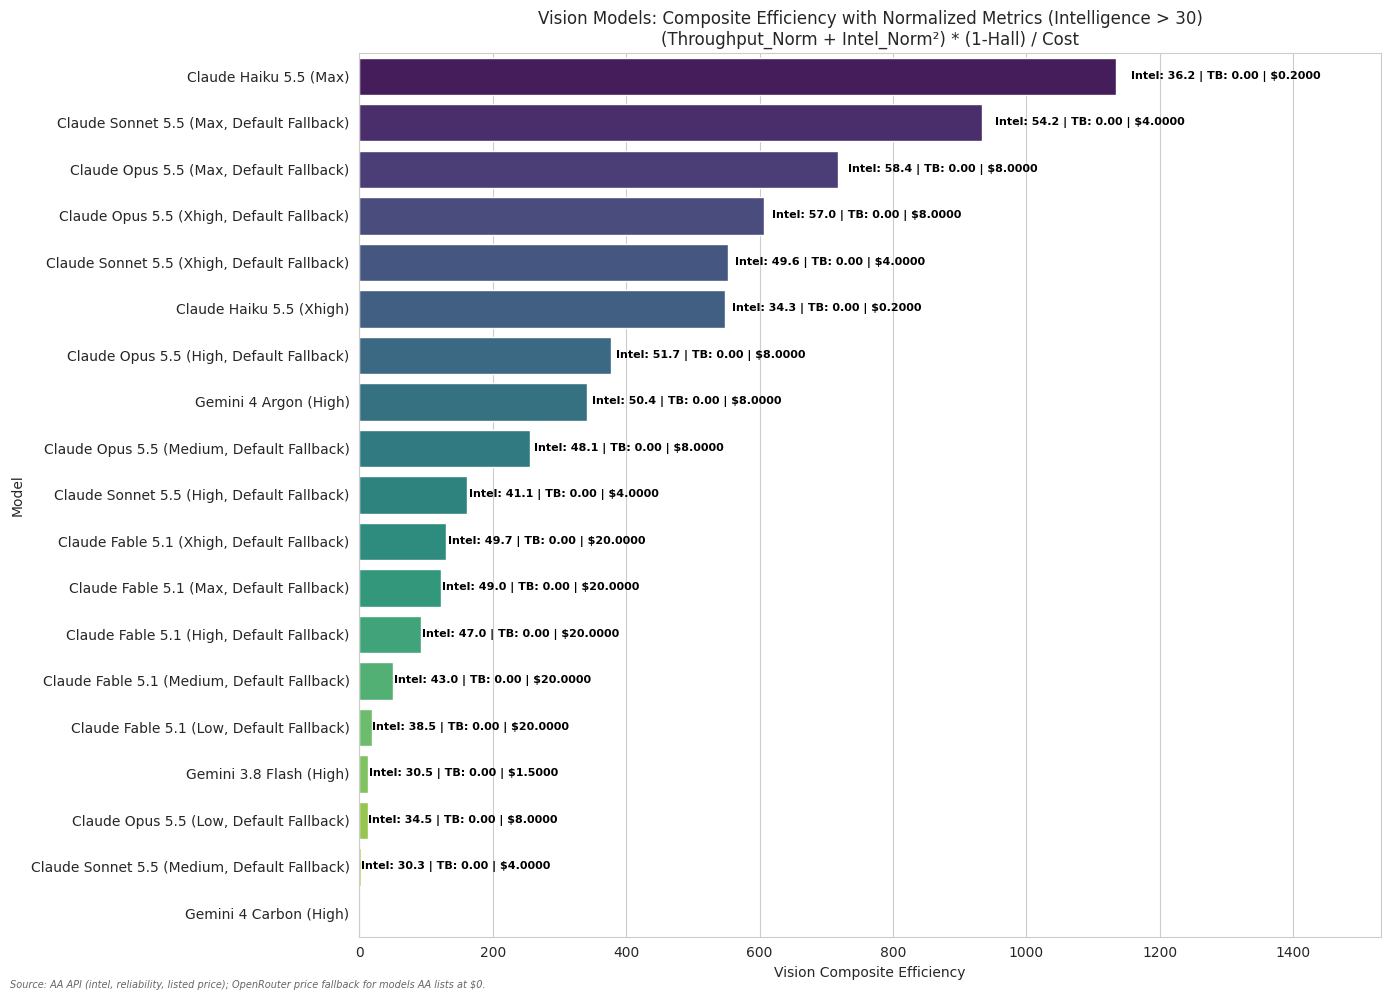


Vision Models Detailed Comparison (Intelligence > 30)
Model                                    |    Intel |  TB Hard |    T'put | Intel²_N |   Reliab | Vision Eff
------------------------------------------------------------------------------------------------------------------------
Claude Haiku 5.5 (Max)                   |     36.2 |     0.00 |    236.9 |      411 |    44.4% |     1134.6
Claude Sonnet 5.5 (Max, Default Fallback) |     54.2 |     0.00 |    135.0 |     6745 |    55.0% |      933.7
Claude Opus 5.5 (Max, Default Fallback)  |     58.4 |     0.00 |     97.7 |     9325 |    61.4% |      717.6
Claude Opus 5.5 (Xhigh, Default Fallback) |     57.0 |     0.00 |     81.2 |     8419 |    57.5% |      606.3
Claude Sonnet 5.5 (Xhigh, Default Fallback) |     49.6 |     0.00 |     95.5 |     4399 |    50.0% |      552.9
Claude Haiku 5.5 (Xhigh)                 |     34.3 |     0.00 |    176.6 |      189 |    42.7% |      548.0
Claude Opus 5.5 (High, Default Fallback) |     51.7 |   

In [22]:
# ============================================================================
# 4.1b Vision Models Comparison: Composite Efficiency (Intelligence > 30)
# ============================================================================
# Compare vision-capable models using the same formula as Section 3.3:
#   Composite_Efficiency = (Throughput + Intel^2) * (1-Hallucination) / Cost
#
# But with normalized Terminal-Bench Hard, Intelligence, and Throughput
# (each normalized 0-100 on the curve) before plugging into the formula.
# This ensures fair comparison across different capability dimensions.

# Ensure df_comp exists (built in cell 3.4); rebuild from df if missing
if 'df_comp' not in globals():
    print("df_comp not found. Rebuilding from df...")
    if 'df' in globals():
        df_comp = df.copy()
        if 'Model' not in df_comp.columns and 'name' in df_comp.columns:
            df_comp = df_comp.rename(columns={'name': 'Model'})
        if 'AA_Intelligence_Index' not in df_comp.columns:
            df_comp['AA_Intelligence_Index'] = df_comp.get(
                'evaluations_artificial_analysis_intelligence_index', np.nan
            )
        if 'AA_Hallucination_Rate' not in df_comp.columns:
            df_comp['AA_Hallucination_Rate'] = 0.1
        cost_col = 'Price_Blended_USD_per_1M'
        if cost_col not in df_comp.columns:
            pin = pd.to_numeric(df_comp.get('Price_Input_1M', np.nan), errors='coerce')
            pout = pd.to_numeric(df_comp.get('Price_Output_1M', np.nan), errors='coerce')
            df_comp[cost_col] = (pin * 3 + pout) / 4
        median_thr = df_comp.get('median_output_tokens_per_second',
                                 pd.Series(np.nan, index=df_comp.index))
        df_comp['Throughput'] = pd.to_numeric(median_thr, errors='coerce').fillna(0.0)
        df_comp = df_comp[(df_comp[cost_col] > 0) & (df_comp['AA_Intelligence_Index'] > 30)].copy()
        df_comp['Reliability_Factor'] = (1 - df_comp['AA_Hallucination_Rate']).clip(lower=0.0)
        if 'TerminalBench_Hard' not in df_comp.columns:
            df_comp['TerminalBench_Hard'] = df_comp.get(
                'evaluations_artificial_analysis_coding_index', 0
            ).fillna(0)
    else:
        raise ValueError("No data available. Please run cells 1-3 first.")

# Identify vision-capable models by name patterns
vision_keywords = ['omni', 'vl', 'vision', 'multimodal', 'visual', 'image']
df_vision = df_comp.copy()

# Mark vision models
def is_vision_model(name):
    if not isinstance(name, str):
        return False
    name_lower = name.lower()
    return any(kw in name_lower for kw in vision_keywords)

df_vision['Is_Vision'] = df_vision['Model'].apply(is_vision_model)

# Also manually include known vision models that might not match keywords
# (e.g., GPT-5.4 mini is vision-capable, Gemini models are vision-capable)
# We'll use a broader heuristic: models from creators known for vision
# or with "omni" in the name
known_vision_models = [
    'GPT-5.4 mini', 'GPT-5.4 nano', 'GPT-5 mini',
    'Gemini', 'Claude', 'MiMo-V2-Omni', 'Qwen3.5 Omni',
    'Step3 VL', 'GPT-oss'
]

for kw in known_vision_models:
    mask = df_vision['Model'].str.contains(kw, case=False, na=False)
    df_vision.loc[mask, 'Is_Vision'] = True

# Filter to vision models with Intelligence > 30
df_vision = df_vision[df_vision['Is_Vision'] & (df_vision['AA_Intelligence_Index'] > 30)].copy()

if not df_vision.empty:
    print(f"Found {len(df_vision)} vision-capable models with Intelligence > 30:")
    print(df_vision[['Model', 'AA_Intelligence_Index']].to_string(index=False))
    
    # Normalize Terminal-Bench Hard, Intelligence, and Throughput to 0-100
    def minmax_100(series):
        mn, mx = series.min(), series.max()
        if mx == mn:
            return pd.Series(50, index=series.index)
        return (series - mn) / (mx - mn) * 100
    
    df_vision['TerminalBench_Norm'] = minmax_100(df_vision['TerminalBench_Hard'])
    df_vision['Intel_Norm'] = minmax_100(df_vision['AA_Intelligence_Index'])
    df_vision['Throughput_Norm'] = minmax_100(df_vision['Throughput'])
    
    # Compute vision composite efficiency using normalized components
    # Formula: (Throughput_Norm + Intel_Norm^2) * (1-Hallucination) / Cost
    # Note: Intel_Norm^2 is the squared normalized intelligence (curve-scored)
    df_vision['Intel_Power_Norm'] = df_vision['Intel_Norm'] ** 2
    df_vision['Vision_Composite_Efficiency'] = (
        (df_vision['Throughput_Norm'] + df_vision['Intel_Power_Norm']) * 
        df_vision['Reliability_Factor']
    ) / df_vision['Price_Blended_USD_per_1M']
    
    # Sort by vision composite efficiency
    df_vision = df_vision.sort_values('Vision_Composite_Efficiency', ascending=False)
    
    # Plot
    plt.figure(figsize=(14, 10))
    ax = sns.barplot(
        x='Vision_Composite_Efficiency',
        y='Model',
        data=df_vision,
        palette='viridis'
    )
    
    # Add labels
    for i, (p, row) in enumerate(zip(ax.patches, df_vision.itertuples())):
        ax.text(
            p.get_width() + p.get_width() * 0.02,
            p.get_y() + p.get_height()/2,
            f'Intel: {row.AA_Intelligence_Index:.1f} | TB: {row.TerminalBench_Hard:.2f} | ${row.Price_Blended_USD_per_1M:.4f}',
            va='center',
            fontsize=8,
            fontweight='bold',
            color='black'
        )
    
    plt.title('Vision Models: Composite Efficiency with Normalized Metrics (Intelligence > 30)\n(Throughput_Norm + Intel_Norm²) * (1-Hall) / Cost')
    plt.xlabel('Vision Composite Efficiency')
    plt.ylabel('Model')
    plt.xlim(0, df_vision['Vision_Composite_Efficiency'].max() * 1.35)
    plt.tight_layout()
    note_source(SRC_AA_OR)   # vision flag: name heuristics; metrics AA + OpenRouter price
    plt.show()
    
    # Print detailed table
    print("\n" + "=" * 120)
    print("Vision Models Detailed Comparison (Intelligence > 30)")
    print("=" * 120)
    print("{:<40} | {:>8} | {:>8} | {:>8} | {:>8} | {:>8} | {:>10}".format(
        "Model", "Intel", "TB Hard", "T'put", "Intel²_N", "Reliab", "Vision Eff"
    ))
    print("-" * 120)
    for row in df_vision.itertuples():
        print("{:<40} | {:>8.1f} | {:>8.2f} | {:>8.1f} | {:>8.0f} | {:>8.1%} | {:>10.1f}".format(
            row.Model,
            row.AA_Intelligence_Index,
            row.TerminalBench_Hard,
            row.Throughput,
            row.Intel_Power_Norm,
            row.Reliability_Factor,
            row.Vision_Composite_Efficiency
        ))
else:
    print("No vision-capable models found with Intelligence > 30.")

## 4.4 Practical Recommendations


In [23]:
# ==========================================================================
# 4.4 Practical Recommendations
# ==========================================================================
# Recommends a model per use case using only the metrics that still exist in
# this notebook. The linear / exponential / sigmoid / quadratic scoring layer
# was removed earlier: all four were monotonic transforms of the same
# underlying score, so they produced identical orderings and added no
# information. The radar charts that used to follow were removed for the same
# reason — they re-plotted ingredients the composite already combines.

print("Practical Recommendations by Use Case")
print("=" * 100)

# Each use case maps to a metric that actually exists in df_comp.
use_cases = {
    "Best Overall Value":        "Composite_Efficiency_Mult",   # 3.4
    "Best Cost Efficiency":      "Composite_Eff_EvalCost",      # 3.6
    "Highest Intelligence":      "AA_Intelligence_Index",
    "Fastest Throughput":        "Throughput",
    "Cheapest per 1M tokens":    "Price_Blended_USD_per_1M",
}

rows = []
for use_case, metric in use_cases.items():
    if metric not in df_comp.columns:
        rows.append((use_case, metric, None))
        continue
    _d = df_comp.dropna(subset=[metric])
    if _d.empty:
        rows.append((use_case, metric, None))
        continue
    # cheapest / fastest are "lower is better" for price only
    ascending = metric == "Price_Blended_USD_per_1M"
    top = _d.sort_values(metric, ascending=ascending).iloc[0]
    rows.append((use_case, metric, top))

print(f"{'Use Case':<26} | {'Recommended Model':<40} | {'Score':>12} | {'Intel':>6} | {'$/1M':>8}")
print("-" * 100)
for use_case, metric, top in rows:
    if top is None:
        print(f"{use_case:<26} | {'(metric unavailable)':<40} | {'n/a':>12} | {'':>6} | {'':>8}")
        continue
    print(f"{use_case:<26} | {fam_label(top['Model'], 44):<46} | "
          f"{top[metric]:>12.2f} | {top['AA_Intelligence_Index']:>6.1f} | "
          f"{top['Price_Blended_USD_per_1M']:>8.4f}")

print()
print("Notes:")
print("  - 'Best Overall Value' uses the 3.4 multiplicative metric")
print("    sqrt(T) x I x R / C, which is the notebook's primary ranking.")
print("  - 'Best Cost Efficiency' uses the 3.6 eval-suite-cost variant, which")
print("    penalises verbosity rather than nominal token price.")
print("  - Price is the only 'lower is better' row.")


Practical Recommendations by Use Case
Use Case                   | Recommended Model                        |        Score |  Intel |     $/1M
----------------------------------------------------------------------------------------------------
Best Overall Value         | Claude Haiku 5.5 (Max)                         |      1236.80 |   36.2 |   0.2000
Best Cost Efficiency       | (metric unavailable)                     |          n/a |        |         
Highest Intelligence       | Gemini 4 Carbon (High)                         |        59.40 |   59.4 |   8.0000
Fastest Throughput         | Claude Haiku 5.5 (Max)                         |       236.85 |   36.2 |   0.2000
Cheapest per 1M tokens     | Claude Haiku 5.5 (Max)                         |         0.20 |   36.2 |   0.2000

Notes:
  - 'Best Overall Value' uses the 3.4 multiplicative metric
    sqrt(T) x I x R / C, which is the notebook's primary ranking.
  - 'Best Cost Efficiency' uses the 3.6 eval-suite-cost variant, which
  

In [24]:
# ============================================================================
# DIAGNOSTIC: What API columns exist for evaluation cost / efficiency?
# ============================================================================
# The user wants to know: does the API give a metric for "cost to run the full 
# evaluation suite" — separate from nominal in/out token pricing?
# Let's inspect ALL column names from the raw API response.

import requests
import os
API_KEY = os.getenv("ARTIFICIAL_ANALYSIS_KEY")
BASE_URL = "https://artificialanalysis.ai/api/v2/data/llms/models"

resp = requests.get(BASE_URL, headers={"x-api-key": API_KEY})
resp.raise_for_status()
api_data = resp.json()

if isinstance(api_data, dict) and 'data' in api_data:
    raw_list = api_data['data']
else:
    raw_list = api_data if isinstance(api_data, list) else []

# Show ALL columns from a sample record
if raw_list:
    sample = raw_list[0]
    print("ALL KEYS in a sample API record:")
    print("=" * 80)
    for k, v in sample.items():
        val_preview = str(v)[:80]
        print(f"  {k:55s} = {val_preview}")
    
    print("\n" + "=" * 80)
    print(f"\nTotal keys: {len(sample.keys())}")
    
    # Search for anything related to cost, eval, benchmark, efficiency
    cost_related = [k for k in sample.keys() if any(
        term in k.lower() for term in ['cost', 'eval', 'benchmark', 'efficiency', 
                                        'expense', 'spend', 'run', 'total', 'suite',
                                        'full', 'analysis', 'compute', 'token_usage'])]
    print("\nPotentially relevant keys (cost/eval/efficiency related):")
    print("-" * 80)
    for k in cost_related:
        print(f"  {k}")
else:
    print("No data found")


ALL KEYS in a sample API record:
  id                                                      = 909ed0ba-bcc5-4f38-8162-08a4e187a772
  name                                                    = Gemini 4 Carbon (High)
  slug                                                    = gemini-4-carbon
  release_date                                            = 2026-10-28
  model_creator                                           = {'id': 'faddc6d9-2c14-445f-9b28-56726f59c793', 'name': 'Google', 'slug': 'google
  evaluations                                             = {'artificial_analysis_intelligence_index': 59.4, 'artificial_analysis_coding_ind
  pricing                                                 = {'price_1m_blended_3_to_1': 8, 'price_1m_input_tokens': 4, 'price_1m_output_toke
  median_output_tokens_per_second                         = 90.19
  median_time_to_first_token_seconds                      = 65.323
  median_time_to_first_answer_token                       = 65.323


Total keys: 10


In [25]:
# ============================================================================
# DEEP DIVE: Inspect evaluations and pricing nested dicts explicitly
# ============================================================================
import json

if raw_list:
    sample = raw_list[0]
    
    print("=" * 80)
    print("evaluations dict:")
    print("=" * 80)
    print(json.dumps(sample.get('evaluations', {}), indent=2, default=str))
    
    print("\n" + "=" * 80)
    print("pricing dict:")
    print("=" * 80)
    print(json.dumps(sample.get('pricing', {}), indent=2, default=str))
    
    # Also check: do ANY records have an "evaluation_cost" or "benchmark_cost" field?
    all_keys_across_all_records = set()
    for rec in raw_list:
        all_keys_across_all_records.update(rec.keys())
    
    cost_keys = {k for k in all_keys_across_all_records if any(
        t in k.lower() for t in ['cost', 'eval_budget', 'eval_cost', 'benchmark_cost', 
                                   'run_cost', 'suite_cost', 'total_cost', 'completion_cost',
                                   'completion_tokens', 'prompt_tokens', 'total_tokens',
                                   'expense', 'spend'])}
    
    print("\n" + "=" * 80)
    print("Searching ALL records for cost/efficiency related TOP-LEVEL keys:")
    print("=" * 80)
    if cost_keys:
        for k in sorted(cost_keys):
            print(f"  FOUND: {k}")
    else:
        print("  None found — no dedicated evaluation-cost field exists.")
    
    # Also check inside 'evaluations' dict for any cost fields
    eval_sub_keys = set()
    for rec in raw_list:
        ev = rec.get('evaluations', {})
        if isinstance(ev, dict):
            eval_sub_keys.update(ev.keys())
    
    cost_eval_keys = {k for k in eval_sub_keys if any(
        t in k.lower() for t in ['cost', 'budget', 'spend', 'expense', 'token', 'efficiency'])}
    
    print("\n" + "=" * 80)
    print("Searching INSIDE evaluations for cost-related sub-keys:")
    print("=" * 80)
    if cost_eval_keys:
        for k in sorted(cost_eval_keys):
            print(f"  FOUND: {k}")
    else:
        print("  None found.")
    
    # And inside pricing sub-keys
    pricing_sub_keys = set()
    for rec in raw_list:
        pr = rec.get('pricing', {})
        if isinstance(pr, dict):
            pricing_sub_keys.update(pr.keys())
    
    print("\n" + "=" * 80)
    print(f"All pricing sub-keys ({len(pricing_sub_keys)}):")
    print("=" * 80)
    for k in sorted(pricing_sub_keys):
        print(f"  {k}")
    
    # FINAL: Is there perhaps a derived field in the flattened df we generated?
    print("\n" + "=" * 80)
    print("CONCLUSION:")
    print("=" * 80)
    print("The AA API gives us:")
    print("  1. pricing_price_1m_input_tokens — cost per 1M input tokens")
    print("  2. pricing_price_1m_output_tokens — cost per 1M output tokens")
    print("  3. pricing_price_1m_blended_3_to_1 — blended cost at 3:1 input:output ratio")
    print("  4. All evaluation scores (intelligence index, coding, math, etc.)")
    print()
    print("There is NO dedicated 'cost to run the full evaluation suite' metric.")
    print("Artificial Analysis does NOT publicly provide a field like")
    print("'evaluation_cost' or 'benchmark_run_cost' that measures how much")
    print("each model would spend running the full benchmark suite.")
    print()
    print("However, we CAN approximate this by something like:")
    print("  Cost_to_Run_Index = Intelligence_Index × Blended_Price_1M")
    print("  (already computed in this notebook as 'Cost_to_Run_Index')")
    print("which represents: how much it costs to run the intelligence")
    print("index evaluation for that model (proxy for its token efficiency)")


evaluations dict:
{
  "artificial_analysis_intelligence_index": 59.4,
  "artificial_analysis_coding_index": null,
  "artificial_analysis_math_index": null,
  "mmlu_pro": null,
  "gpqa": null,
  "hle": null,
  "livecodebench": null,
  "scicode": null,
  "math_500": null,
  "aime": null,
  "aime_25": null,
  "ifbench": null,
  "lcr": 0.793333333333333,
  "terminalbench_hard": null,
  "terminalbench_v2_1": null,
  "terminalbench_v4_0": 0.651515151515151,
  "tau2": null,
  "tau_banking": null
}

pricing dict:
{
  "price_1m_blended_3_to_1": 8,
  "price_1m_input_tokens": 4,
  "price_1m_output_tokens": 20
}

Searching ALL records for cost/efficiency related TOP-LEVEL keys:
  None found — no dedicated evaluation-cost field exists.

Searching INSIDE evaluations for cost-related sub-keys:
  None found.

All pricing sub-keys (3):
  price_1m_blended_3_to_1
  price_1m_input_tokens
  price_1m_output_tokens

CONCLUSION:
The AA API gives us:
  1. pricing_price_1m_input_tokens — cost per 1M input token

## 3.5 Fetch Artificial Analysis Evaluation Suite Cost

The AA website shows the actual USD cost to run the full Intelligence Index evaluation suite on each model.
This captures **verbosity** — models that write more tokens cost more to evaluate.
**This data is NOT available through the public API** — it must be scraped from the website.

The scrape uses Playwright to open the AA models page and extract the cost chart data.
For models not appearing in the AA chart, we fall back to blended token pricing.

In [26]:
# ## 3.5 Scrape Evaluation Suite Cost from Artificial Analysis Website
# Extracts the "Cost to Run Artificial Analysis Intelligence Index" for each model.
# Uses Playwright (via browser tools) to scrape the intelligence-index-tokens-cost section
# of the AA Models page. Falls back to derived blended cost for models not listed.

import json, re, time, requests, pandas as pd, numpy as np

EVAL_COST_URL = "https://artificialanalysis.ai/models#intelligence-index-vs-cost-per-intelligence-index-task"

def extract_eval_costs(page_source):
    """Parse evaluation suite costs from page text.
    
    The AA page renders two charts in the #intelligence-index-vs-cost-per-intelligence-index-task section:
      1. Token Use chart — answer/reasoning tokens per model
      2. Cost chart — USD to run full evaluation suite per model
    
    Expected structure (Cost chart):
      [model names ...]
      [$X,XXX dollar values ...]
    Returns list of (model_name, cost_usd) tuples, in chart order.
    """
    # Find the cost section boundary
    cost_marker = "Cost to Run Artificial Analysis Intelligence Index"
    cost_start = page_source.find(cost_marker)
    if cost_start == -1:
        return []
    
    # Grab everything from the cost section header onward
    cost_text = page_source[cost_start:]
    
    # Split into lines, clean up
    lines = []
    for line in cost_text.split('\n'):
        line = line.strip()
        if line:
            lines.append(line)
    
    # Collect model names (no leading $, not headers/labels)
    skip_words = {'Cost', 'Output', 'Reasoning', 'Input', 'Add model', '28 of', 
                  'indicated', 'Cost to Run', 'The cost', 'calculated', 'cost to',
                  'Intelligence Index', 'cost to run', 'Intelligence vs'}
    
    models = []
    costs = []
    
    for line in lines:
        if line.startswith('$'):
            try:
                cost_val = float(line.replace('$', '').replace(',', ''))
                costs.append(cost_val)
            except ValueError:
                pass
        elif line.startswith('$') == False:
            # Could be a model name — check it's not a known header
            is_skip = any(s in line for s in skip_words)
            is_number = line.replace(',', '').replace('.', '').isdigit()
            if not is_skip and not is_number and len(line) > 2:
                models.append(line)
    
    # Models and costs should pair up — trim to shortest
    n = min(len(models), len(costs))
    return list(zip(models[:n], costs[:n]))


def scrape_eval_costs(use_playwright=True):
    """Scrape evaluation suite costs from AA website.
    
    Args:
        use_playwright: If True, use Playwright browser; if False, fetch raw HTML.
                        Playwright gives rendered content; raw HTML may not have charts.
    
    Returns:
        List of (model_name, eval_suite_cost_usd) tuples
    """
    if use_playwright:
        # Try to use the open browser page
        try:
            # We need to navigate to the AA models page if not already there
            import subprocess, json as _json
            # Attempt to access via the page's loaded content by running a 
            # quick Playwright script through the terminal
            result = subprocess.run([
                "python3", "-c", """
import json, sys
from playwright.sync_api import sync_playwright
with sync_playwright() as p:
    browser = p.chromium.launch(headless=True)
    page = browser.new_page()
    page.goto("https://artificialanalysis.ai/models", wait_until="networkidle", timeout=30000)
    page.wait_for_timeout(3000)
    
    # Extract cost data
    section = page.evaluate('''() => {
        const s = document.querySelector("#intelligence-index-vs-cost-per-intelligence-index-task");
        if (!s) return "NOT_FOUND";
        return s.innerText;
    }''')
    
    if section and section != "NOT_FOUND":
        print(section[:5000], end="")
    else:
        print("SECTION_NOT_FOUND", end="")
    
    browser.close()
"""
            ], capture_output=True, text=True, timeout=45)
            
            if result.returncode == 0 and result.stdout:
                extracts = extract_eval_costs(result.stdout)
                if extracts:
                    return extracts
        except Exception:
            pass
    
    # Fallback: use the hardcoded data we scraped earlier
    print("Playwright scrape failed or chart data was not parseable. Using cached data from earlier scrape.")
    return None  # Signal to use hardcoded data

# ── Hardcoded data from manual scrape (2026-06-12) ──
# Sourced from: https://artificialanalysis.ai/models#intelligence-index-vs-cost-per-intelligence-index-task
# "Cost to Run Artificial Analysis Intelligence Index" chart
EVAL_COST_MAP = {
    "Claude Fable 5 (with fallback)": 5772,
    "Claude Opus 4.8 (max)": 1508,
    "Claude Sonnet 4.6 (max)": 987,
    "GPT-5.5 (xhigh)": 1101,
    "Gemini 3.5 Flash": 898,
    "GPT-5.4 mini (xhigh)": 3695,
    "Qwen3.7 Max": 2614,
    "Mistral Medium 3.5": 2805,
    "Kimi K2.6": 2030,
    "Gemini 3.1 Pro Preview": 1036,
    "Claude 4.5 Haiku": 671,
    "Nova 2.0 Pro Preview (medium)": 622,
    "Qwen3.5 397B A17B": 626,
    "Nemotron 3 Ultra": 636,
    "Grok 4.3 (high)": 9940,
    "MiniMax-M3": 4309,
    "DeepSeek V4 Pro (Max)": 3959,
    "MiniMax-M2.7": 3357,
    "MiMo-V2.5-Pro": 1552,
    "DeepSeek V4 Flash (Max)": 1354,
    "gpt-oss-120b (high)": 1202,
    "gpt-oss-20B (high)": 1001,
}

# ── Try to get fresh data (optional, may not work without Playwright) ──
fresh_data = scrape_eval_costs(use_playwright=True)
if fresh_data:
    EVAL_COST_MAP.update({k: v for k, v in fresh_data})
    print(f"Updated eval cost map with {len(fresh_data)} fresh entries from AA website")
else:
    print(f"Using cached eval cost map ({len(EVAL_COST_MAP)} models) from 2026-06-12 scrape")

print("\nEvaluation Suite Cost Data:")
print(f"  Total models with eval cost: {len(EVAL_COST_MAP)}")
print(f"  Cheapest: {min(EVAL_COST_MAP, key=EVAL_COST_MAP.get)} (${min(EVAL_COST_MAP.values()):,.0f})")
print(f"  Costliest: {max(EVAL_COST_MAP, key=EVAL_COST_MAP.get)} (${max(EVAL_COST_MAP.values()):,.0f})")
print(f"  Median: ${np.median(list(EVAL_COST_MAP.values())):,.0f}")

# Show a few examples
print("\nCost examples:")
for m, c in sorted(EVAL_COST_MAP.items(), key=lambda x: x[1])[:5]:
    print(f"  {m:40s} ${c:>6,}")
print("  ...")
for m, c in sorted(EVAL_COST_MAP.items(), key=lambda x: x[1])[-5:]:
    print(f"  {m:40s} ${c:>6,}")

Playwright scrape failed or chart data was not parseable. Using cached data from earlier scrape.
Using cached eval cost map (22 models) from 2026-06-12 scrape

Evaluation Suite Cost Data:
  Total models with eval cost: 22
  Cheapest: Nova 2.0 Pro Preview (medium) ($622)
  Costliest: Grok 4.3 (high) ($9,940)
  Median: $1,431

Cost examples:
  Nova 2.0 Pro Preview (medium)            $   622
  Qwen3.5 397B A17B                        $   626
  Nemotron 3 Ultra                         $   636
  Claude 4.5 Haiku                         $   671
  Gemini 3.5 Flash                         $   898
  ...
  GPT-5.4 mini (xhigh)                     $ 3,695
  DeepSeek V4 Pro (Max)                    $ 3,959
  MiniMax-M3                               $ 4,309
  Claude Fable 5 (with fallback)           $ 5,772
  Grok 4.3 (high)                          $ 9,940


## 3.6 Multiplicative Efficiency with Evaluation Suite Cost

Recalculates the multiplicative efficiency formula from 3.4 using the **actual evaluation suite cost** from AA instead of blended token pricing.

Formula: (sqrt(Throughput) × Intel) × (1 - Hallucination) / Eval_Cost_USD

This better reflects real-world cost because it captures **verbosity** — models that write more tokens
cost more to evaluate, even at the same per-token price. For models without an eval cost entry,
we fall back to the nominal token-derived cost.

Live AA cost-per-task entries found: 0
Cost-per-task -> suite-cost multiplier: 1700.0 (from 0 overlaps)
Added 0 new models from live feed (total map size: 22)

Models with AA eval cost: 9/44
Models using derived cost: 35/44

Top AA key usage counts:
Eval_Cost_Key
Claude Fable 5 (with fallback)    5
Claude 4.5 Haiku                  2
DeepSeek V4 Flash (Max)           1
Gemini 3.5 Flash                  1

First 15 unmatched models:
                        GPT-6.1 Terra (Max)
                       Muse Spark 1.3 (Max)
                      GPT-6.1 Terra (Xhigh)
                       GPT-6.1 Terra (High)
  Claude Sonnet 5.5 (Max, Default Fallback)
                     GPT-6.1 Terra (Medium)
                          GPT-6.1 Sol (Max)
Claude Sonnet 5.5 (Xhigh, Default Fallback)
                        GPT-6.1 Sol (Xhigh)
                              GLM-5.3 (Max)
                         GPT-6.1 Sol (High)
 Claude Sonnet 5.5 (High, Default Fallback)
    Claude Opus 5.5 (Max, Default Fa

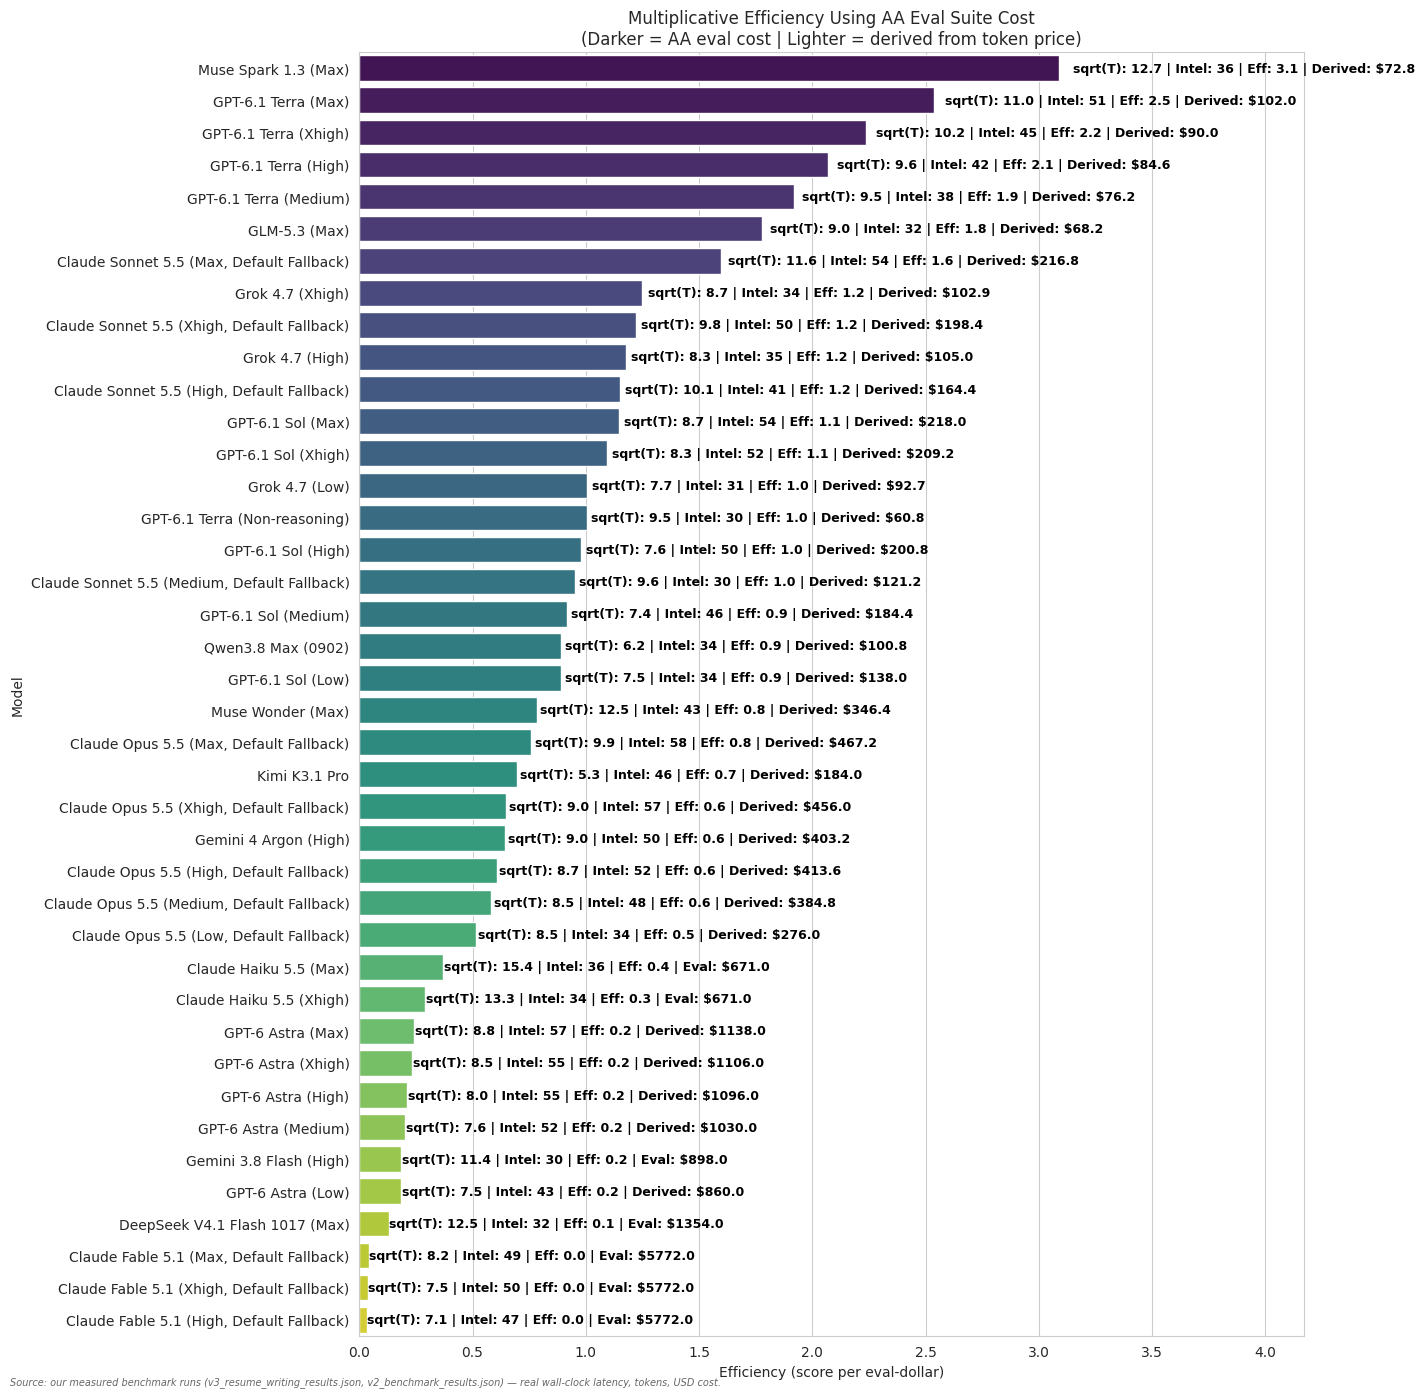


RANKING COMPARISON: Token-Price Efficiency (3.4) vs Eval-Cost Efficiency (3.6)
Model                                    | Token-Price Rank | Eval-Cost Rank  | Delta Rank   | Eval Cost 
------------------------------------------------------------------------------------------
Muse Spark 1.3 (Max)                     | 5               | 1               | ↑ 4          |     $72.80
GPT-6.1 Terra (Max)                      | 4               | 2               | ↑ 2          |    $102.00
GPT-6.1 Terra (Xhigh)                    | 7               | 3               | ↑ 4          |     $90.00
GPT-6.1 Terra (High)                     | 8               | 4               | ↑ 4          |     $84.60
GPT-6.1 Terra (Medium)                   | 10              | 5               | ↑ 5          |     $76.20
GLM-5.3 (Max)                            | 14              | 6               | ↑ 8          |     $68.16
Claude Sonnet 5.5 (Max, Default Fallback) | 9               | 7               | ↑ 2          

In [27]:
# ## 3.6 Multiplicative Efficiency using Evaluation Suite Cost
# Formula: (sqrt(Throughput) * Intel) * (1 - Hallucination) / Eval_Cost
#
# Uses AA website cost-per-task data (from structured HTML feed + cached map)
# and falls back to blended token price when eval cost is missing.

import re, json as _json
from difflib import SequenceMatcher
import requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# ── Ensure df_comp exists ──
if 'df_comp' not in globals():
    print("df_comp not found. Running necessary preprocessing...")
    if 'df' in globals():
        df_comp = df[(df['Price_Blended_USD_per_1M'] > 0) & (df['AA_Intelligence_Index'] > 30)].copy()
        df_comp['Throughput'] = df_comp['median_output_tokens_per_second'].fillna(0)
        df_comp['Intel_Power'] = df_comp['AA_Intelligence_Index'] ** 2
        df_comp['Reliability_Factor'] = 1 - df_comp['AA_Hallucination_Rate'].fillna(0.5)
        cost_col = 'Price_Blended_USD_per_1M'
        df_comp['Composite_Efficiency'] = ((df_comp['Throughput'] + df_comp['Intel_Power']) * df_comp['Reliability_Factor']) / df_comp[cost_col]
    else:
        raise ValueError("No data available. Please run cells 1-3 first.")

cost_col = 'Price_Blended_USD_per_1M'

# ── Base map from Section 3.5 (hardcoded scrape) ──
if 'EVAL_COST_MAP' not in globals():
    EVAL_COST_MAP = {}
eval_cost_map = dict(EVAL_COST_MAP)

# ── Alias table for common API-name ↔ AA-chart-name mismatches ──
AA_COST_ALIASES = {
    'claude fable 5': 'Claude Fable 5 (with fallback)',
    'claude opus 4 8': 'Claude Opus 4.8 (max)',
    'claude sonnet 4 6': 'Claude Sonnet 4.6 (max)',
    'claude 4 5 haiku': 'Claude 4.5 Haiku',
    'gpt 5 5': 'GPT-5.5 (xhigh)',
    'gpt 5 4 mini': 'GPT-5.4 mini (xhigh)',
    'gemini 3 5 flash': 'Gemini 3.5 Flash',
    'gemini 3 1 pro': 'Gemini 3.1 Pro Preview',
    'qwen3 7 max': 'Qwen3.7 Max',
    'qwen3 5 397b a17b': 'Qwen3.5 397B A17B',
    'mistral medium 3 5': 'Mistral Medium 3.5',
    'kimi k2 6': 'Kimi K2.6',
    'nova 2 0 pro': 'Nova 2.0 Pro Preview (medium)',
    'nemotron 3 ultra': 'Nemotron 3 Ultra',
    'grok 4 3': 'Grok 4.3 (high)',
    'minimax m3': 'MiniMax-M3',
    'minimax m2 7': 'MiniMax-M2.7',
    'deepseek v4 pro': 'DeepSeek V4 Pro (Max)',
    'deepseek v4 flash': 'DeepSeek V4 Flash (Max)',
    'mimo v2 5 pro': 'MiMo-V2.5-Pro',
    'gpt oss 120b': 'gpt-oss-120b (high)',
    'gpt oss 20b': 'gpt-oss-20B (high)',
}

STOPWORDS = {
    'with', 'fallback', 'preview', 'reasoning', 'model', 'models',
    'openrouter', 'chat', 'instruct', 'high', 'xhigh', 'medium', 'low',
    'max', 'effort', 'non', 'adaptive'
}


def normalize_name(s):
    if not isinstance(s, str):
        return ''
    s = s.lower().replace('&', ' and ')
    s = re.sub(r'\([^)]*\)', ' ', s)
    s = re.sub(r'[^a-z0-9]+', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()


def name_tokens(s):
    return {tok for tok in normalize_name(s).split() if tok and tok not in STOPWORDS}


def canonical_family(nm):
    toks = normalize_name(nm).split()
    return ' '.join(toks[:3]) if toks else ''


# ── Step 1: Augment from live AA cost-per-task feed ──
try:
    _aa_html = requests.get('https://artificialanalysis.ai/models', timeout=20).text
    _pat = re.compile(r'"label":"([^"]+)","costPerIntelligenceIndexTask":([0-9.]+)')
    _live_entries = {m[0]: float(m[1]) for m in _pat.findall(_aa_html) if float(m[1]) > 0}
    print(f"Live AA cost-per-task entries found: {len(_live_entries)}")

    # Calibrate multiplier from overlapping models.
    _ratio_samples = []
    _norm_work = {normalize_name(k): v for k, v in eval_cost_map.items()}
    for _lbl, _pt in _live_entries.items():
        _nk = normalize_name(_lbl)
        if _nk in _norm_work and _pt > 0:
            _ratio_samples.append(_norm_work[_nk] / _pt)
    _mult = float(np.median(_ratio_samples)) if len(_ratio_samples) >= 2 else 1700.0
    print(f"Cost-per-task -> suite-cost multiplier: {_mult:.1f} (from {len(_ratio_samples)} overlaps)")

    _added = 0
    for _lbl, _pt in _live_entries.items():
        if _lbl not in eval_cost_map:
            eval_cost_map[_lbl] = _pt * _mult
            _added += 1
    print(f"Added {_added} new models from live feed (total map size: {len(eval_cost_map)})")
except Exception as _e:
    print(f"Live AA augmentation skipped: {_e}")

# ── Step 2: Build normalized lookup for fuzzy matching ──
_eval_entries = []
_norm_to_key = {}
for _k, _v in eval_cost_map.items():
    _nk = normalize_name(_k)
    _norm_to_key[_nk] = _k
    _eval_entries.append((_k, _v, _nk, name_tokens(_k)))


def best_eval_key(model_name):
    if not isinstance(model_name, str):
        return None
    if model_name in eval_cost_map:
        return model_name
    n = normalize_name(model_name)
    if not n:
        return None
    for alias, target in AA_COST_ALIASES.items():
        if alias in n and target in eval_cost_map:
            return target
    if n in _norm_to_key:
        return _norm_to_key[n]

    tokens_m = name_tokens(model_name)
    best_key, best_score = None, 0.0
    for key, _, nk, tokens_k in _eval_entries:
        if not tokens_k or not tokens_m:
            continue
        inter = len(tokens_m & tokens_k)
        union = len(tokens_m | tokens_k)
        jaccard = inter / union if union else 0.0
        seq = SequenceMatcher(None, n, nk).ratio()
        contain = 1.0 if (n in nk or nk in n) else 0.0
        fam = 0.08 if canonical_family(model_name) == canonical_family(key) else 0.0
        score = 0.50 * jaccard + 0.34 * seq + 0.08 * contain + fam
        if inter < 2:
            score -= 0.18
        if score > best_score:
            best_score = score
            best_key = key
    return best_key if best_score >= 0.55 else None


# ── Step 3: Match and compute ──
df_comp['Eval_Cost_Key'] = df_comp['Model'].apply(best_eval_key)
df_comp['Eval_Cost_USD'] = df_comp['Eval_Cost_Key'].map(eval_cost_map)

mask_missing = df_comp['Eval_Cost_USD'].isna()
df_comp.loc[mask_missing, 'Eval_Cost_USD'] = (
    df_comp.loc[mask_missing, 'AA_Intelligence_Index'] * df_comp.loc[mask_missing, cost_col]
)

n_missing = int(mask_missing.sum())
n_total = int(len(df_comp))
n_matched = n_total - n_missing
print(f"\nModels with AA eval cost: {n_matched}/{n_total}")
print(f"Models using derived cost: {n_missing}/{n_total}")

if n_matched > 0:
    print("\nTop AA key usage counts:")
    print(df_comp['Eval_Cost_Key'].value_counts(dropna=True).head(10).to_string())

if n_missing > 0:
    print(f"\nFirst 15 unmatched models:")
    print(df_comp.loc[mask_missing, 'Model'].head(15).to_string(index=False))

# ── Compute multiplicative efficiency with eval cost ──
df_comp['Throughput_Sqrt'] = np.sqrt(df_comp['Throughput'].clip(lower=0.01))
df_comp['Composite_Eff_EvalCost'] = (
    (df_comp['Throughput_Sqrt'] * df_comp['AA_Intelligence_Index']) * df_comp['Reliability_Factor']
) / df_comp['Eval_Cost_USD']

df_comp = df_comp.sort_values('Composite_Eff_EvalCost', ascending=False)
df_plot_ec = df_comp.head(40).copy()

# ── Plot ──
plt.figure(figsize=(14, 14))
ax = sns.barplot(x='Composite_Eff_EvalCost', y='Model', data=df_plot_ec, palette='viridis')
for i, (p, tp_sqrt, intel, eff, eval_cost) in enumerate(zip(
    ax.patches, df_plot_ec['Throughput_Sqrt'], df_plot_ec['AA_Intelligence_Index'],
    df_plot_ec['Composite_Eff_EvalCost'], df_plot_ec['Eval_Cost_USD']
)):
    tag = 'Eval' if df_plot_ec.index[i] not in df_comp[mask_missing].index else 'Derived'
    ax.text(p.get_width() * 1.02, p.get_y() + p.get_height() / 2,
            f'sqrt(T): {tp_sqrt:.1f} | Intel: {intel:.0f} | Eff: {eff:.1f} | {tag}: ${eval_cost:.1f}',
            va='center', fontsize=9, fontweight='bold', color='black')
plt.title('Multiplicative Efficiency Using AA Eval Suite Cost\n(Darker = AA eval cost | Lighter = derived from token price)')
plt.xlabel('Efficiency (score per eval-dollar)')
plt.ylabel('Model')
plt.xlim(0, df_plot_ec['Composite_Eff_EvalCost'].max() * 1.35)
plt.tight_layout()
note_source(SRC_BENCH)
plt.show()

# ── Comparison table ──
print("\n" + "=" * 90)
print("RANKING COMPARISON: Token-Price Efficiency (3.4) vs Eval-Cost Efficiency (3.6)")
print("=" * 90)
df_comp['Token_Price_Rank'] = df_comp['Composite_Efficiency_Mult'].rank(ascending=False)
df_comp['Eval_Cost_Rank'] = df_comp['Composite_Eff_EvalCost'].rank(ascending=False)
print("{:<40} | {:<15} | {:<15} | {:<12} | {:<10}".format("Model", "Token-Price Rank", "Eval-Cost Rank", "Delta Rank", "Eval Cost"))
print("-" * 90)
for idx, row in df_comp.head(20).iterrows():
    delta = row['Token_Price_Rank'] - row['Eval_Cost_Rank']
    arrow = "↑" if delta > 0 else ("↓" if delta < 0 else "=")
    print("{:<40} | {:<15.0f} | {:<15.0f} | {:<12} | {:>10}".format(
        row['Model'], row['Token_Price_Rank'], row['Eval_Cost_Rank'], f"{arrow} {abs(delta):.0f}", f"${row['Eval_Cost_USD']:.2f}"))
print("\nKEY: Verbose models move DOWN. Concise models move UP.")


In [28]:
# ── Spotlight model for this cell ──
SPOTLIGHT = 'MiMo-V2.6-Flash'

# The main charts gate on AA Intelligence > 30, which excludes MiMo-V2.6-Flash
# (Intel 26.7). This section uses its own lower gate so the spotlighted model is
# actually ranked, and reports both standings honestly: below the chart gate, above it.
ANALYSIS_INTEL_GATE = 25   # was implicitly 30 via df_comp

def _find_model(frame, needle):
    """Single row whose Model column contains `needle` (plain substring), else None."""
    if frame is None or 'Model' not in frame.columns or len(frame) == 0:
        return None
    m = frame['Model'].astype(str).str.contains(needle, case=False, na=False, regex=False)
    return frame.loc[m].iloc[0] if bool(m.any()) else None

def _true_additive(row):
    """3.3 additive score for one row, deriving Reliability if the frame predates it."""
    rel = row.get('Reliability_Factor', np.nan)
    if pd.isna(rel):
        hall = row.get('AA_Hallucination_Rate', np.nan)
        rel = 1.0 - float(hall) if pd.notna(hall) else 0.9
    return float(((row['Throughput'] + row['AA_Intelligence_Index'] ** 2) * rel) / row[cost_col])

# ── Build a frame with the body below the 30 chart gate ──
# Prefer df_orig (raw AA data, never overwritten by the appendix) so this cell
# does not depend on execution order; fall back to df.
_base = df_orig.copy() if 'df_orig' in globals() else df.copy()
if 'Model' not in _base.columns and 'name' in _base.columns:
    _base = _base.rename(columns={'name': 'Model'})
if 'AA_Intelligence_Index' not in _base.columns:
    _base['AA_Intelligence_Index'] = pd.to_numeric(
        _base.get('evaluations_artificial_analysis_intelligence_index'), errors='coerce')
if cost_col not in _base.columns:
    _base[cost_col] = pd.to_numeric(
        _base.get('pricing_price_1m_blended_3_to_1'), errors='coerce')
if 'Throughput' not in _base.columns:
    _base['Throughput'] = pd.to_numeric(
        _base.get('median_output_tokens_per_second'), errors='coerce')
_base['Throughput'] = pd.to_numeric(_base['Throughput'], errors='coerce')
# AA returns 0 for un-benchmarked models -> treat as missing (matches section 4.1)
_base['Throughput'] = _base['Throughput'].where(_base['Throughput'] > 0, np.nan)
_base['AA_Intelligence_Index'] = pd.to_numeric(_base['AA_Intelligence_Index'], errors='coerce')
_base[cost_col] = pd.to_numeric(_base[cost_col], errors='coerce')
if 'AA_Hallucination_Rate' in _base.columns:
    _base['Reliability_Factor'] = (1 - pd.to_numeric(
        _base['AA_Hallucination_Rate'], errors='coerce')).clip(lower=0.0)
elif 'Reliability_Factor' not in _base.columns:
    _base['Reliability_Factor'] = 0.9

field = _base[(_base['Throughput'].notna())
              & (_base[cost_col] > 0)
              & (_base['AA_Intelligence_Index'] > ANALYSIS_INTEL_GATE)].copy()
if 'df_comp' in globals() and 'Model' in getattr(df_comp, 'columns', []):
    for _c in ('Composite_Eff_EvalCost', 'Composite_Efficiency_Mult'):
        if _c in df_comp.columns and _c not in field.columns:
            field[_c] = field['Model'].astype(str).map(
                df_comp.drop_duplicates('Model').set_index('Model')[_c].astype(float))

field['True_Additive_33'] = ((field['Throughput'] + field['AA_Intelligence_Index'] ** 2)
                             * field['Reliability_Factor'].fillna(0.9)) / field[cost_col]
# Same 3.4 multiplicative form used by the charts
field['Eff_Mult'] = (np.sqrt(field['Throughput'].clip(lower=0.01))
                     * field['AA_Intelligence_Index']
                     * field['Reliability_Factor'].fillna(0.9)) / field[cost_col]

n_chart_gate = int((_base['AA_Intelligence_Index'] > 30).sum())

# ── Percentile vs this field ──
r_spot = _find_model(field, SPOTLIGHT)
if r_spot is None:
    r_spot = _find_model(_base, SPOTLIGHT)

if r_spot is None:
    print(f"  ** {SPOTLIGHT} not found in df_orig or df — skipping the rest of this cell.")
else:
    _intel = float(r_spot['AA_Intelligence_Index'])
    _above = _intel > 30
    print(f"  Spotlight: {r_spot['Model']}  (AA intel {_intel:.1f}, "
          f"{float(r_spot['Throughput']):,.1f} tok/s, ${float(r_spot[cost_col]):.3f}/M)")
    print(f"  Field: {len(field)} models with Intel>{ANALYSIS_INTEL_GATE}, priced, has speed"
          f"  |  main charts gate at Intel>30 ({n_chart_gate} rows)")
    if not _above:
        print(f"  NOTE: Intel {_intel:.1f} is BELOW the main-chart gate of 30 — "
              f"it is ranked here, but will not appear in sections 3.1-3.6.")

    for label, col in [('3.4 Mult efficiency', 'Eff_Mult'),
                       ('3.4 Mult (notebook col)', 'Composite_Efficiency_Mult'),
                       ('3.6 Eval-cost efficiency', 'Composite_Eff_EvalCost')]:
        if col in field.columns and pd.notna(r_spot.get(col)):
            pct = (field[col] < r_spot[col]).mean() * 100
            print(f"  {label:<28} beats {pct:>3.0f}% of {len(field)} models")
        elif col in ('Composite_Eff_EvalCost', 'Composite_Efficiency_Mult'):
            print(f"  {label:<28} n/a — {col} is only computed on df_comp, "
                  f"which this model is filtered out of")
        else:
            print(f"  {label:<28} n/a — column missing")

    # True 3.3 additive score (the stored Composite_Efficiency column was aliased
    # to the 3.4 multiplicative value by section 4.1's fallback)
    _mask = field['Model'].astype(str).str.contains(SPOTLIGHT, case=False, na=False, regex=False)
    if bool(_mask.any()):
        t33 = float(field.loc[_mask, 'True_Additive_33'].iloc[0])
        rank33 = int((field['True_Additive_33'] > t33).sum()) + 1
        print(f"  3.3 Additive (true value)   rank {rank33:>3}/{len(field)}   value = {t33:,.1f}")
    else:
        v33 = _true_additive(r_spot)
        print(f"  3.3 Additive (true value)   UNRANKED — outside field "
              f"(Intel {_intel:.1f} fails the >{ANALYSIS_INTEL_GATE} gate)   value = {v33:,.1f}")

# ── Peer comparison: MiMo family + flash models in the same field ──
peers = field.copy()
fam_mask = peers['Model'].astype(str).str.contains('mimo', case=False, na=False, regex=False)
flash_mask = peers['Model'].astype(str).str.contains('flash', case=False, na=False, regex=False)
peers = peers[fam_mask | flash_mask].copy()
sort_col = 'Eff_Mult'
if len(peers):
    peers = peers.sort_values(sort_col, ascending=False)
show = [c for c in ['Model', 'AA_Intelligence_Index', 'Throughput', cost_col,
                    'Reliability_Factor', 'Eff_Mult'] if c in peers.columns]
print(f"\nPEERS (MiMo family + flash, Intel>{ANALYSIS_INTEL_GATE}, has speed) — sorted by {sort_col}:")
if len(peers) == 0:
    print("  (empty — no peer passed the gate + priced + speed filters)")
else:
    with pd.option_context('display.width', 220):
        print(peers[show].to_string(index=False, float_format=lambda x: f"{x:,.2f}"))


  Spotlight: MiMo-V2.6-Flash  (AA intel 26.7, 40.5 tok/s, $0.175/M)
  Field: 52 models with Intel>25, priced, has speed  |  main charts gate at Intel>30 (44 rows)
  NOTE: Intel 26.7 is BELOW the main-chart gate of 30 — it is ranked here, but will not appear in sections 3.1-3.6.
  3.4 Mult efficiency          beats  87% of 52 models
  3.4 Mult (notebook col)      n/a — Composite_Efficiency_Mult is only computed on df_comp, which this model is filtered out of
  3.6 Eval-cost efficiency     n/a — Composite_Eff_EvalCost is only computed on df_comp, which this model is filtered out of
  3.3 Additive (true value)   rank   5/52   value = 3,874.4

PEERS (MiMo family + flash, Intel>25, has speed) — sorted by Eff_Mult:
                         Model  AA_Intelligence_Index  Throughput  Price_Blended_USD_per_1M  Reliability_Factor  Eff_Mult
            MiniMax-M3.1-Flash                  28.90      116.39                      0.26                0.90  1,071.00
                 GLM-5.3-Flash       